In [1]:
## a useful function to generate a data list for further analysis
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from curate_trackball_database import create_curated_dataset
from analyse_stimulus_evoked_response import main

Transition indices: [2 4 7]


In [2]:
##need to add this additional cell because useful tools are in another folder. Need to integrate these two folders one day
import sys
sys.path.insert(0, 'C:/Users/neuroPC/Documents/GitHub/behavioral_analysis')
from useful_tools import select_animals_gpt

Session 0.1: Load analysis methods in python dictionary form

In [3]:
json_file = "./analysis_methods_dictionary.json"
with open(json_file, "r") as f:
    analysis_methods = json.loads(f.read())
    
sheet_name="VCCball"
Datasets="Z:/DATA/experiment_trackball_Optomotor"
thisDataset = f"{Datasets}/{sheet_name}"

In [ ]:
analysis_methods.update({"experiment_name": "long_densities"})
analysis_methods.update({"stim_duration": 60})
analysis_methods.update({"interval_duration": 60})

In [4]:
analysis_methods.update({"experiment_name": "densities"})
analysis_methods.update({"stim_duration": 25})
analysis_methods.update({"interval_duration": 5})

In [57]:
analysis_methods.update({"plotting_optomotor_response": True})
analysis_methods.update({"plotting_deceleration_accerleration": False})
#analysis_methods.update({"plotting_tbt_overview": True})

In [5]:
analysis_methods

{'experiment_name': 'densities',
 'overwrite_curated_dataset': True,
 'graph_colour_code': ['r', 'y', 'm', 'c', 'k', 'b', 'g', 'r'],
 'debug_mode': False,
 'fictrac_posthoc_analysis': False,
 'use_led_to_align_stimulus_timing': False,
 'isi_onset_log': False,
 'filtering_method': 'sg_filter',
 'plotting_tbt_overview': True,
 'plotting_trajectory': False,
 'plotting_event_related_trajectory': False,
 'plotting_deceleration_accerleration': False,
 'plotting_optomotor_response': True,
 'load_experiment_condition_from_database': True,
 'select_animals_by_condition': True,
 'analysis_by_stimulus_type': False,
 'trackball_radius': 40,
 'frame_rate': 144,
 'stim_duration': 25,
 'interval_duration': 5,
 'stim_type': [-4096, -1024, -256, -64, 64, 256, 1024, 4096]}

Session 0.2: Load animal directory as a list

In [ ]:
## this cell searches for a folder with a specified experiment_name under the dataset path and list up all the csv file in that folder.
## In this project, we usually have one csv file in that folder so there is no confusion
dir_list = []
file_type=".csv"
for root, dirs, files in os.walk(thisDataset):
    if analysis_methods.get("experiment_name") in root.split(
        os.path.sep
    ):  ## add this condition to avoid data from other experiments
        if any(name.endswith(file_type) for name in files):
            dir_list.append(root.replace("\\", "/"))


print(f"these directories are found {dir_list}")

Session 1.0: Create curated dataset based on the list of directories

In [ ]:
## go through each file in the list
for thisDir in dir_list:
    p_name = "database_curated.pickle"
    thisPickle = os.path.join(thisDir, p_name)
    if "archive" in thisDir:
        print(f"skip archive folder for {thisDir}")
        continue
    ## check if H5 file, the curated dataset, exists or not, if not we assume this is the first time to analyse this data. 
    ## Then the raw data will be processed regardless whether overwrite_curated_dataset is true or not
    if os.path.isfile(thisPickle):
        if analysis_methods.get("overwrite_curated_dataset") == True:
            print(f"re analyse and update dataset {thisPickle}")
            create_curated_dataset(thisDir, analysis_methods)
        else:
            print(f"do not re analyse dataset {thisPickle},skip this file")
            continue
    else:
        print(f"first time to create this file {thisPickle}")
        create_curated_dataset(thisDir, analysis_methods)

In [8]:
# Define the path to your Excel file
dir_list = []
file_type=".pickle"
using_google_sheet=True
sheet_name = "VCCball"
experiment_name=analysis_methods.get("experiment_name")
if analysis_methods.get("load_experiment_condition_from_database") == True:
    if using_google_sheet==True:
        database_id = "1UL4eEUrQMapx9xz11-IyOSlPBcep1I9vBJ2uGgVudb8"
                #https://docs.google.com/spreadsheets/d/1UL4eEUrQMapx9xz11-IyOSlPBcep1I9vBJ2uGgVudb8/edit?usp=sharing
        url = f"https://docs.google.com/spreadsheets/d/{database_id}/gviz/tq?tqx=out:csv&sheet={sheet_name}"
        #df = pd.read_excel(url, engine='openpyxl')## use this function if the file is not google sheet but uploaded excel file

        df = pd.read_csv(url)
    else:
        excel_file_path = "Z:/DATA/experiment_trackball_Optomotor/Locusts Management.xlsx"
        print(f"using a database {excel_file_path} from the server but this file might be outdated")
        # Create a 'with' statement to open and read the Excel file
        with pd.ExcelFile(excel_file_path) as xls:
            # Read the Excel sheet into a DataFrame with the sheet name (folder name)
            df = pd.read_excel(xls, sheet_name)
        ##list up the conditions and answers as strings for input argument to select animal. One condition must pair with one answer
    if analysis_methods.get("select_animals_by_condition") == True:
        animal_of_interest=select_animals_gpt(df,"Experimenter","NS")
        #print(animal_of_interest)
    else:
        animal_of_interest=df
    ID_array=animal_of_interest["ID"].values
    dir_list = [
    root.replace("\\", "/")
    for root, dirs, files in os.walk(thisDataset)
    if any(ID in root for ID in ID_array)
    and experiment_name in root.split(os.path.sep)
    and any(name.endswith(file_type) for name in files)
]
else:
    ## this cell searches for a folder with a specified experiment_name under the dataset path and list up all the hdf5 file in that folder.
    ## However,some changes need to be made once we do sleap or deeplabcut where there are more than one H5 file generated
    for root, dirs, files in os.walk(thisDataset):
        if analysis_methods.get("experiment_name") in root.split(os.path.sep):## add this condition to avoid data from other experiments
            if any(name.endswith(file_type) for name in files):
                dir_list.append(root.replace("\\", "/"))

In [10]:
new_list=dir_list[19:-9] ##for density experiment in gregarious conditions

In [11]:
len(new_list)

19

In [ ]:
new_list=dir_list[1:4]+dir_list[5:9]+dir_list[14:16]+dir_list[20:]

In [ ]:
new_list=dir_list[:6]+dir_list[7:-9]

In [7]:
LS_list=dir_list[-9:]

In [57]:
LS_list

['Z:/DATA/experiment_trackball_Optomotor/VCCball/L23010/230316/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23011/230316/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23012/230316/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23013/230316/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23018/230404/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23019/230404/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23020/230404/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23021/230404/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23022/230404/densities']

In [9]:
new_list=dir_list+LS_list

In [68]:
new_list=new_list[:7]+new_list[8:]


In [71]:
new_list

['Z:/DATA/experiment_trackball_Optomotor/VCCball/L23001/230215/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23002/230218/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23003/230218/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23004/230218/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23005/230218/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23006/230223/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23007/230223/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23009/230309/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23014/230328/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23015/230328/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23016/230328/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23017/230328/densities',
 'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23023/230407/densities',
 'Z:/DATA/experiment_trac

In [10]:
len(new_list)

32

Session 2.1: Analyse optomotor response

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


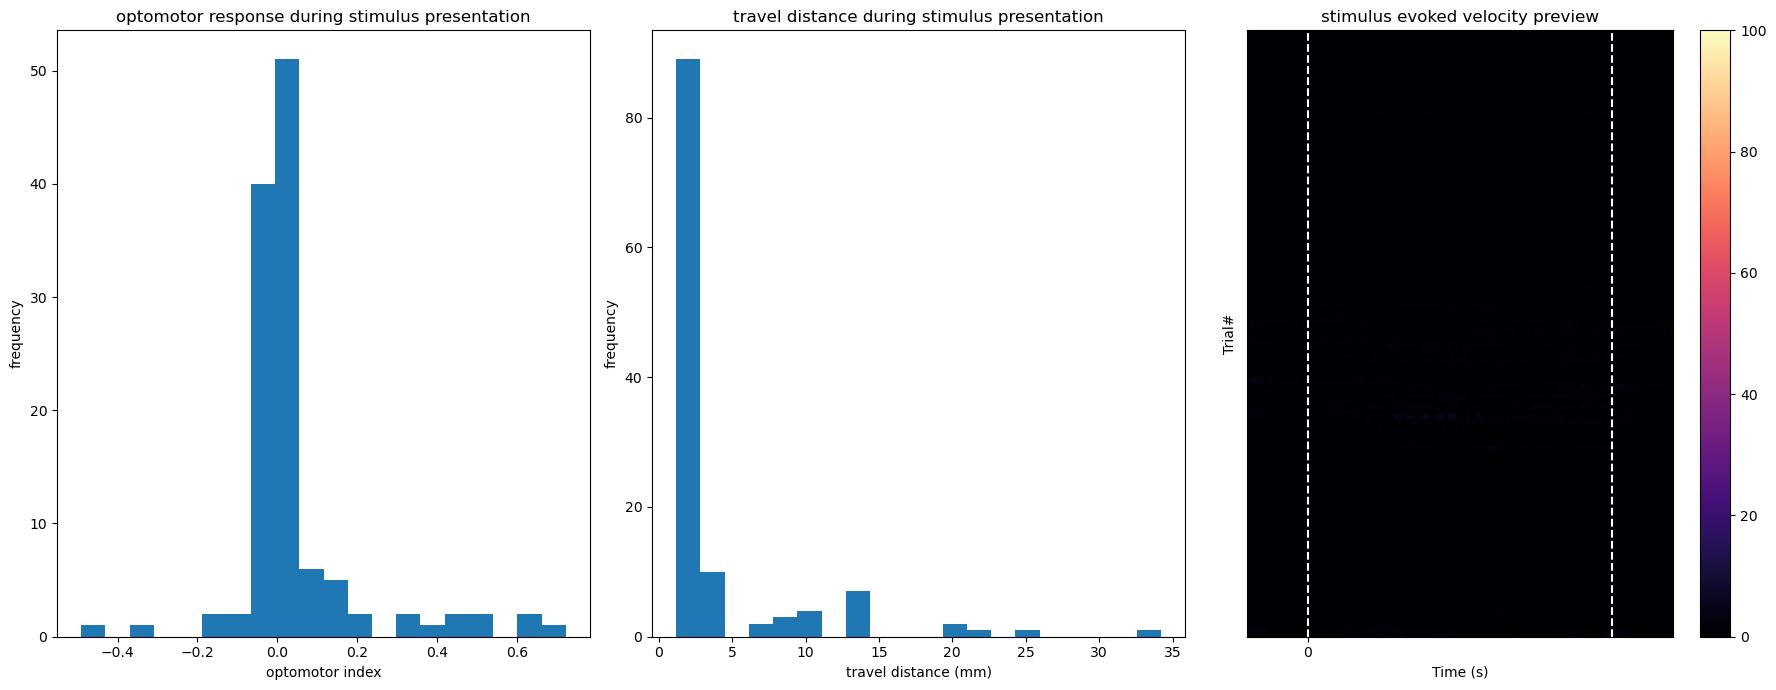

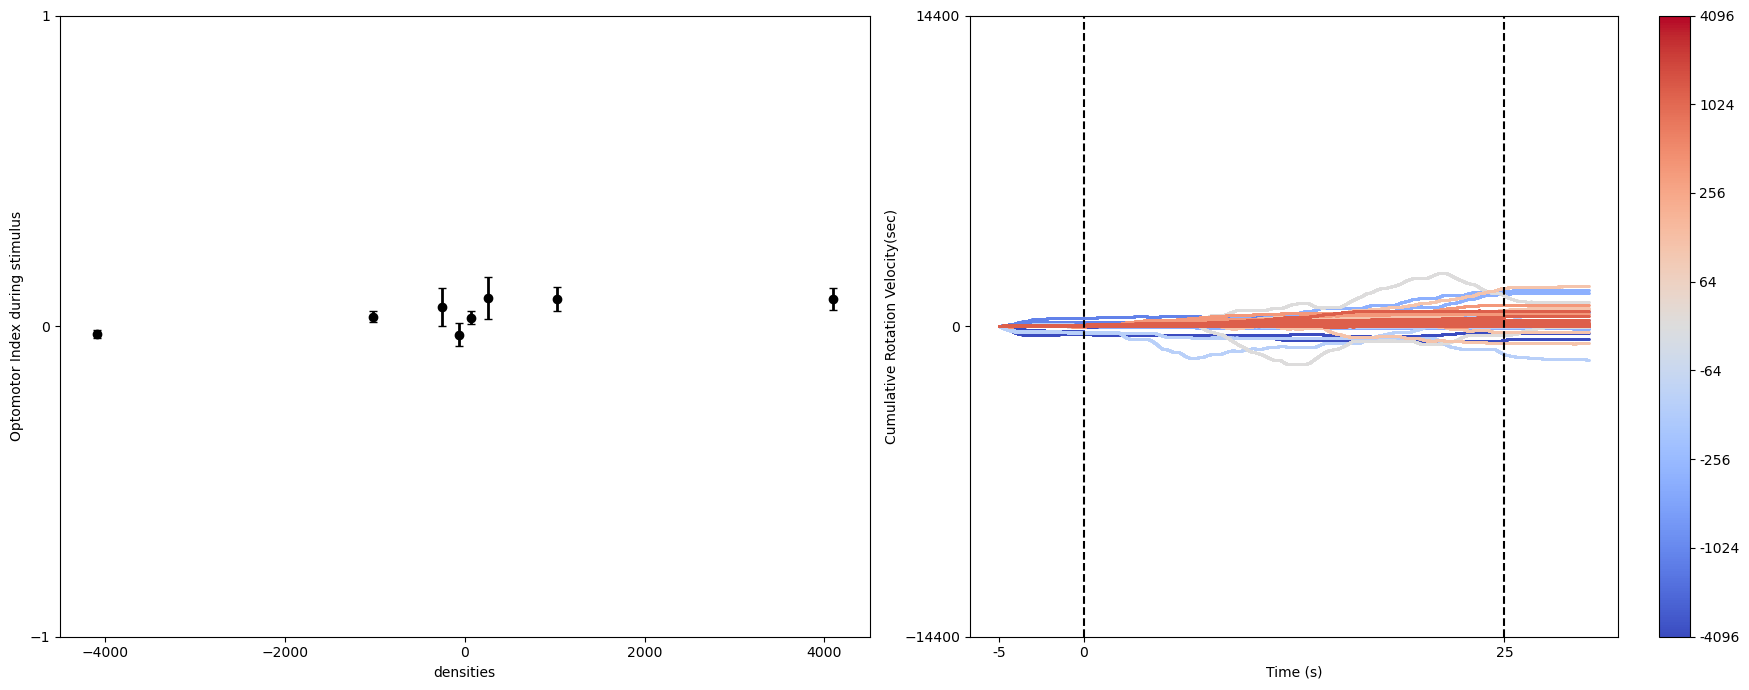

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


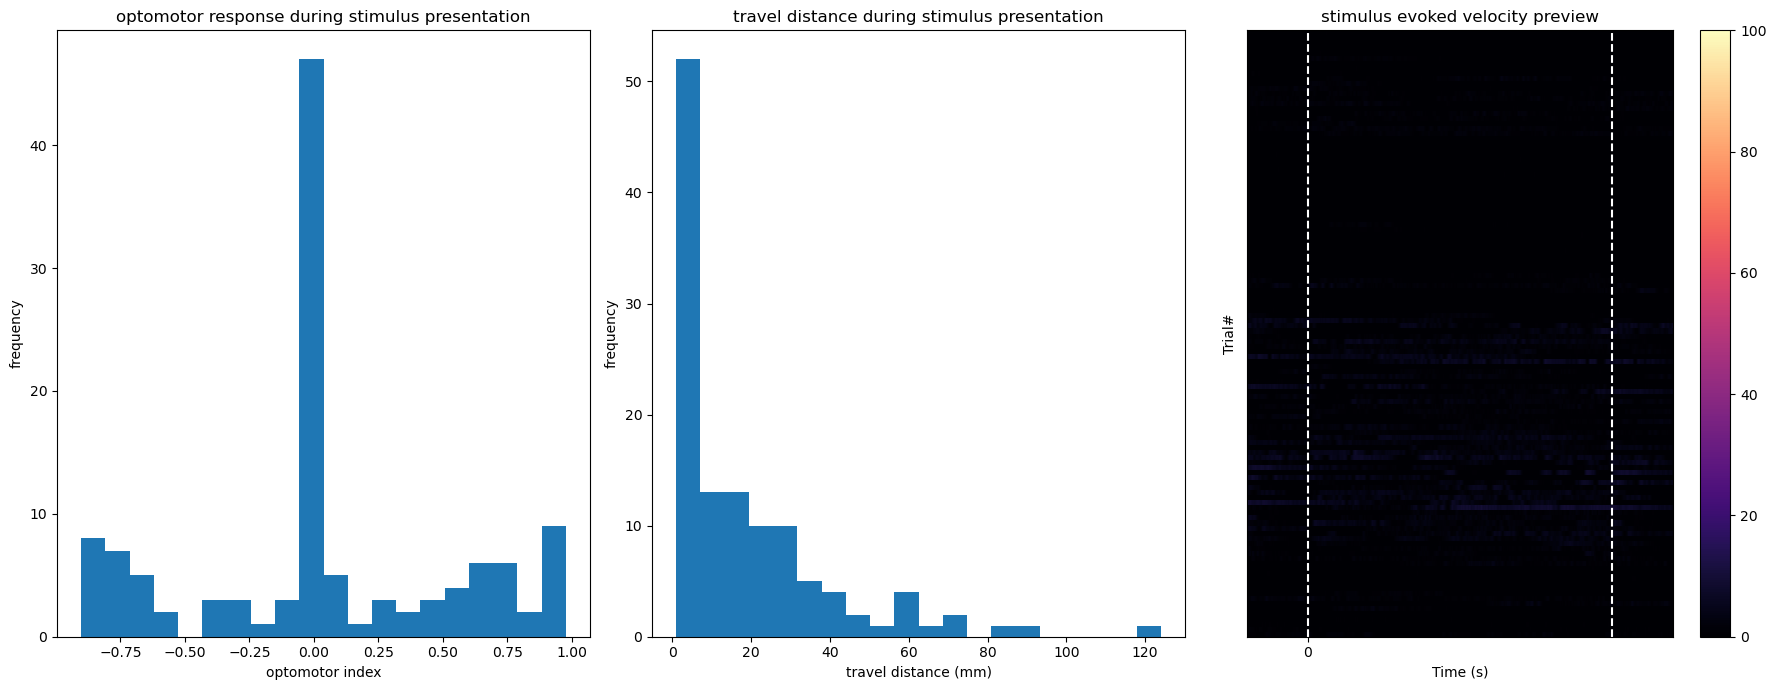

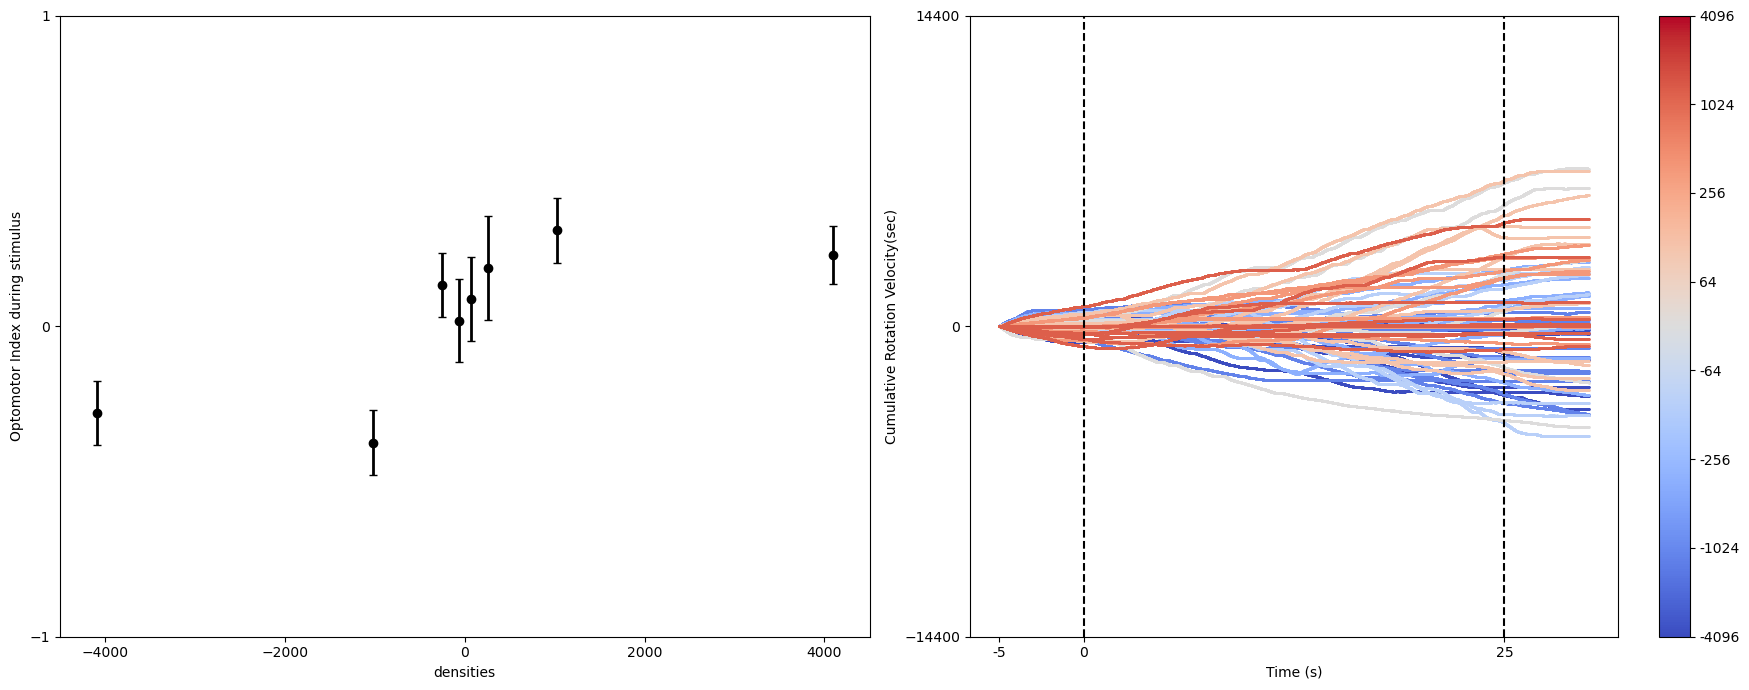

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


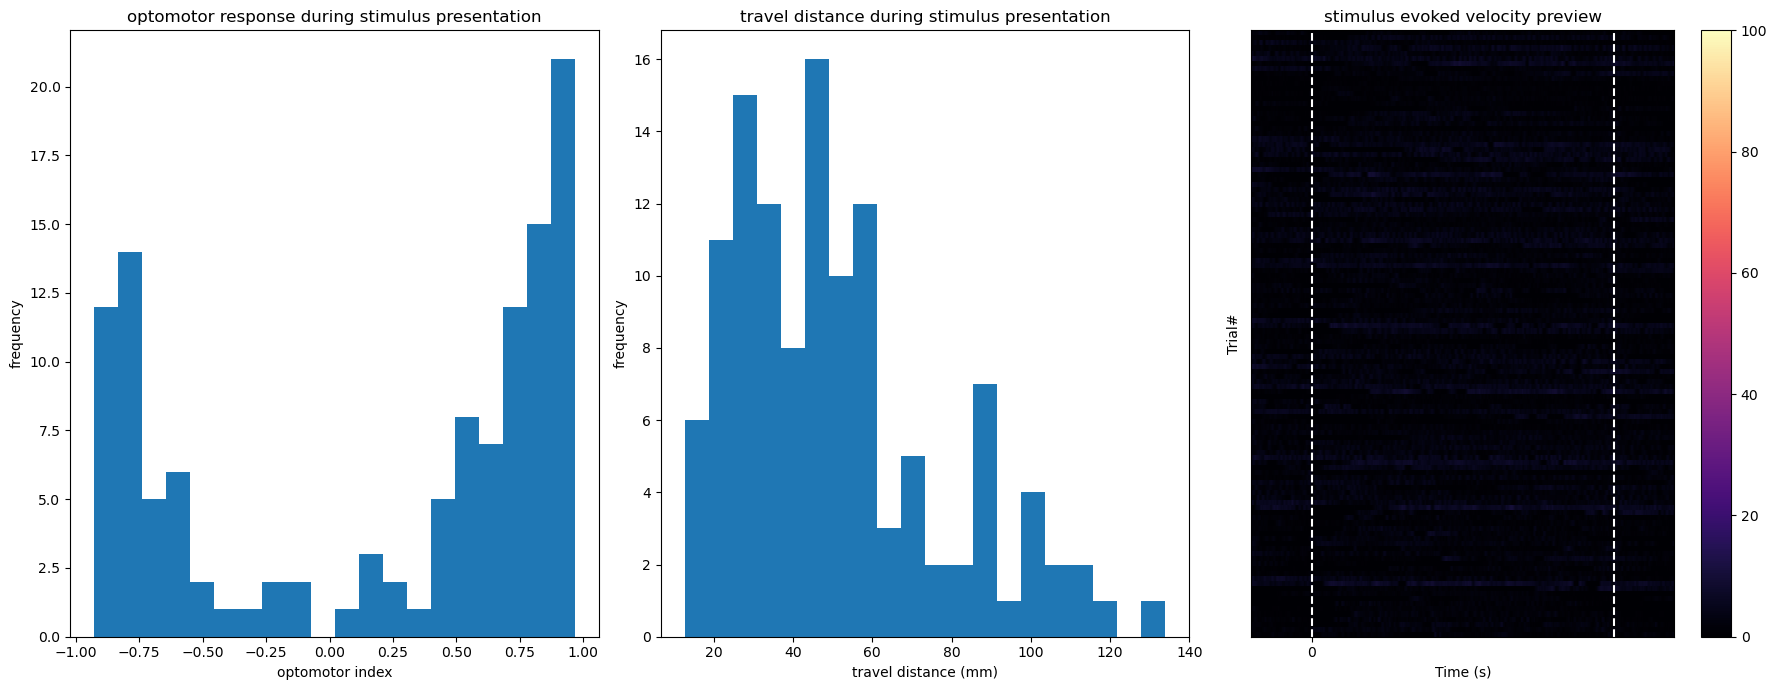

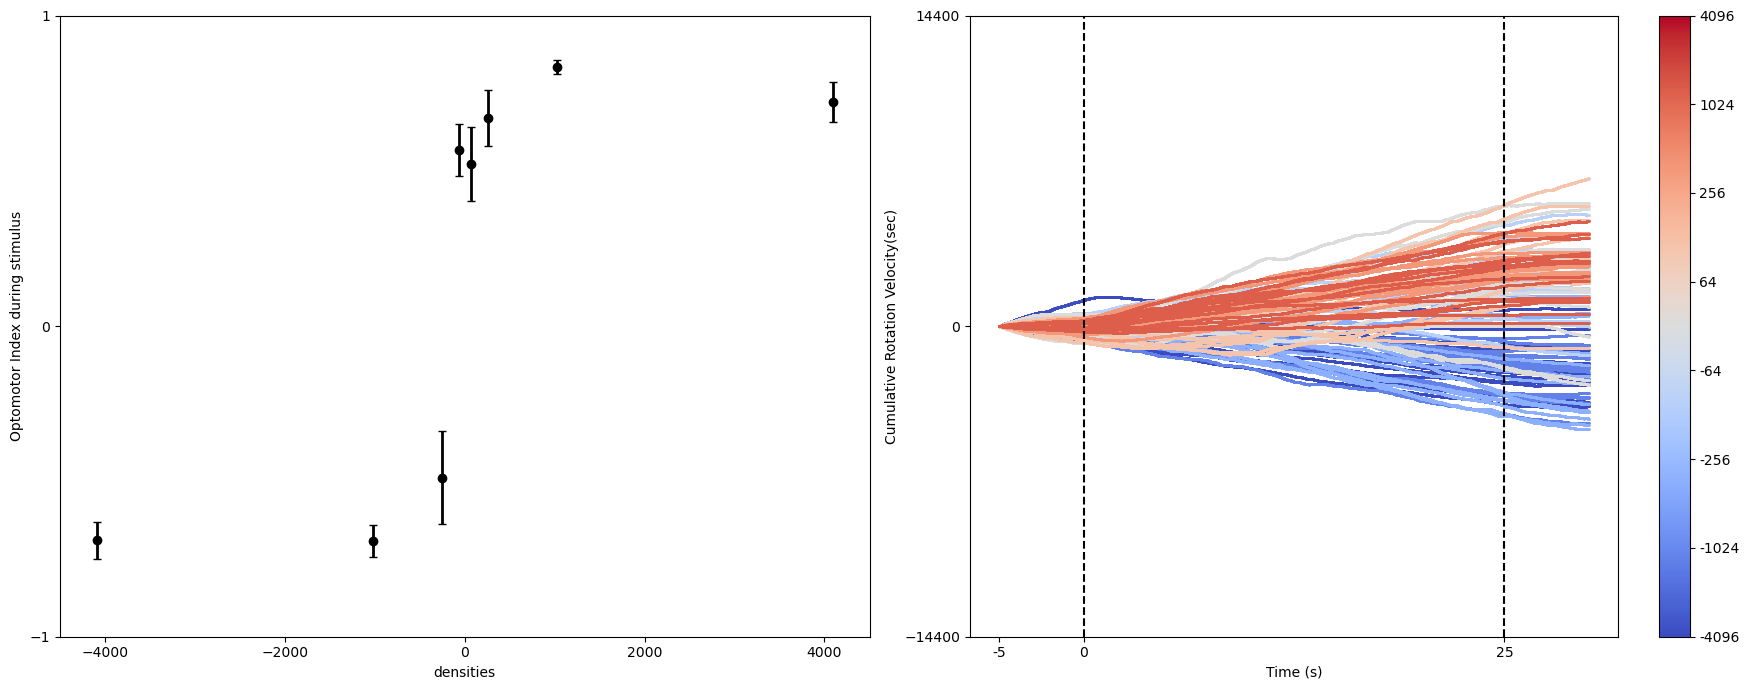

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


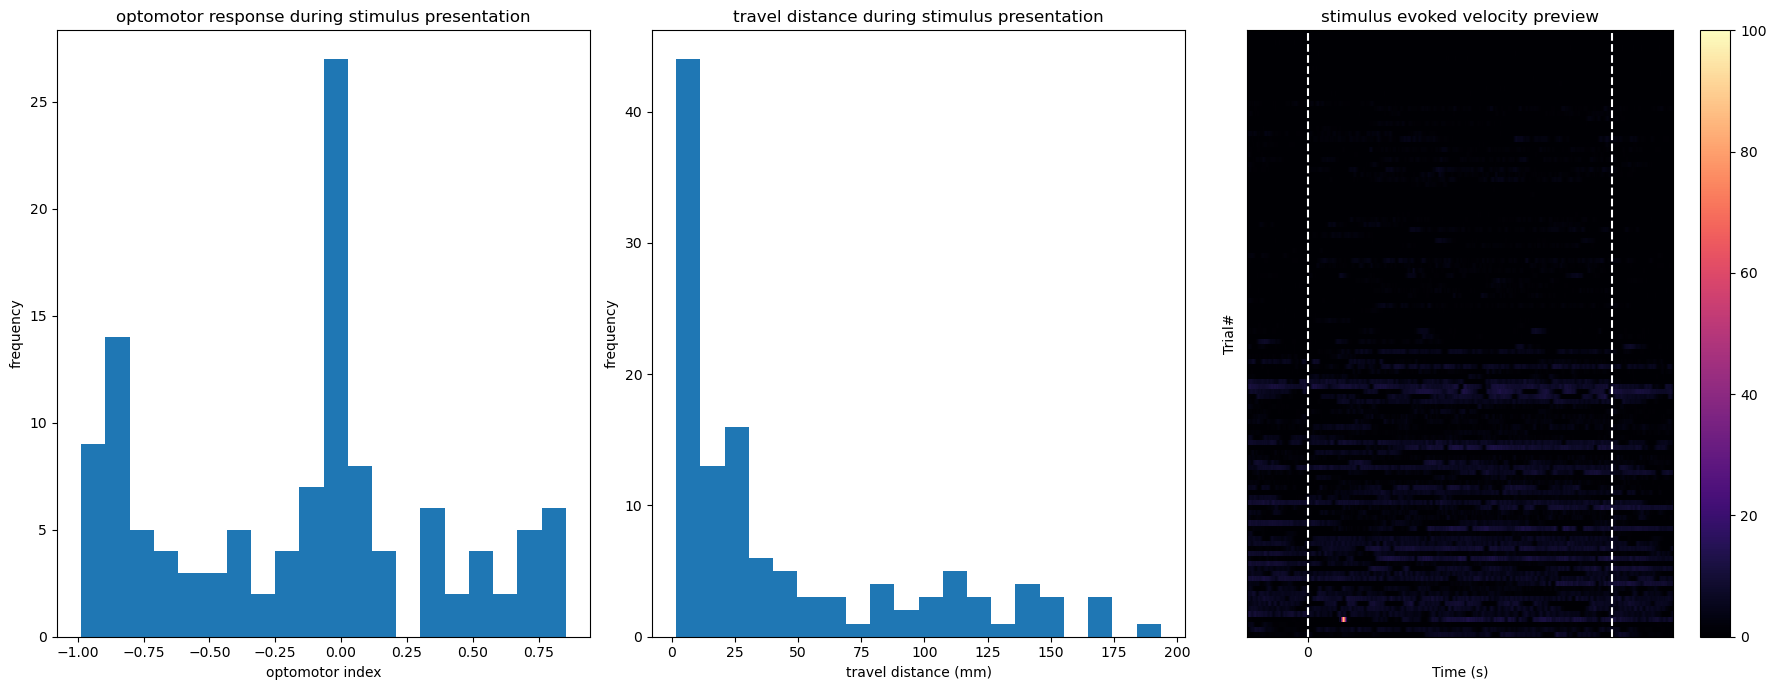

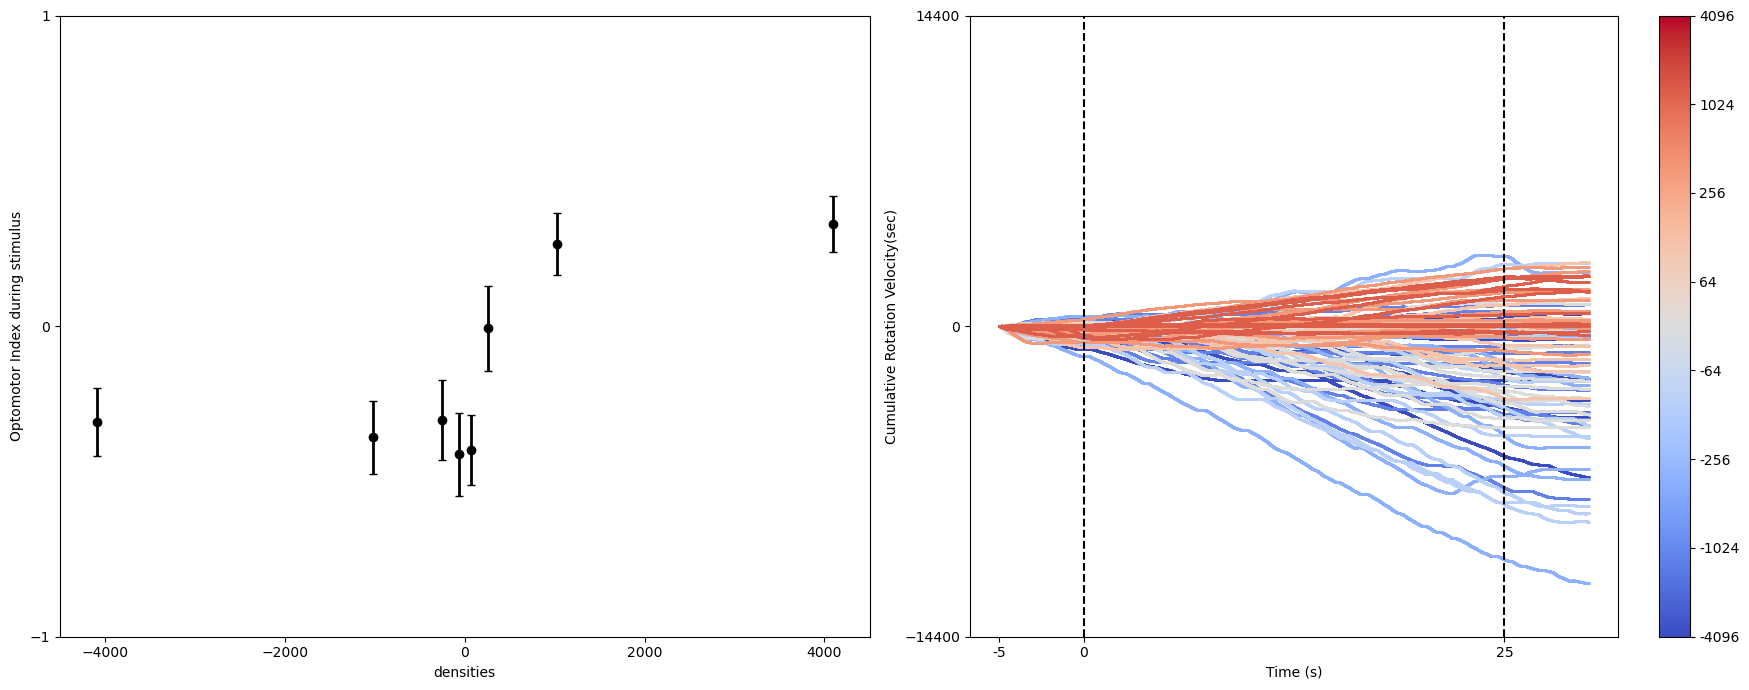

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


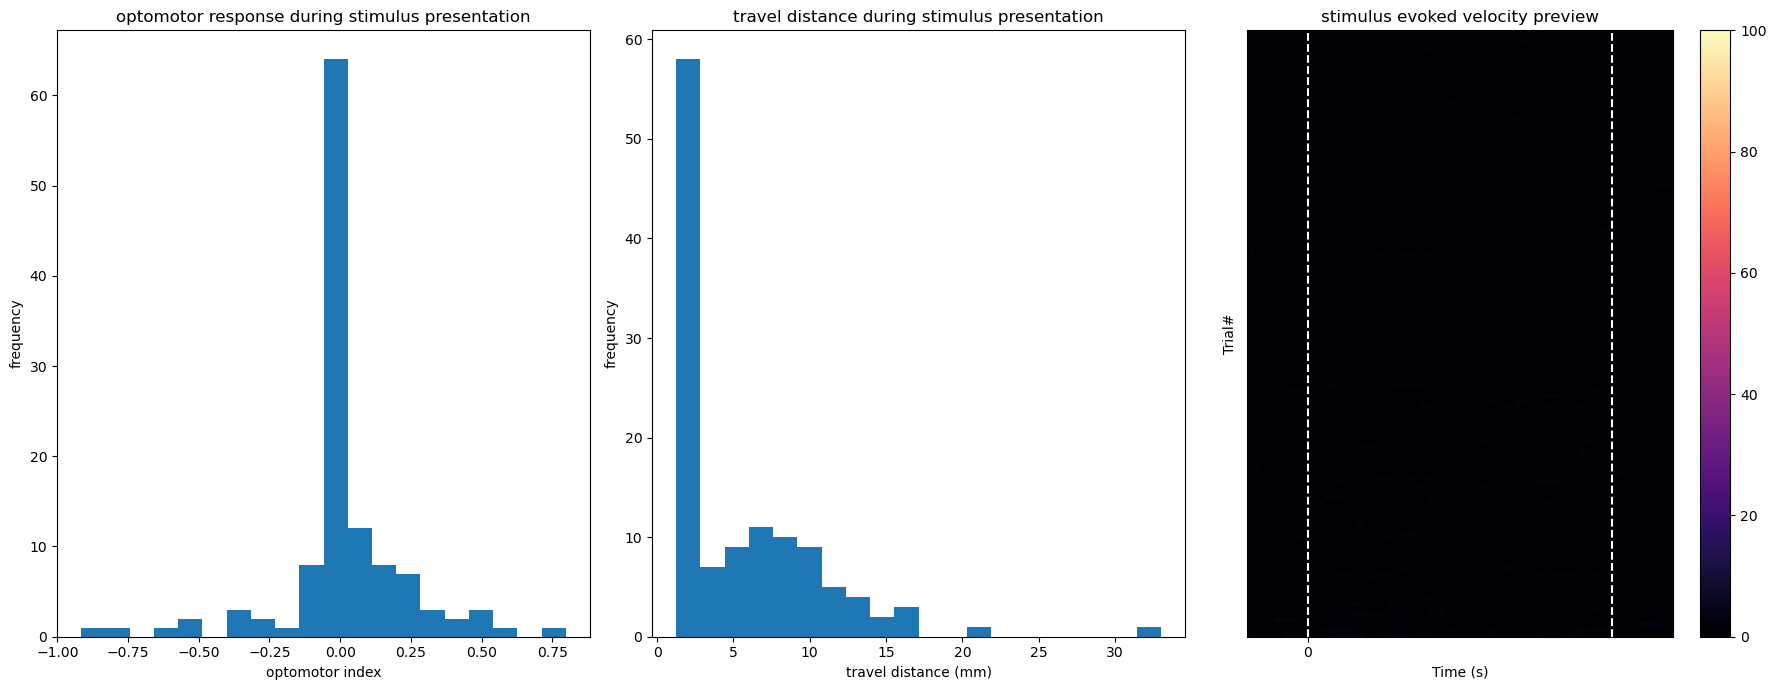

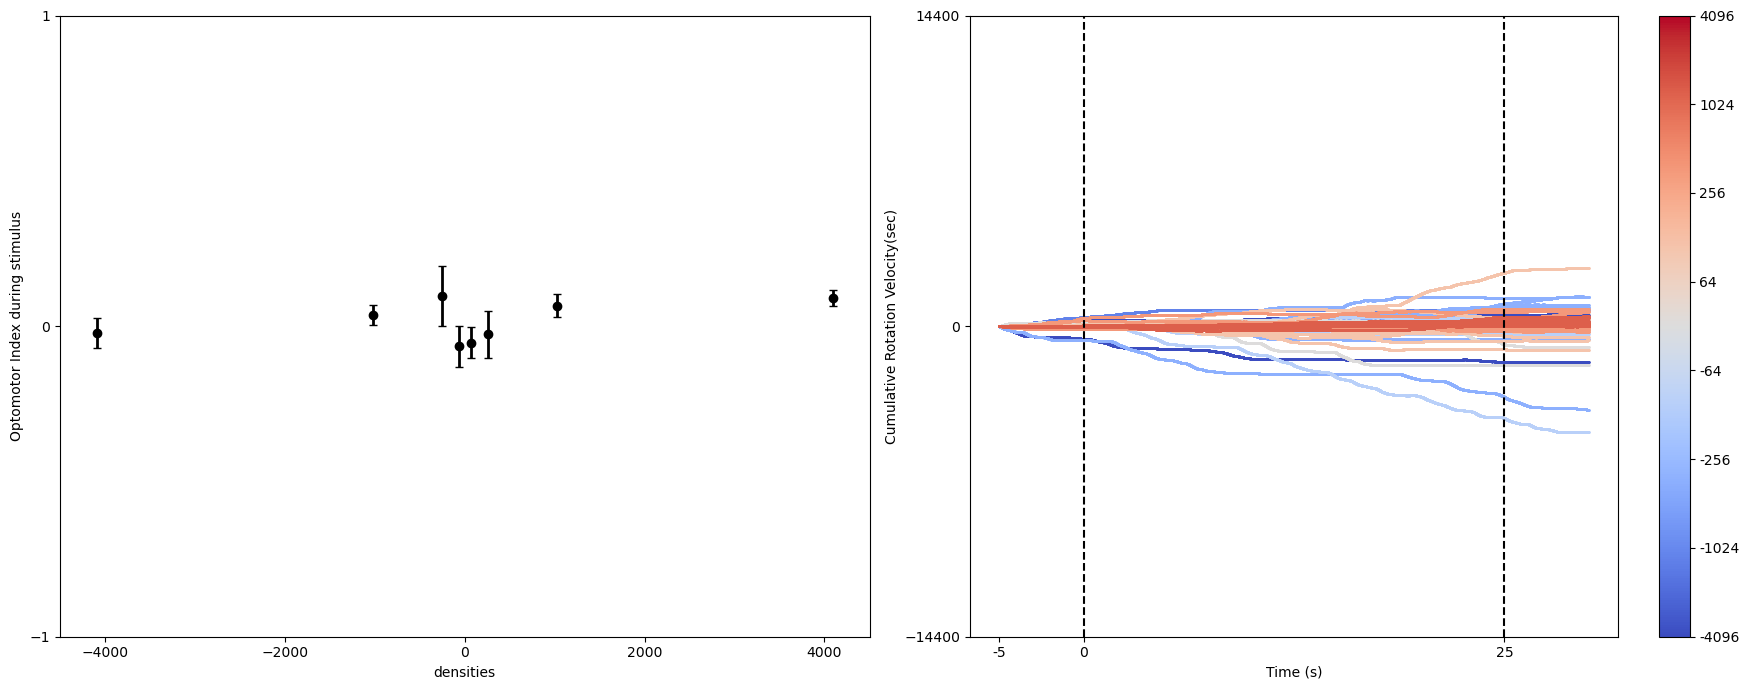

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


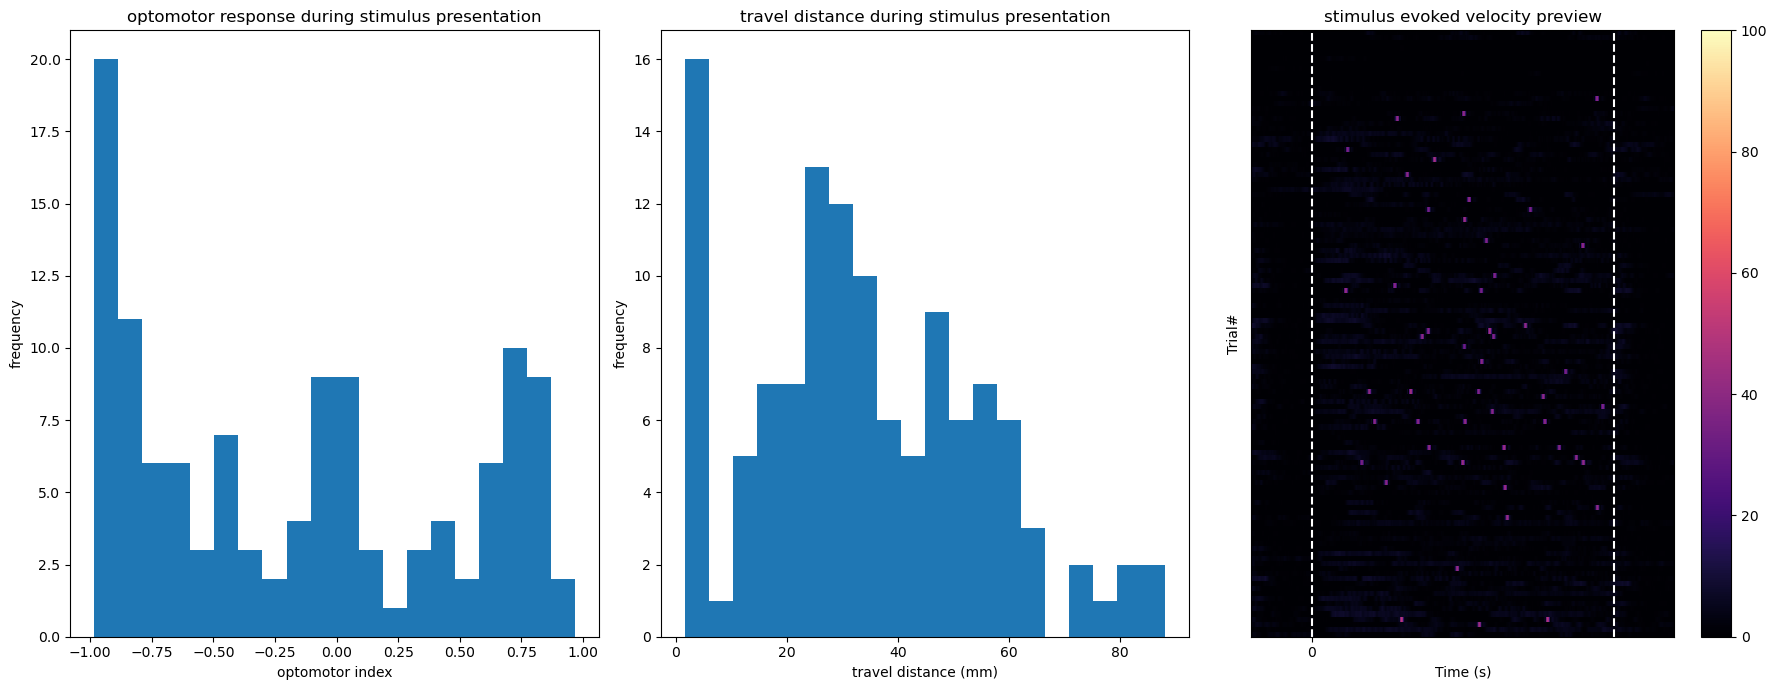

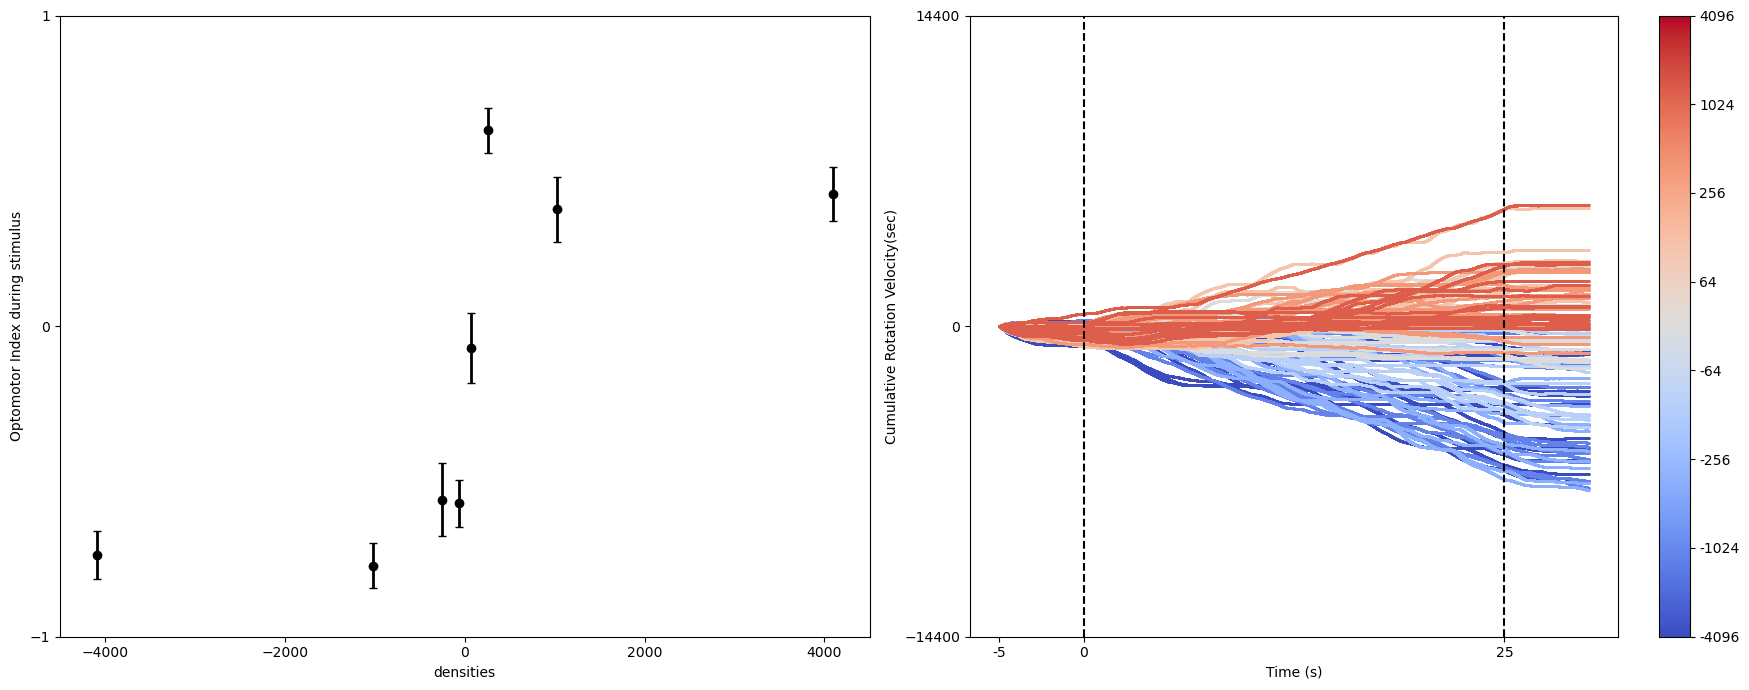

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


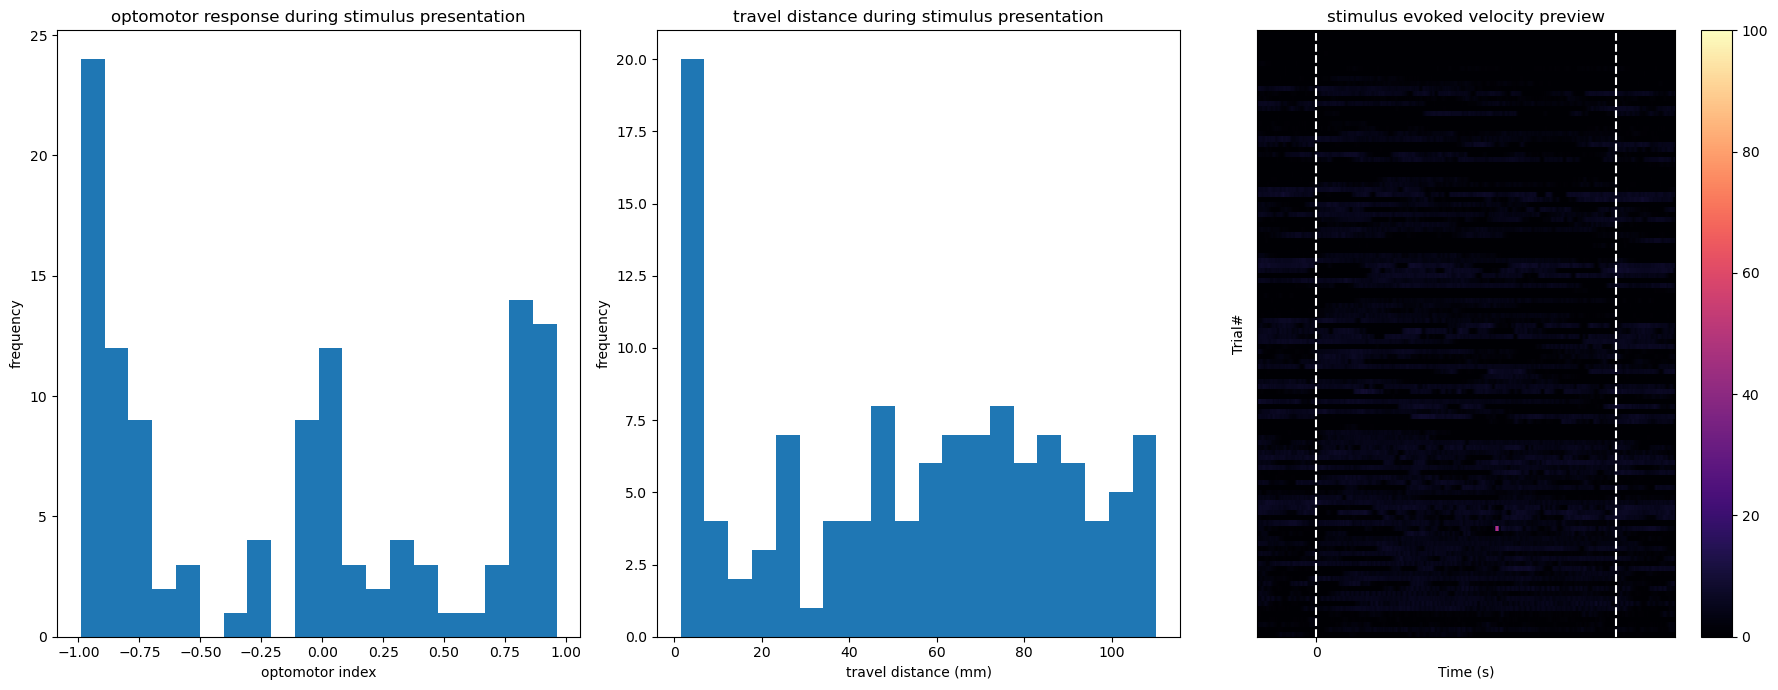

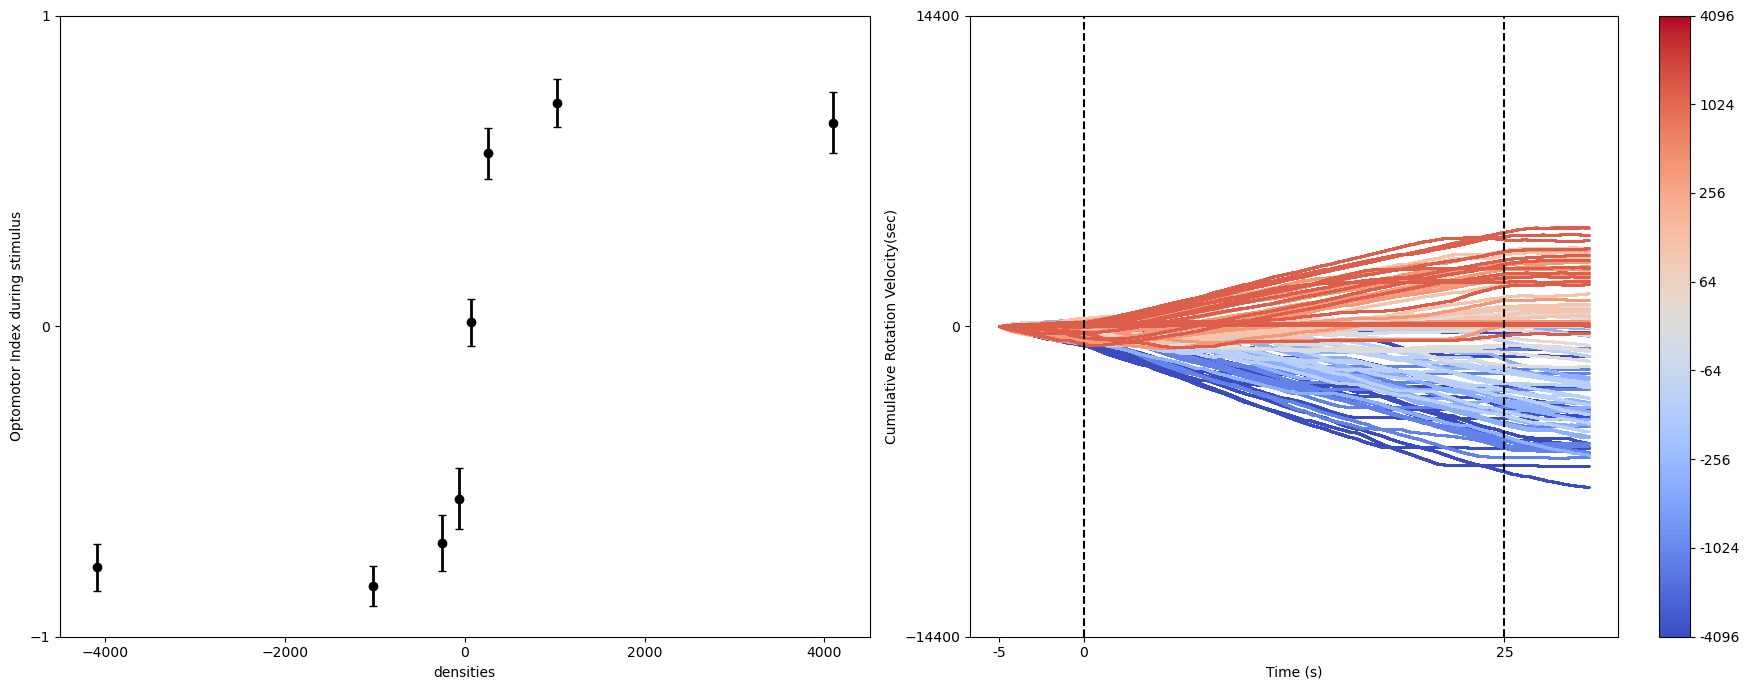

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


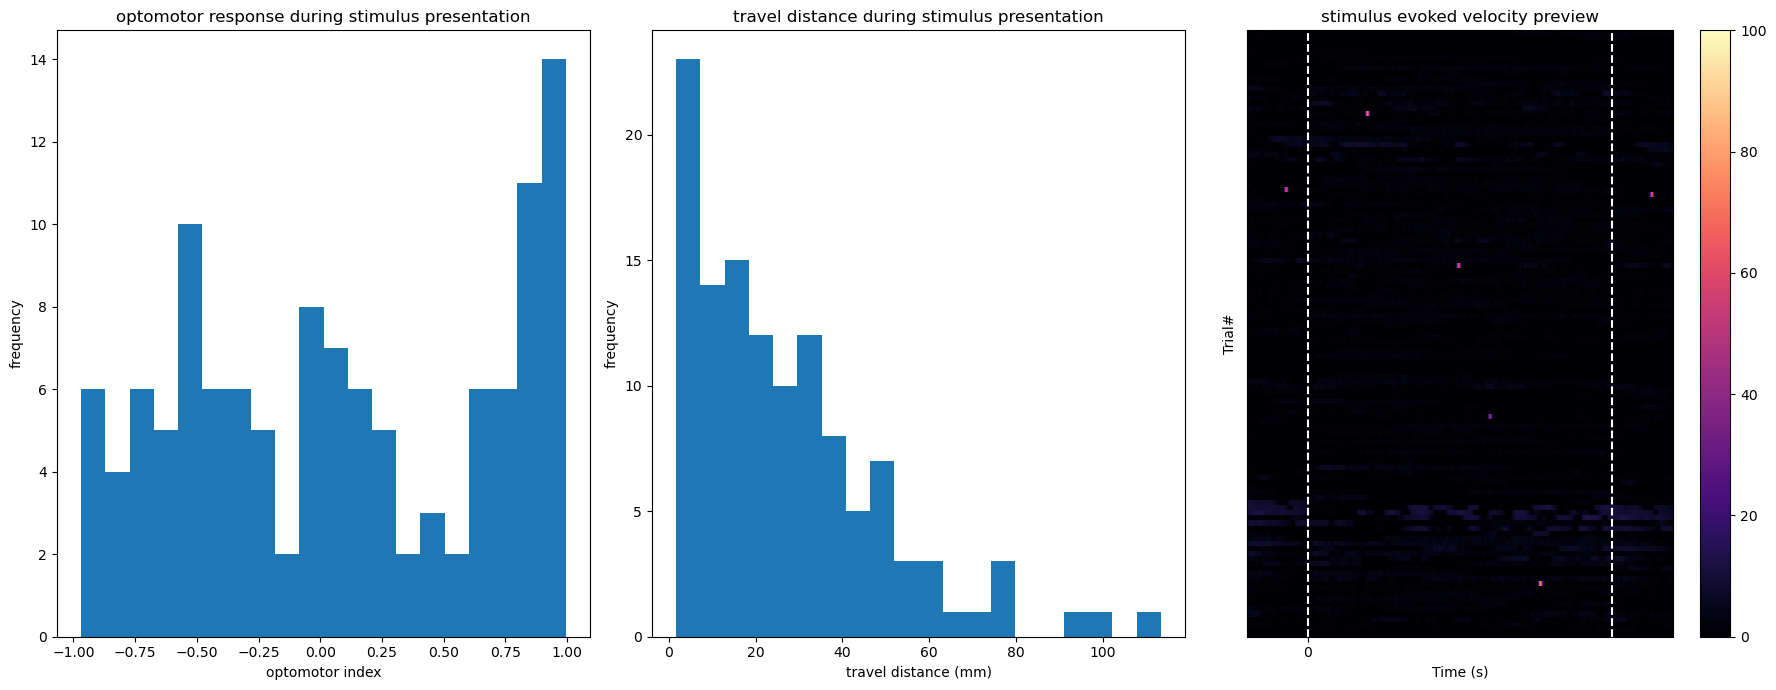

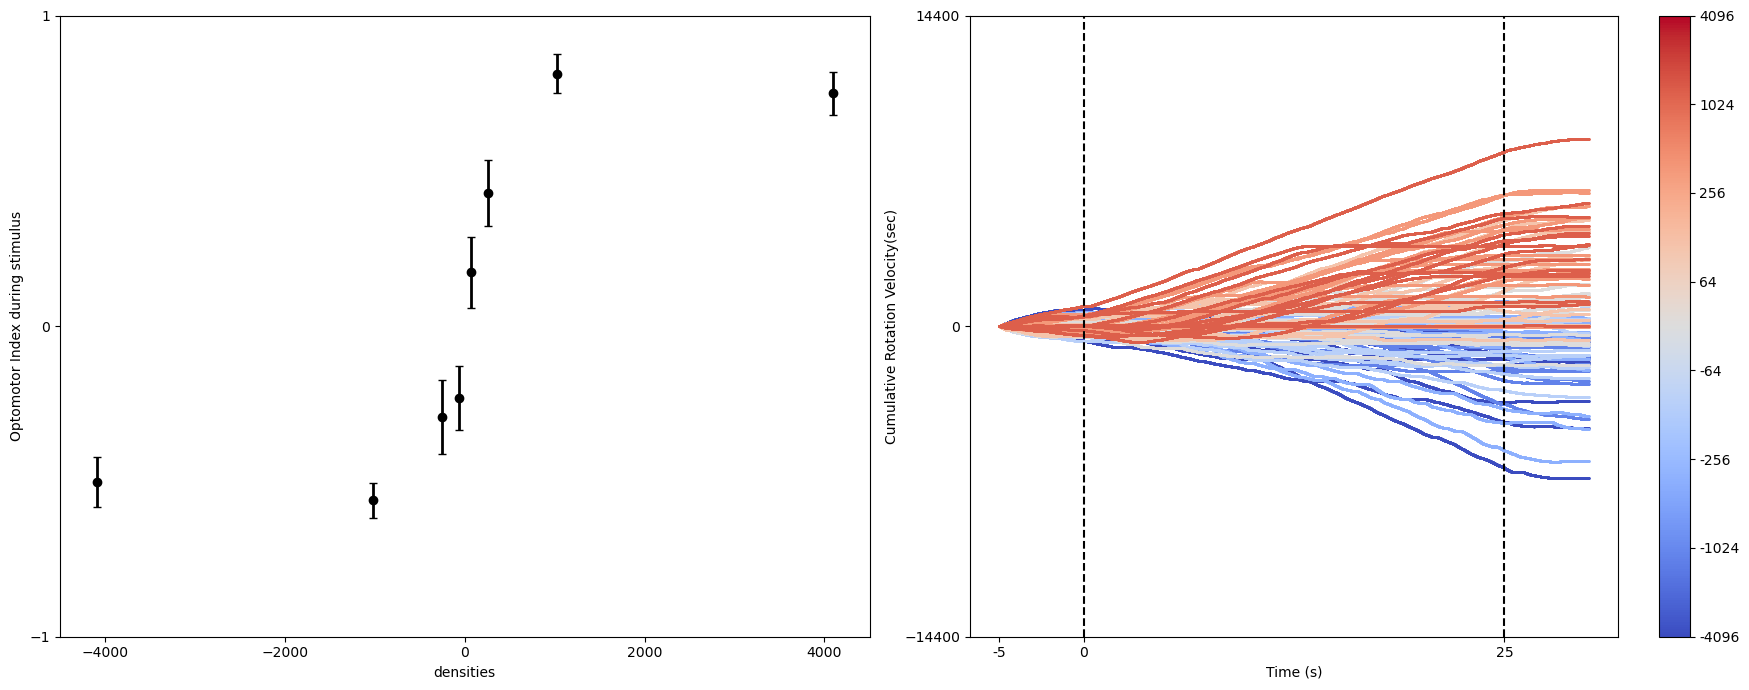

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


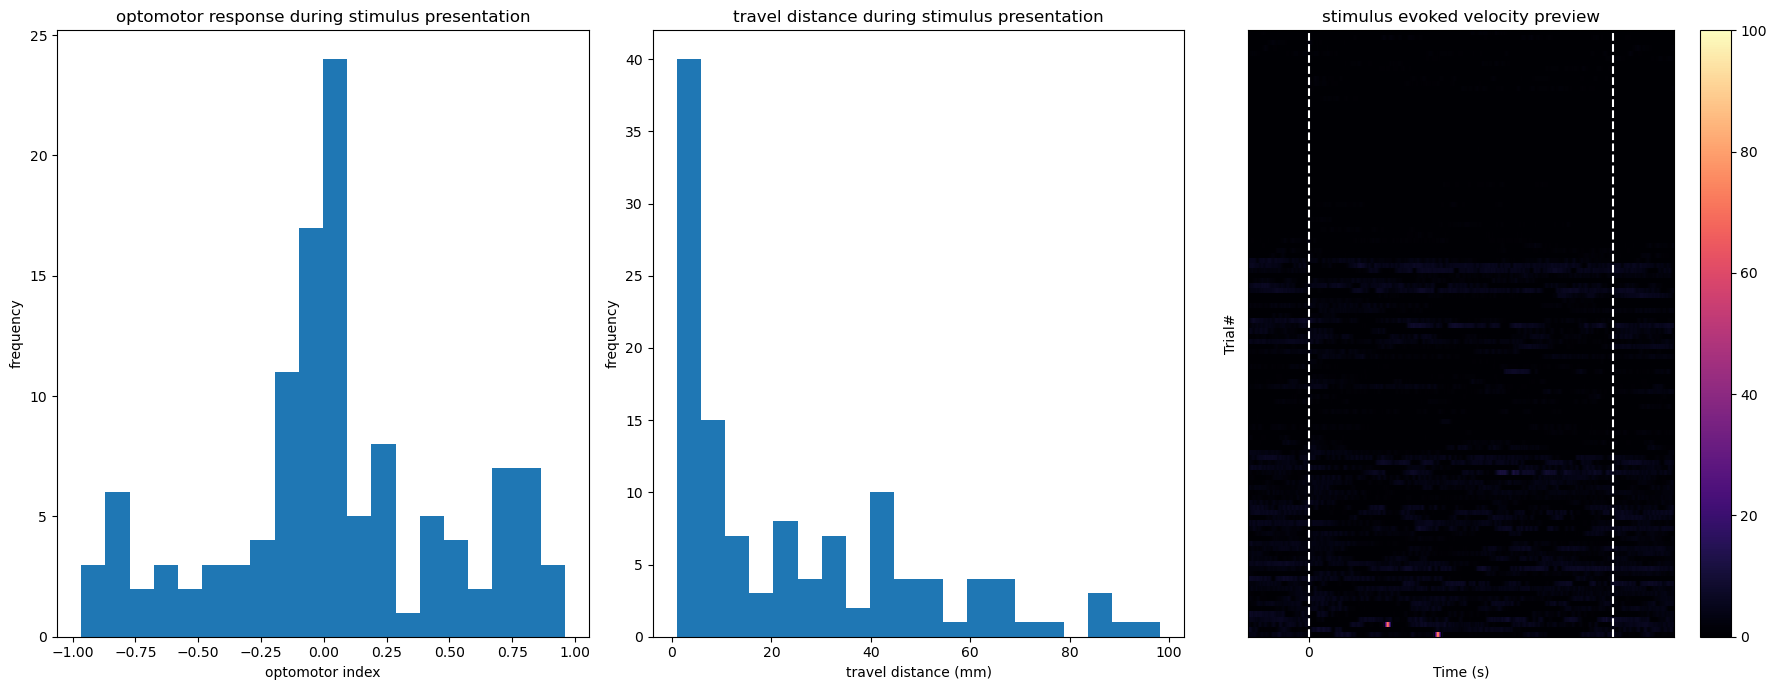

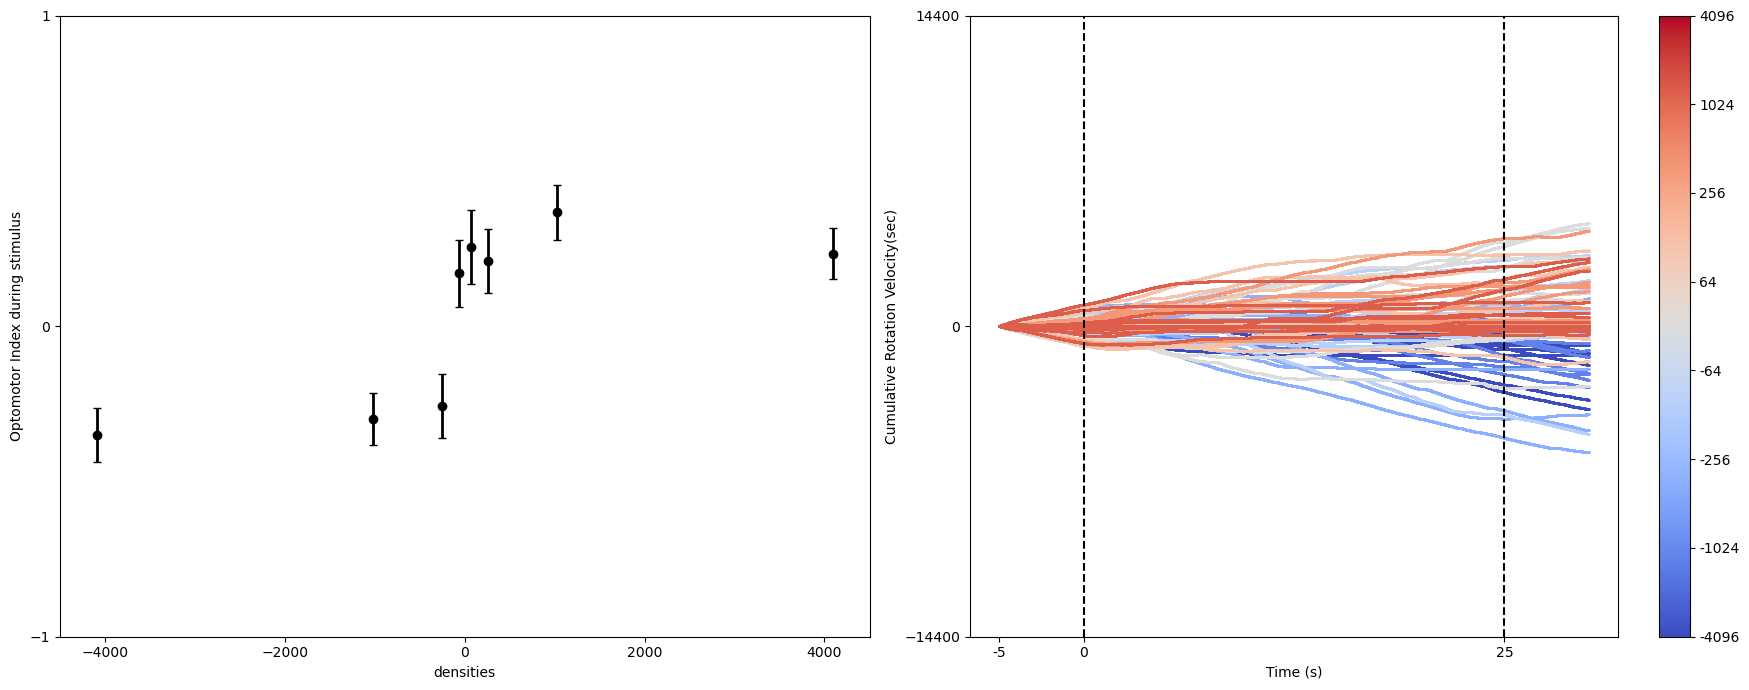

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


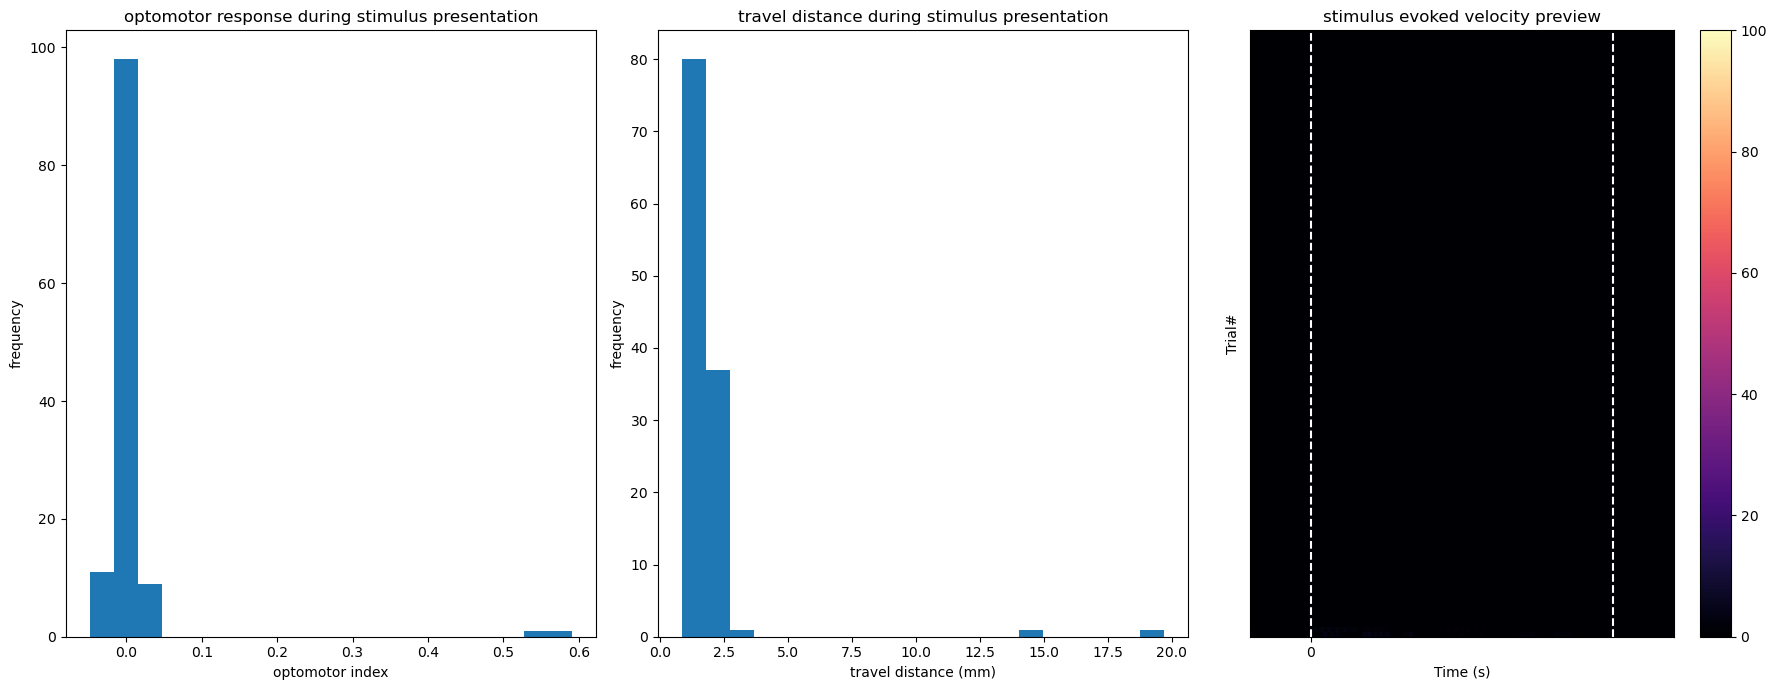

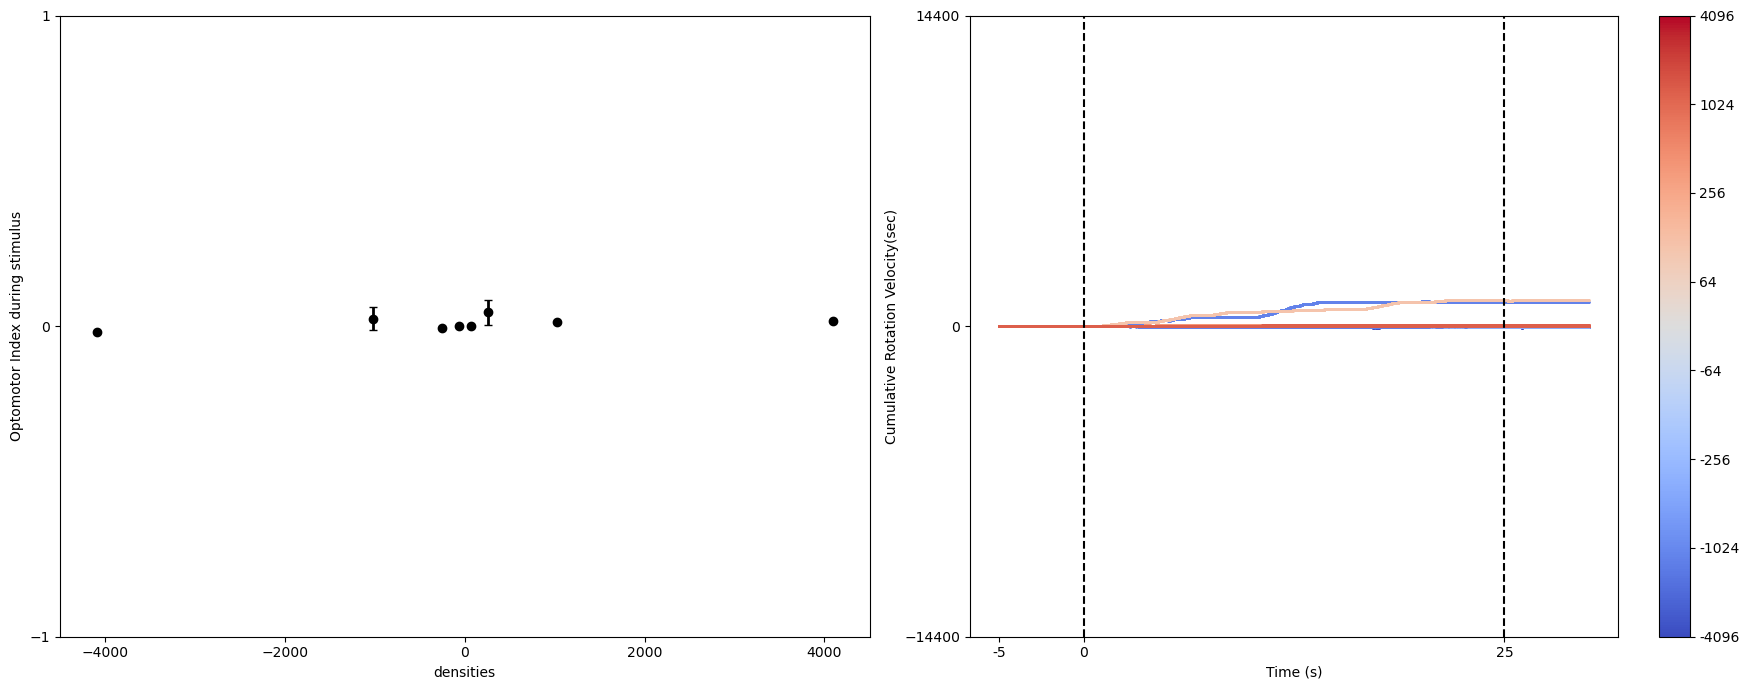

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


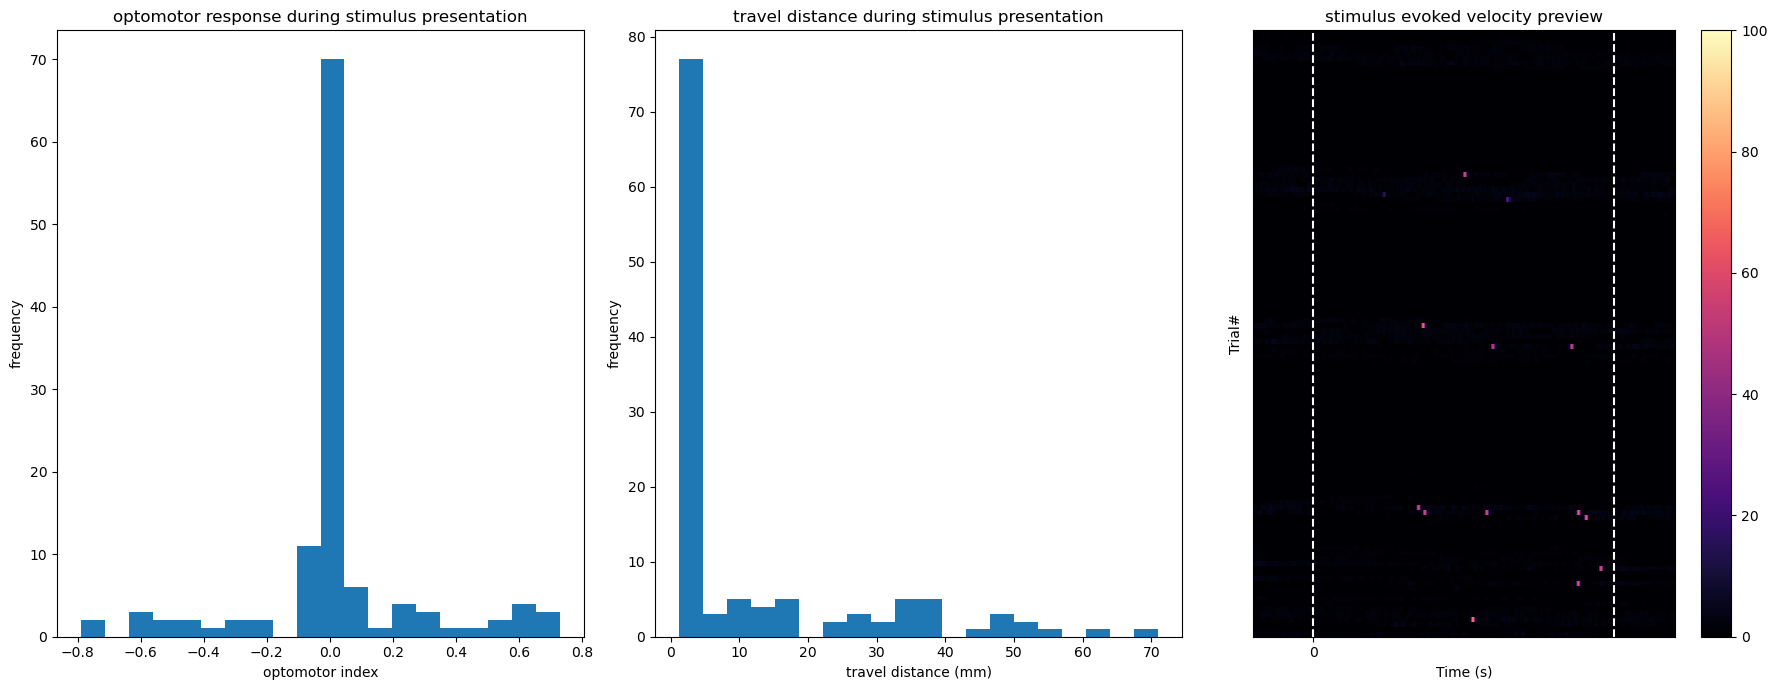

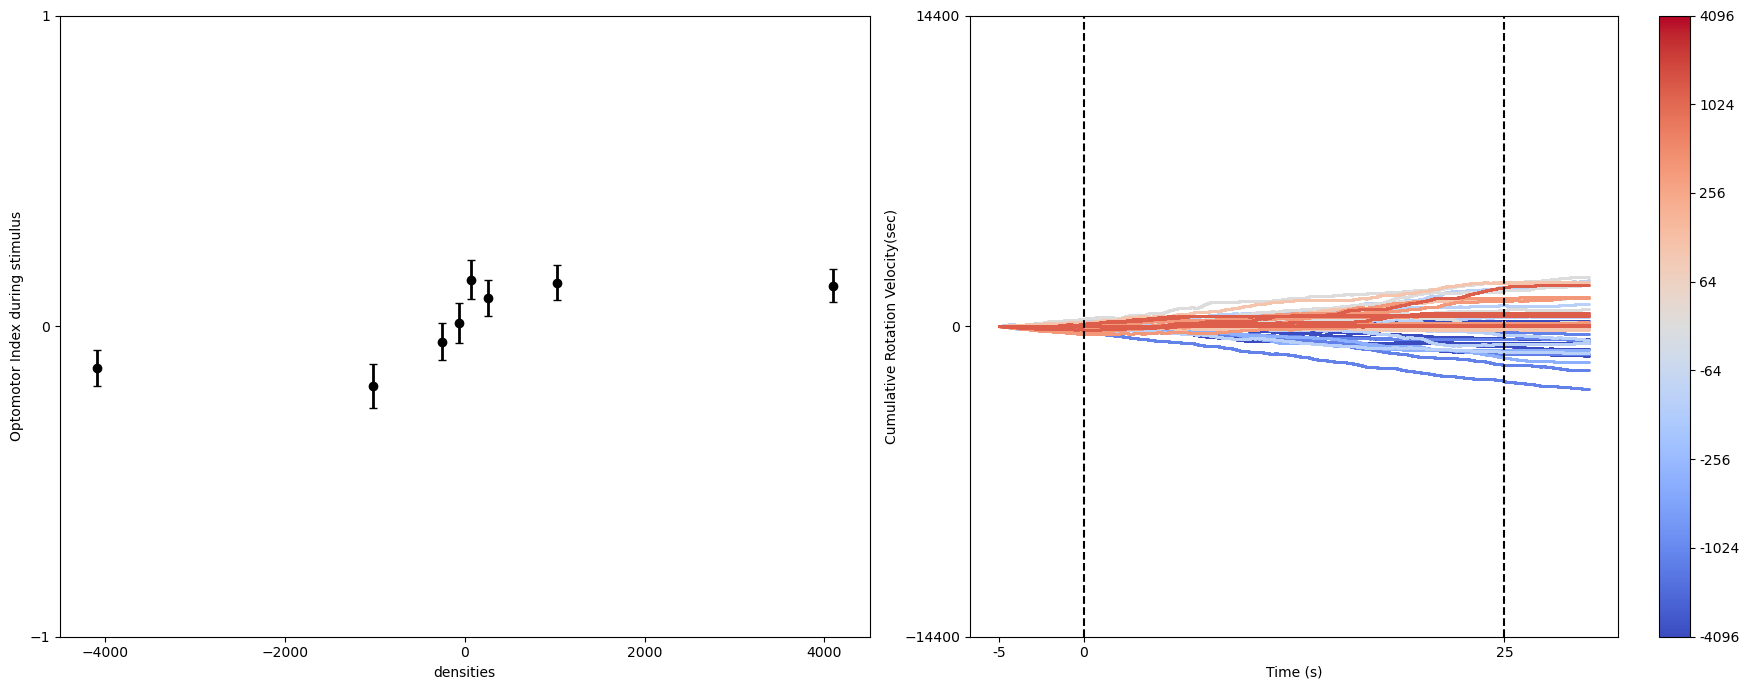

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


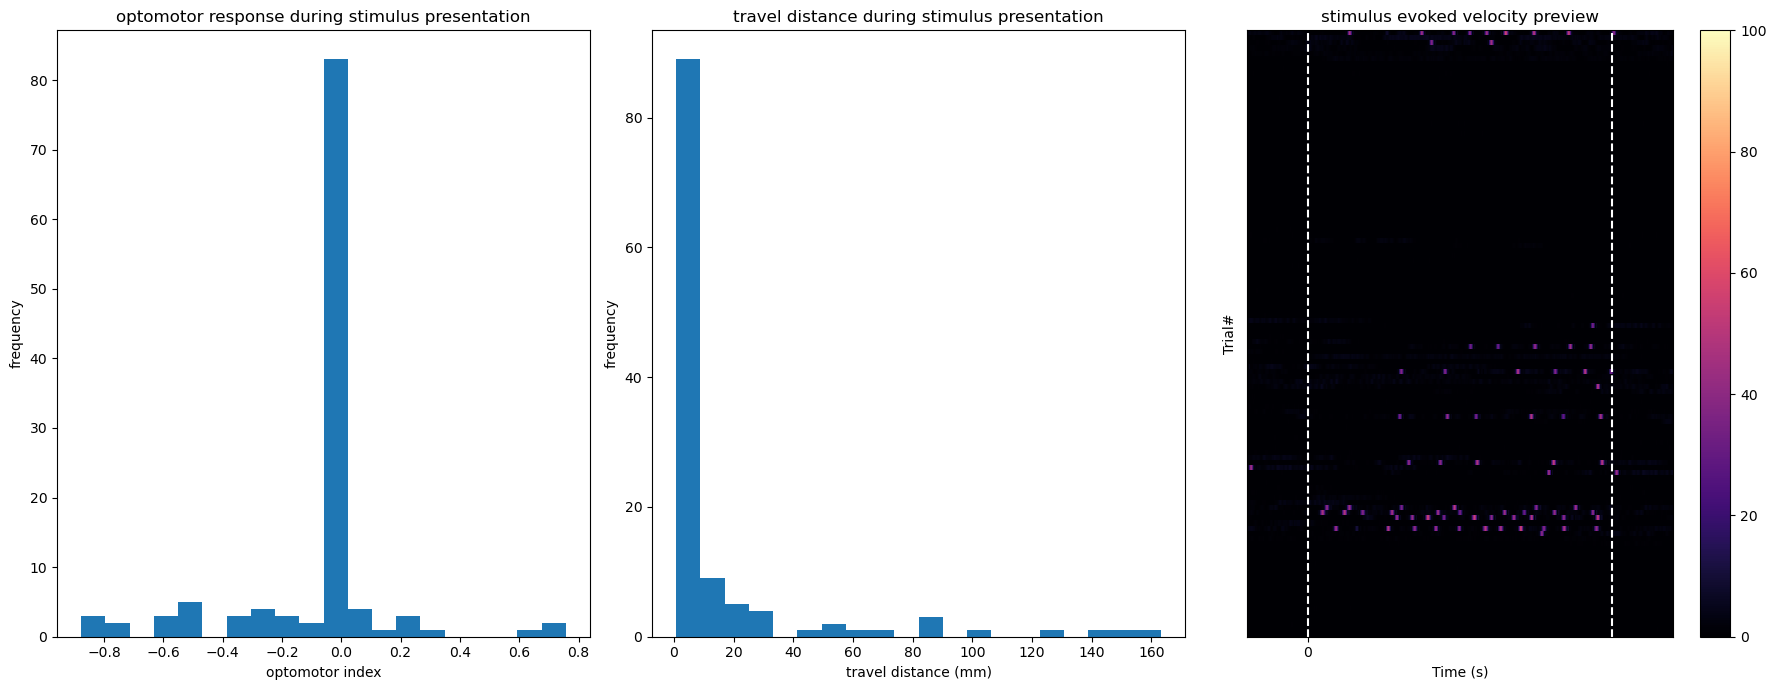

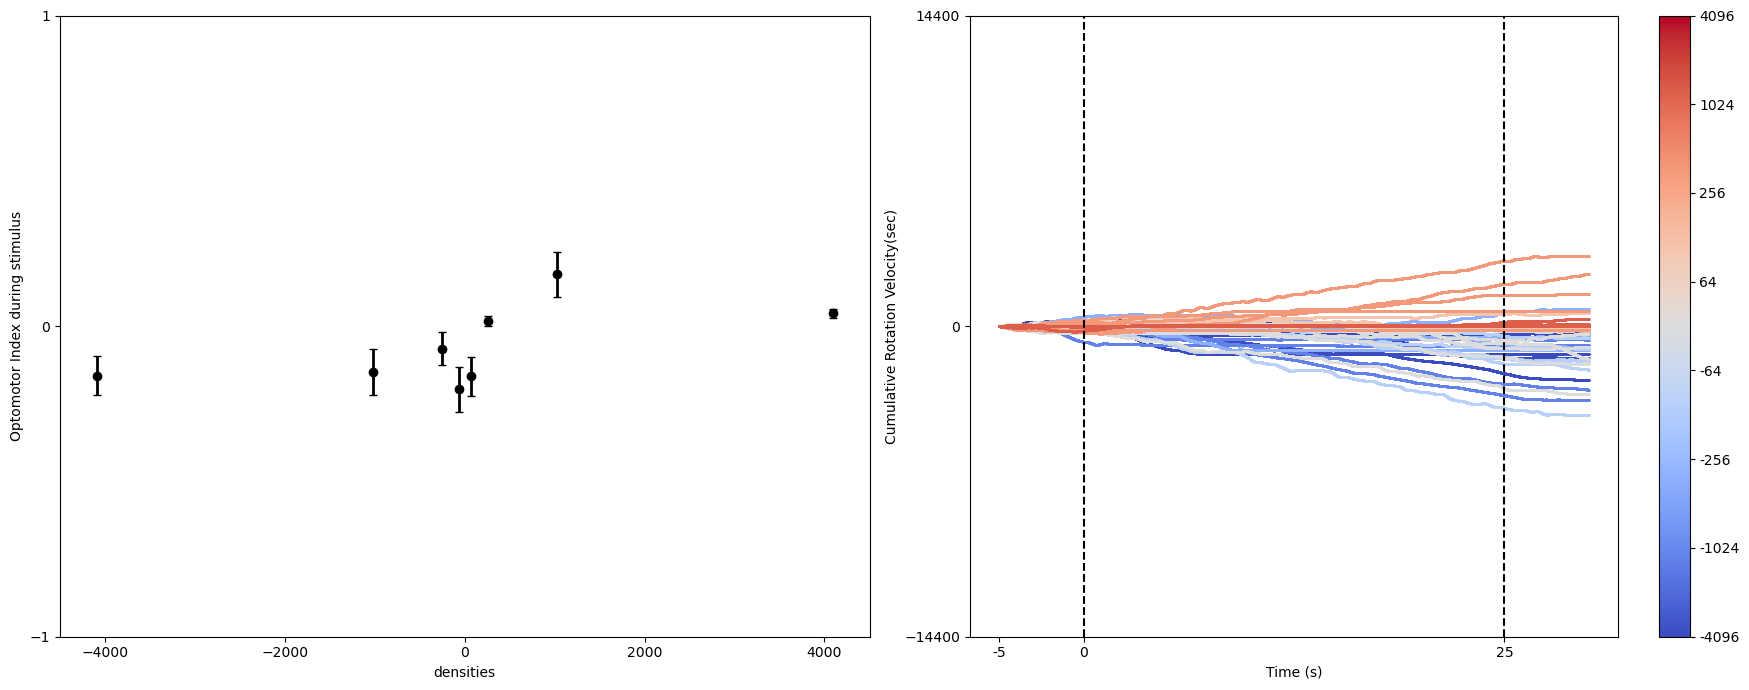

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


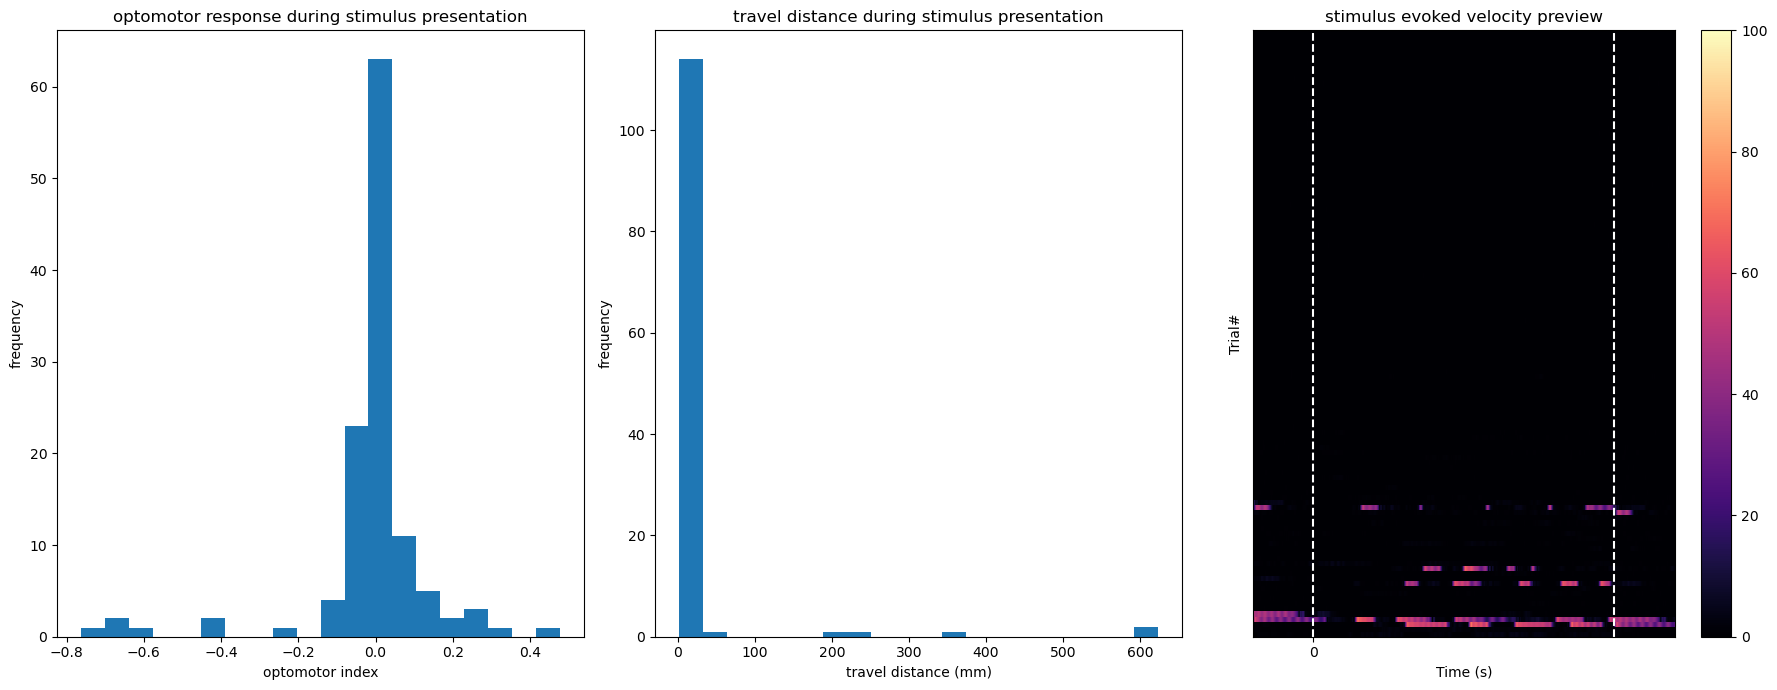

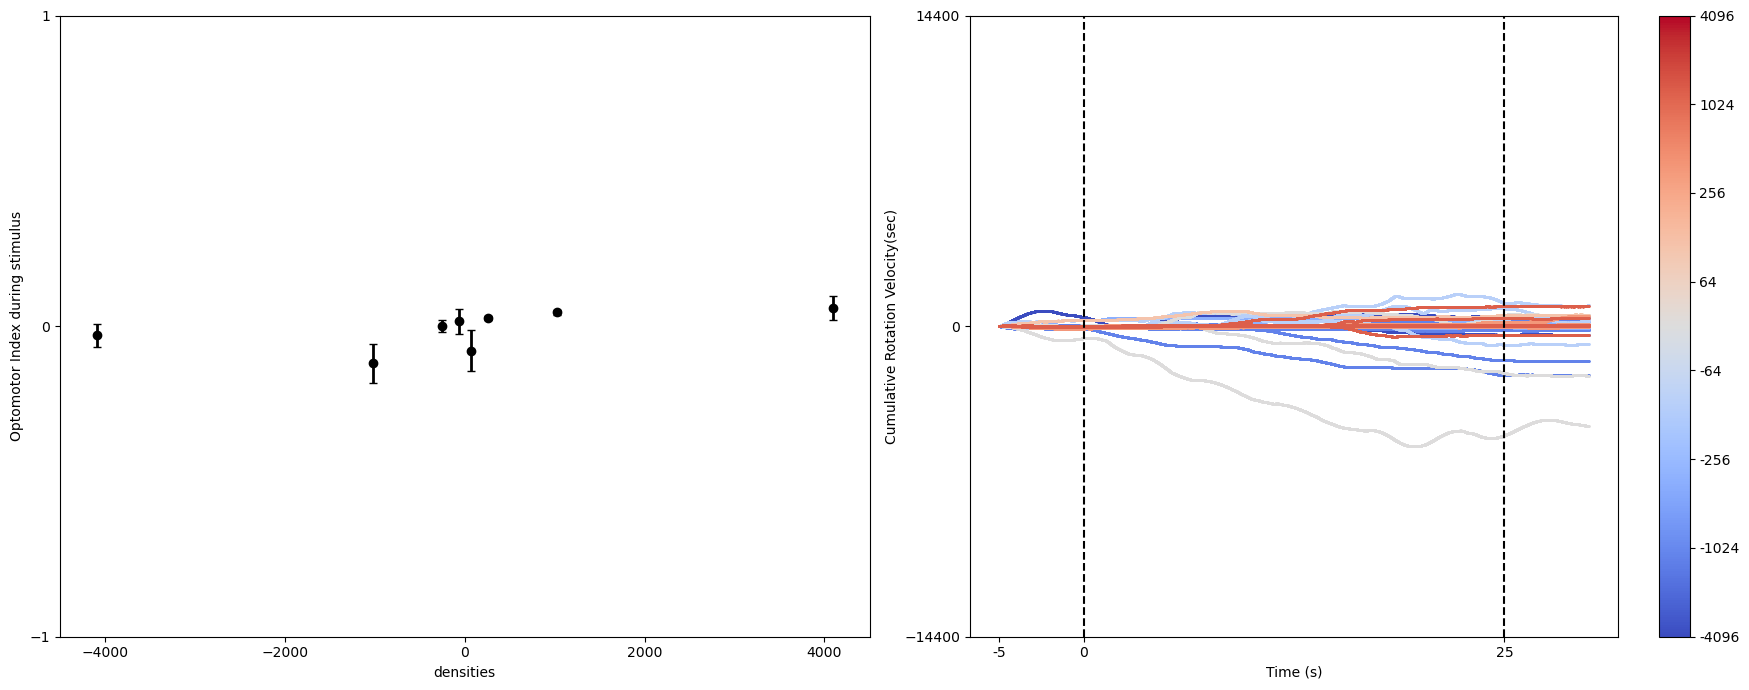

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


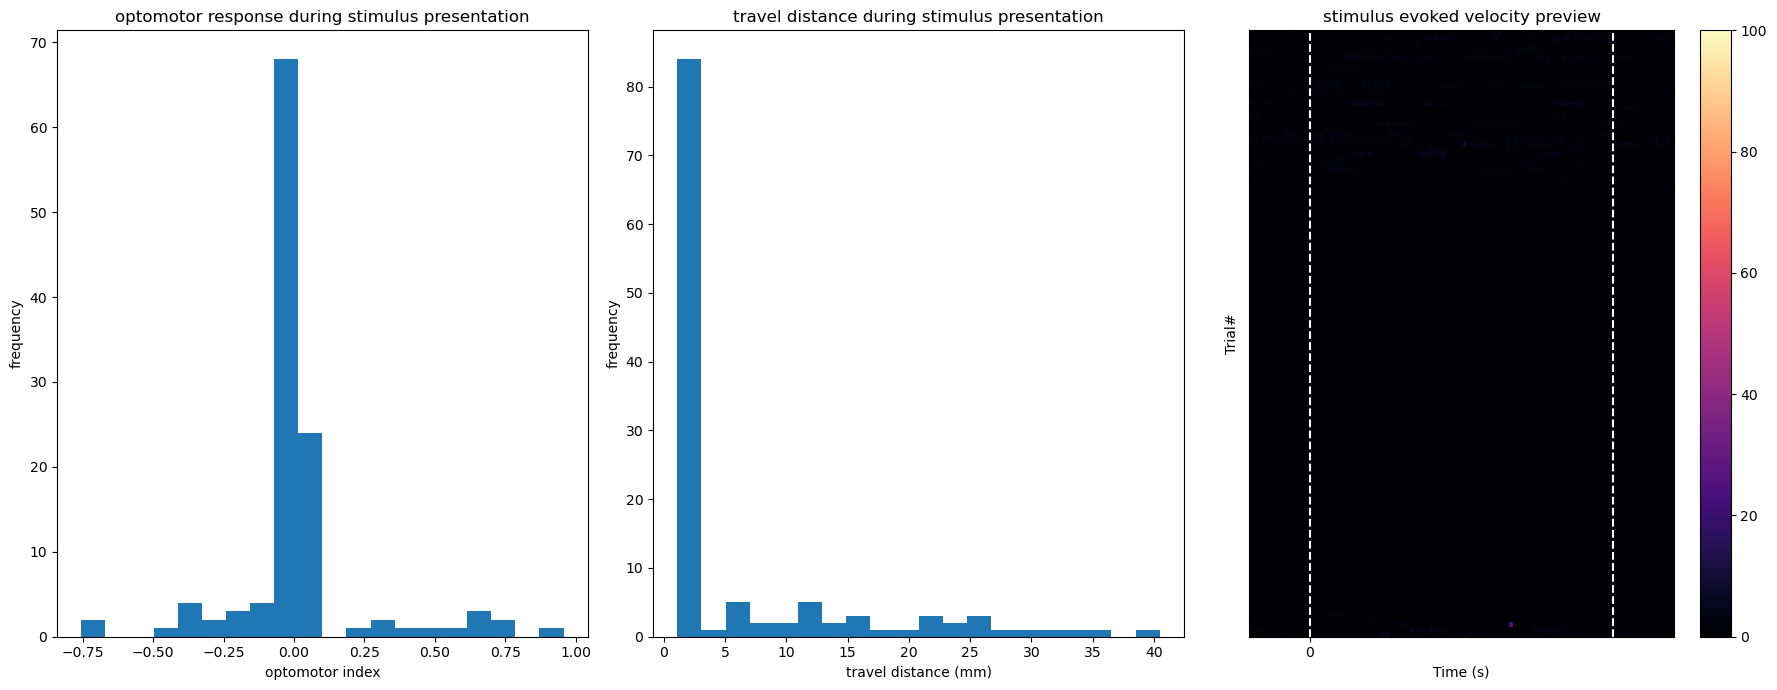

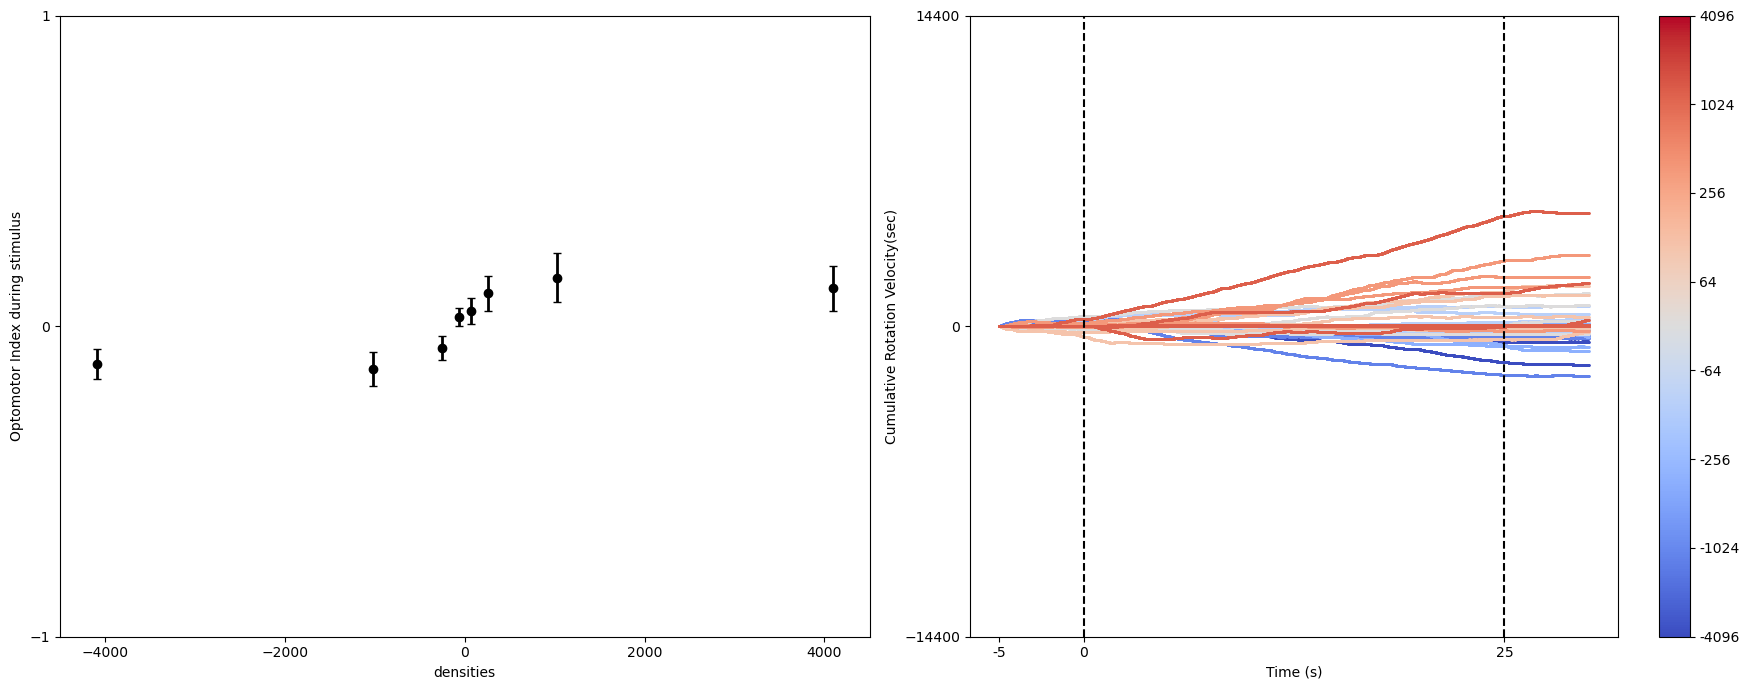

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


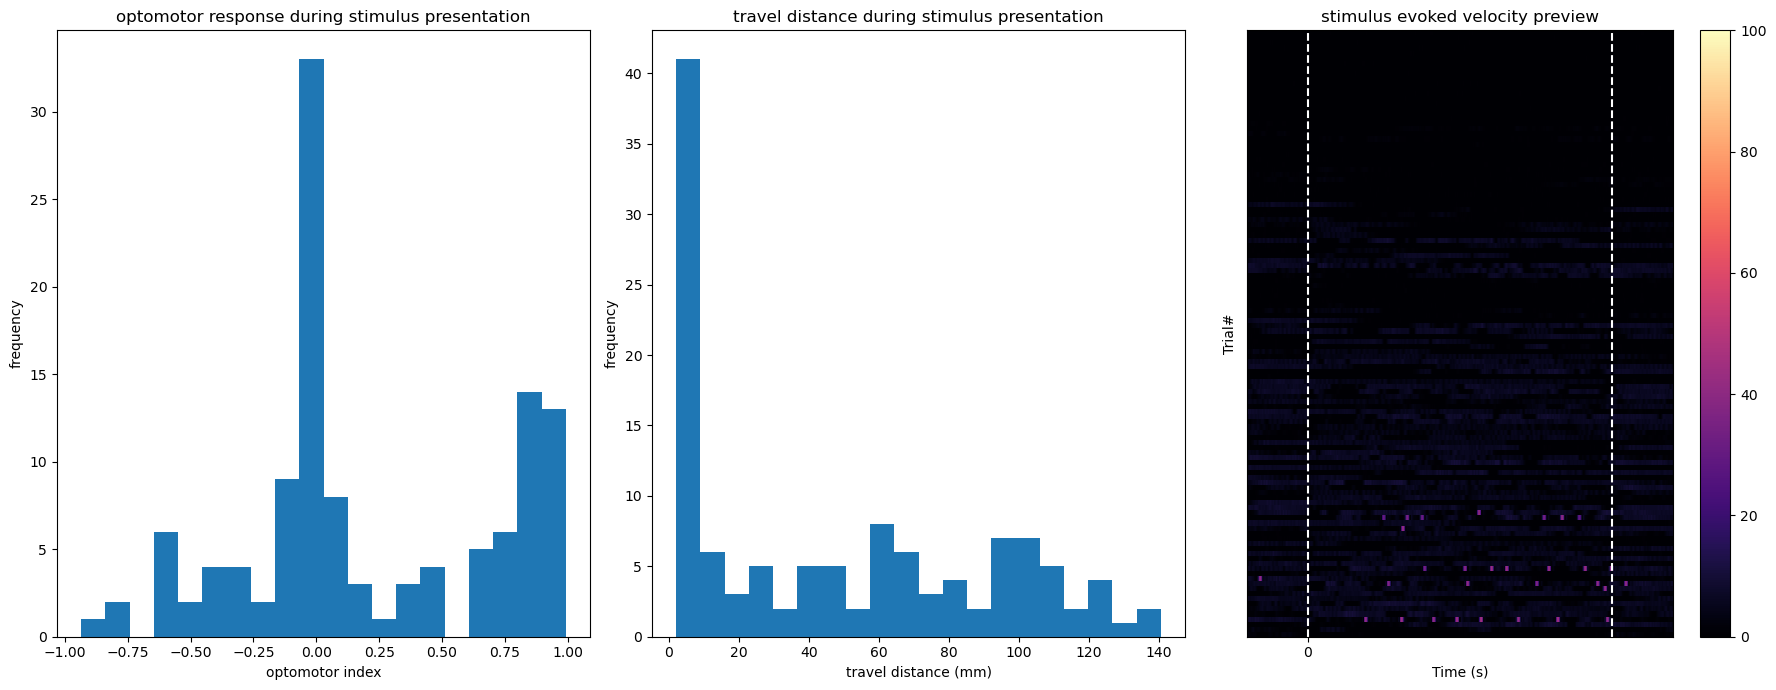

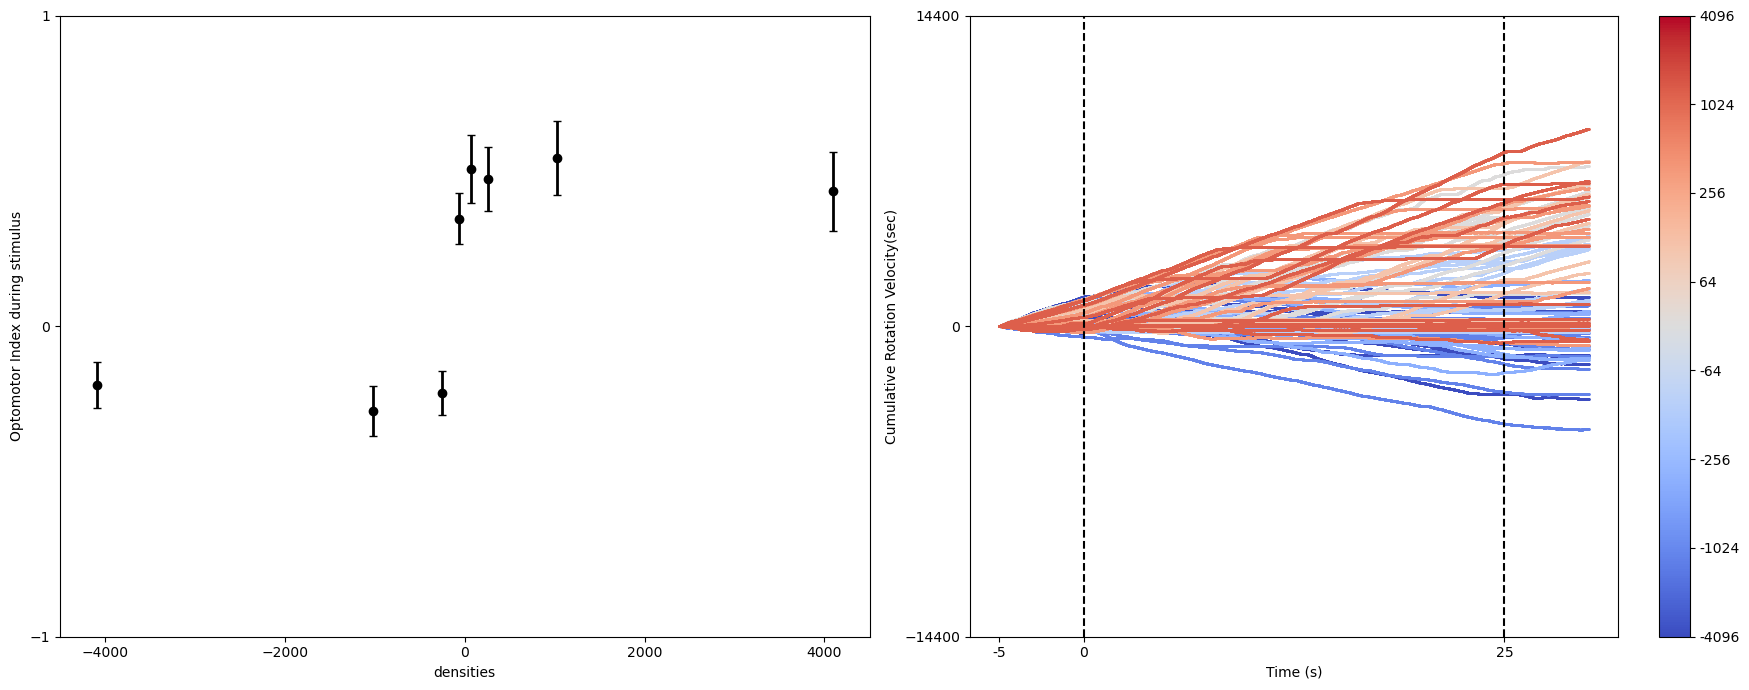

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


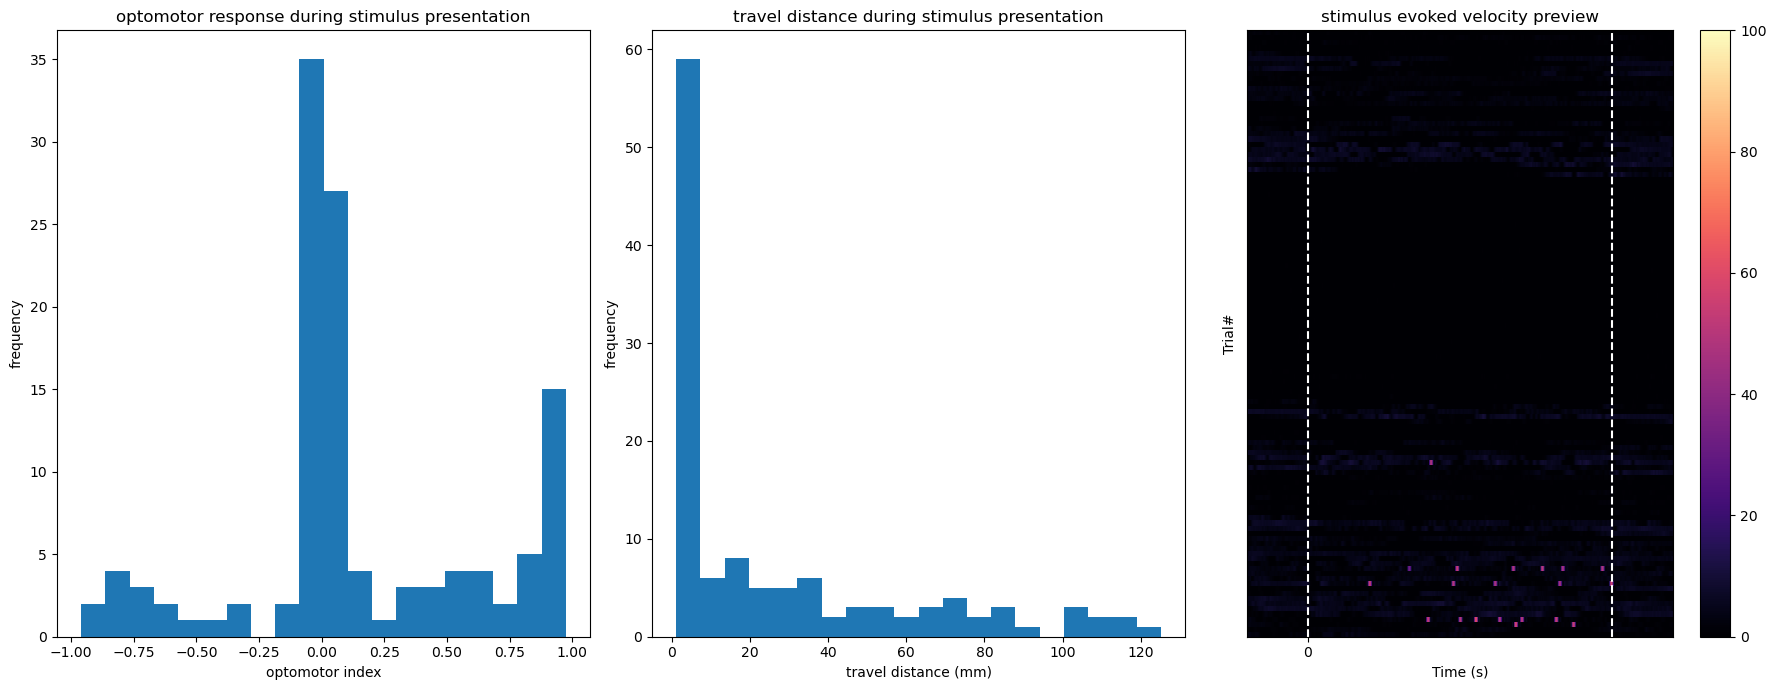

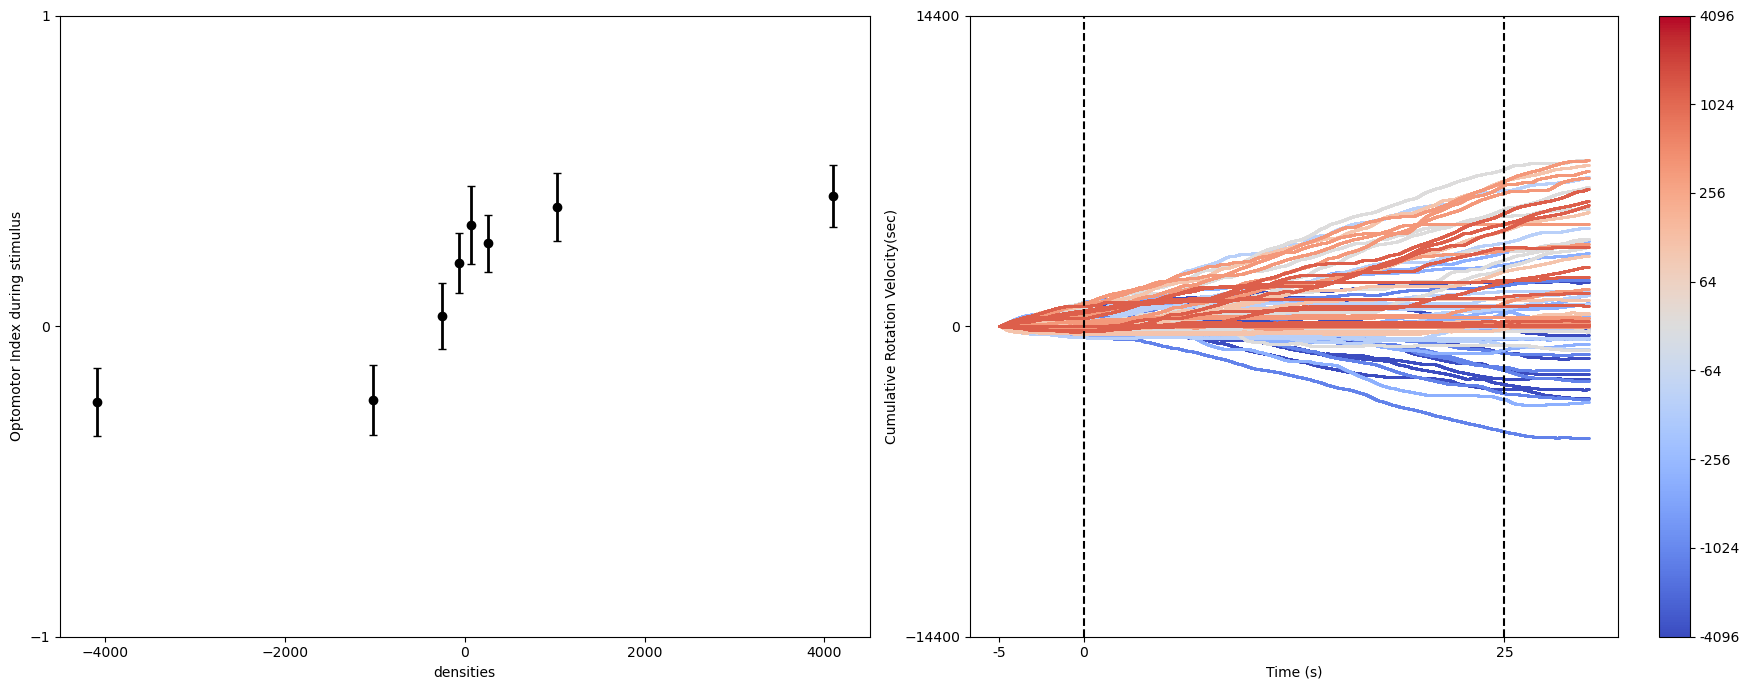

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


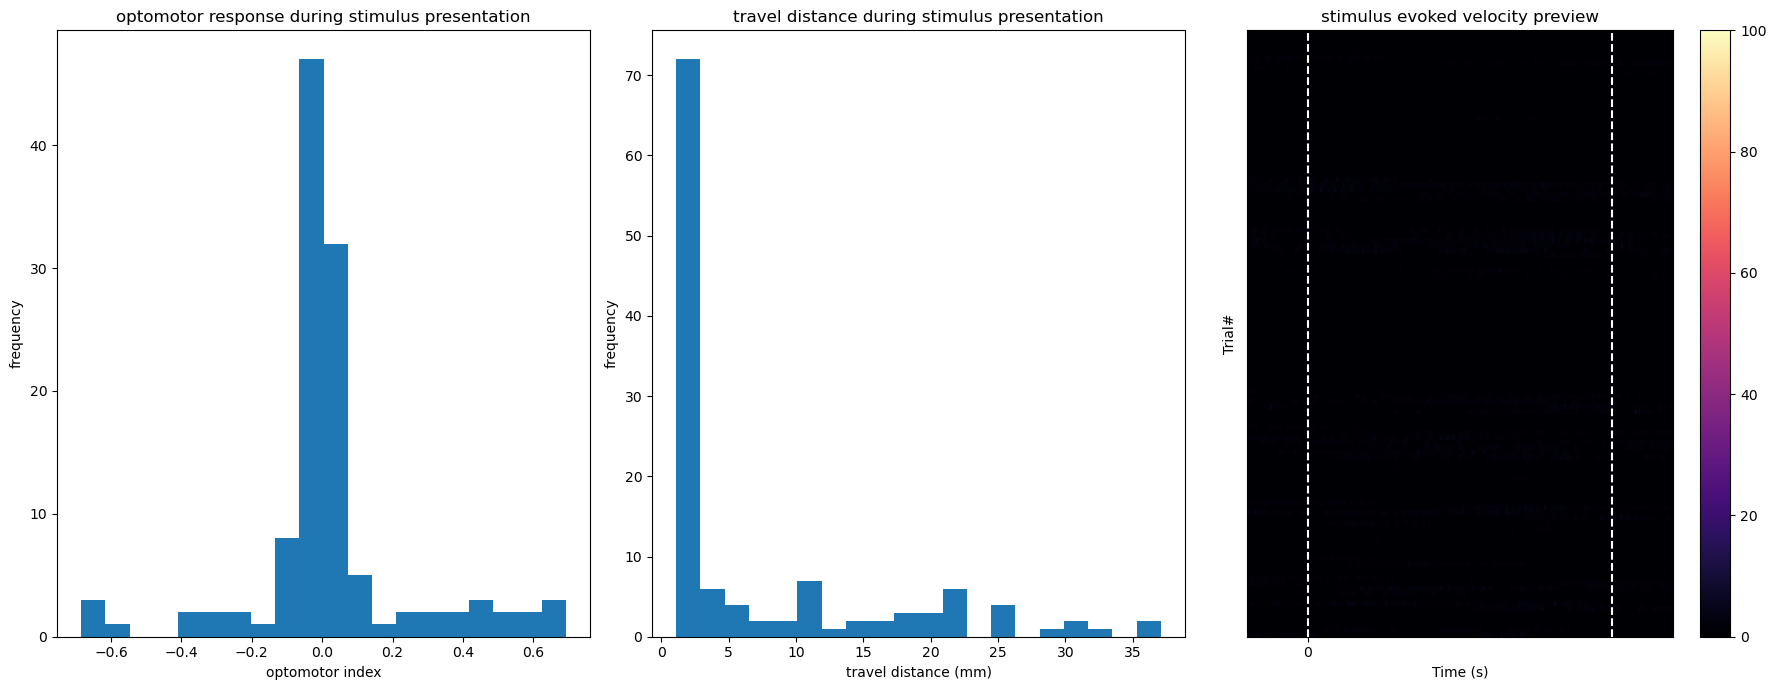

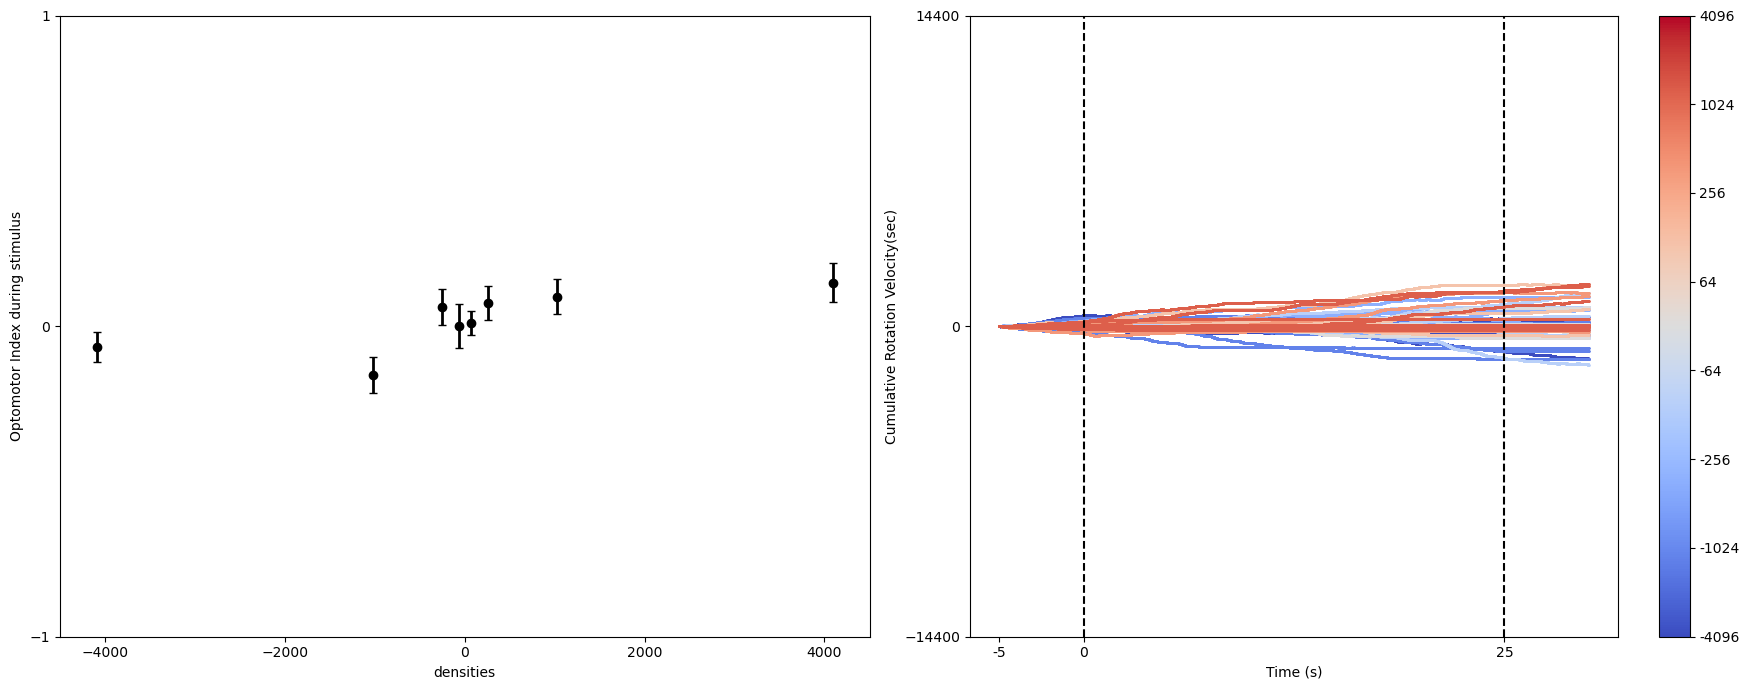

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


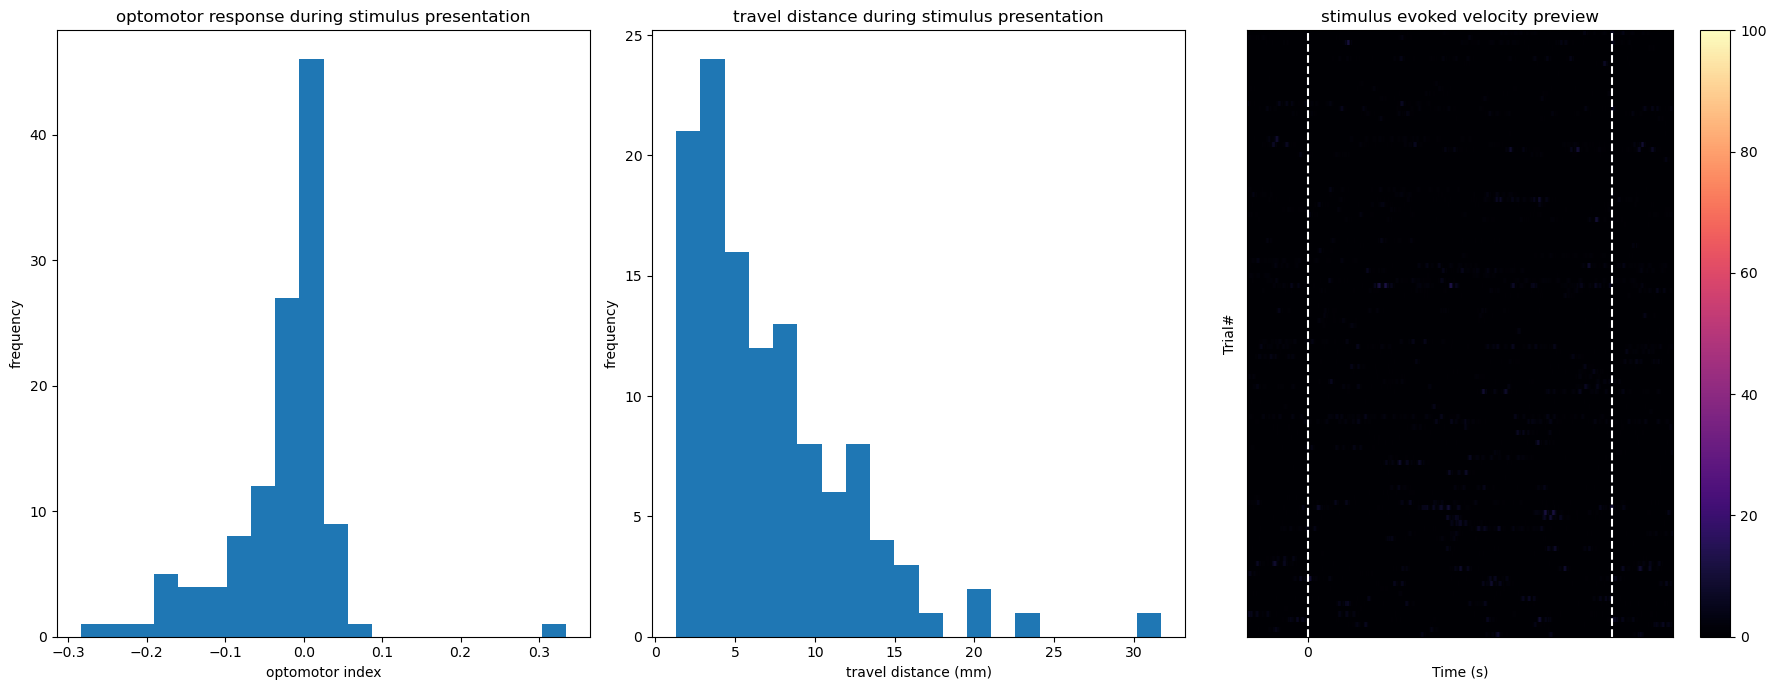

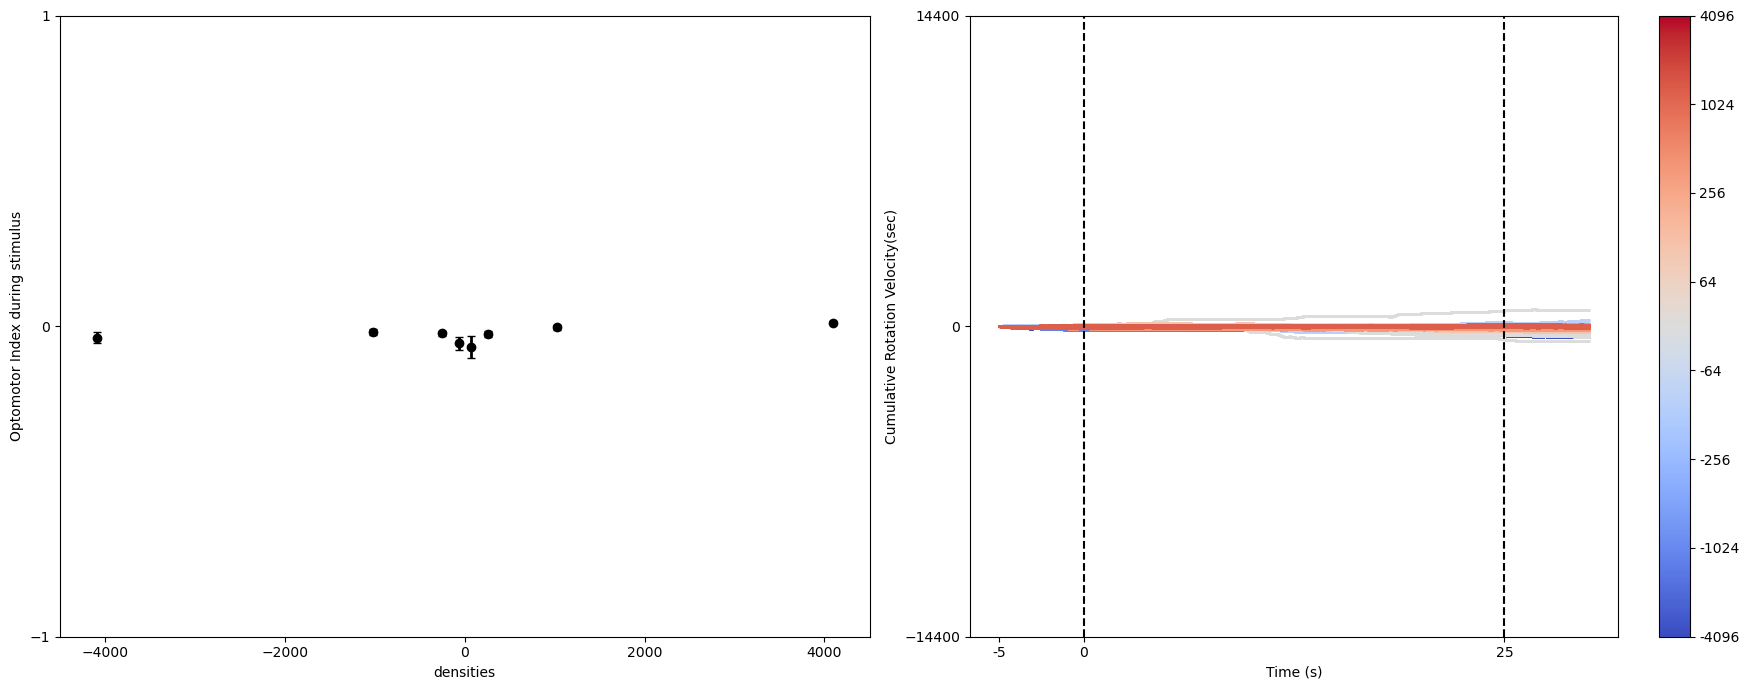

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


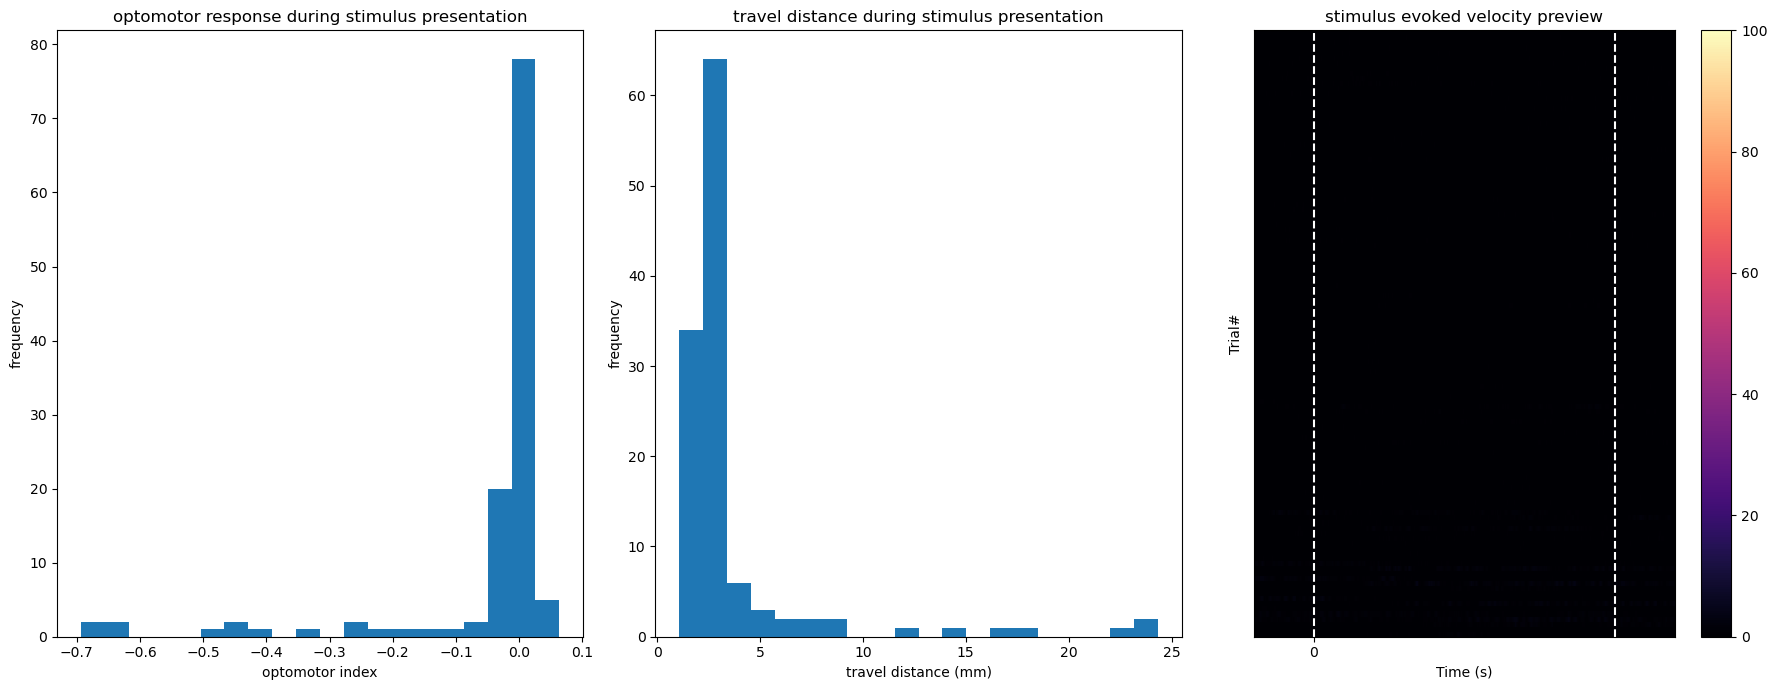

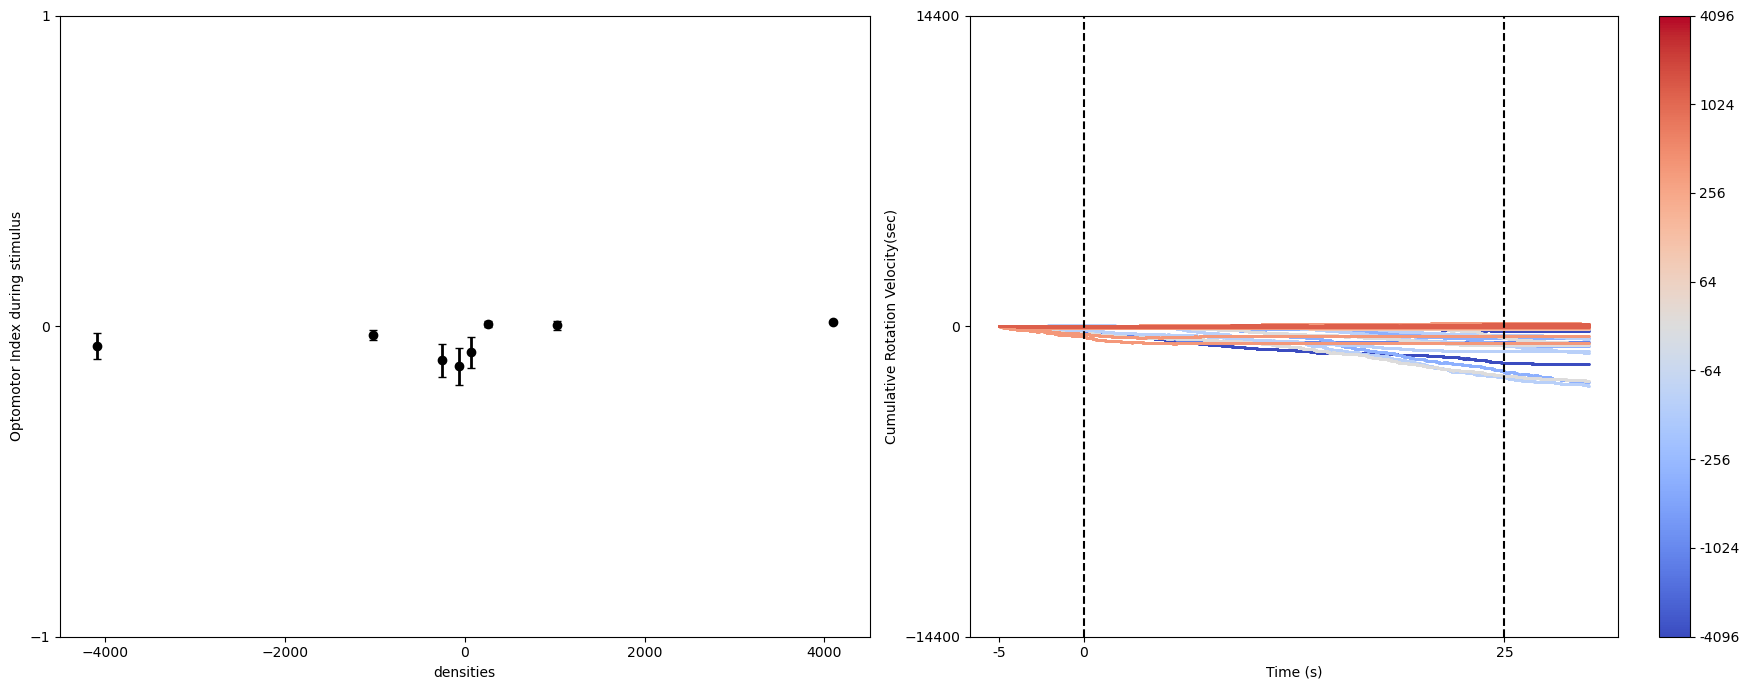

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


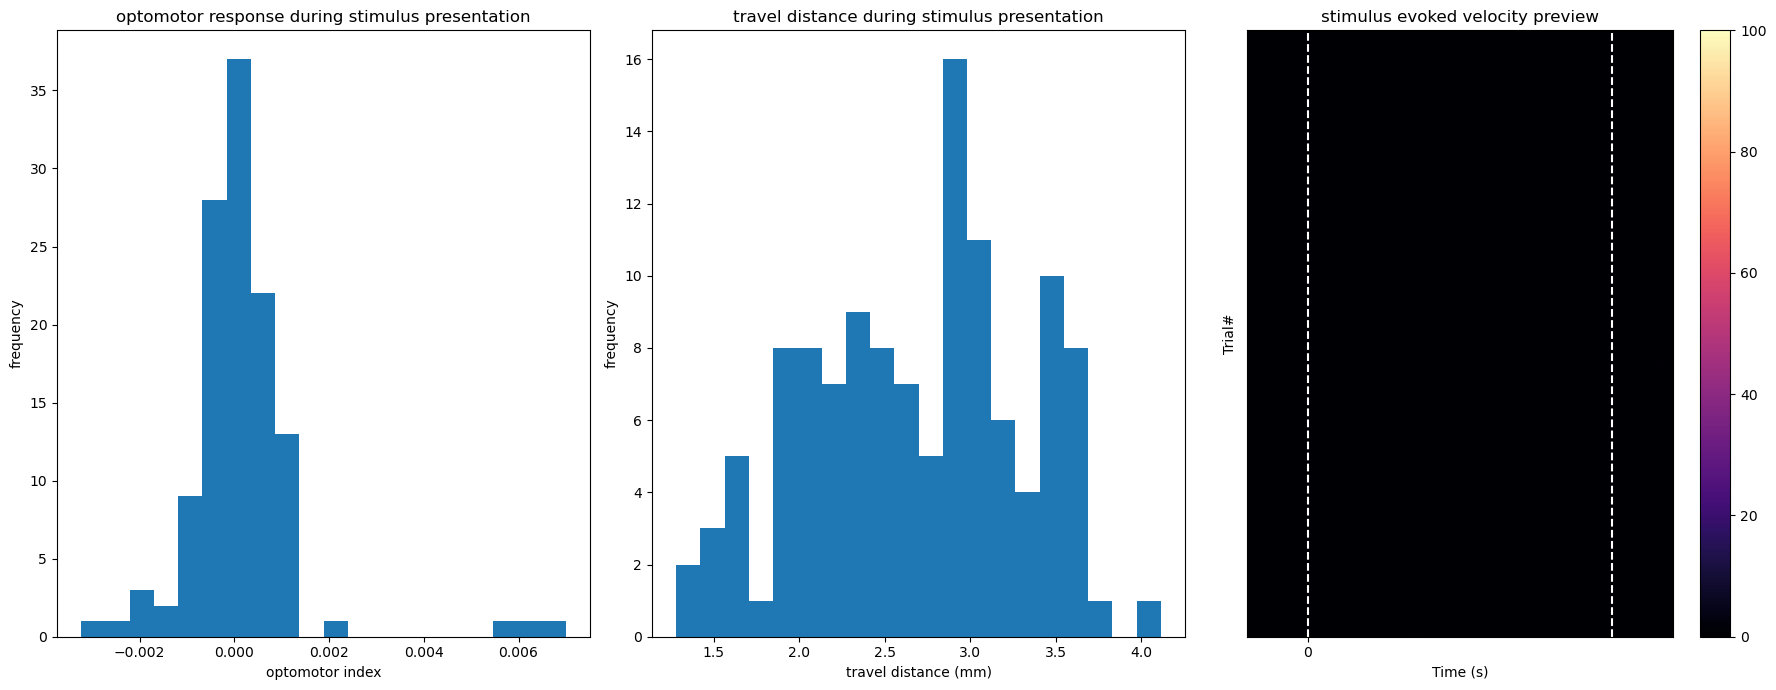

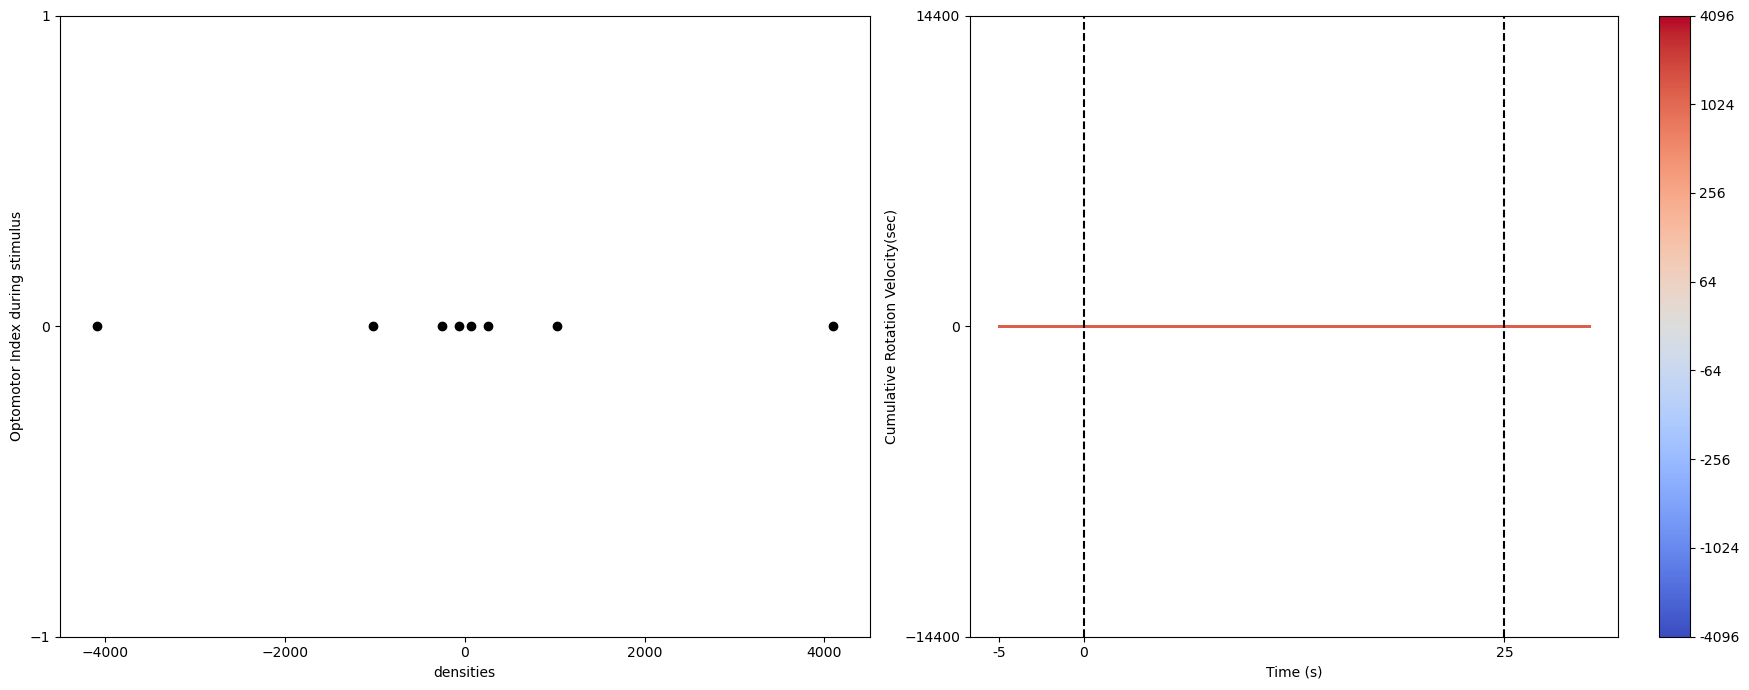

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


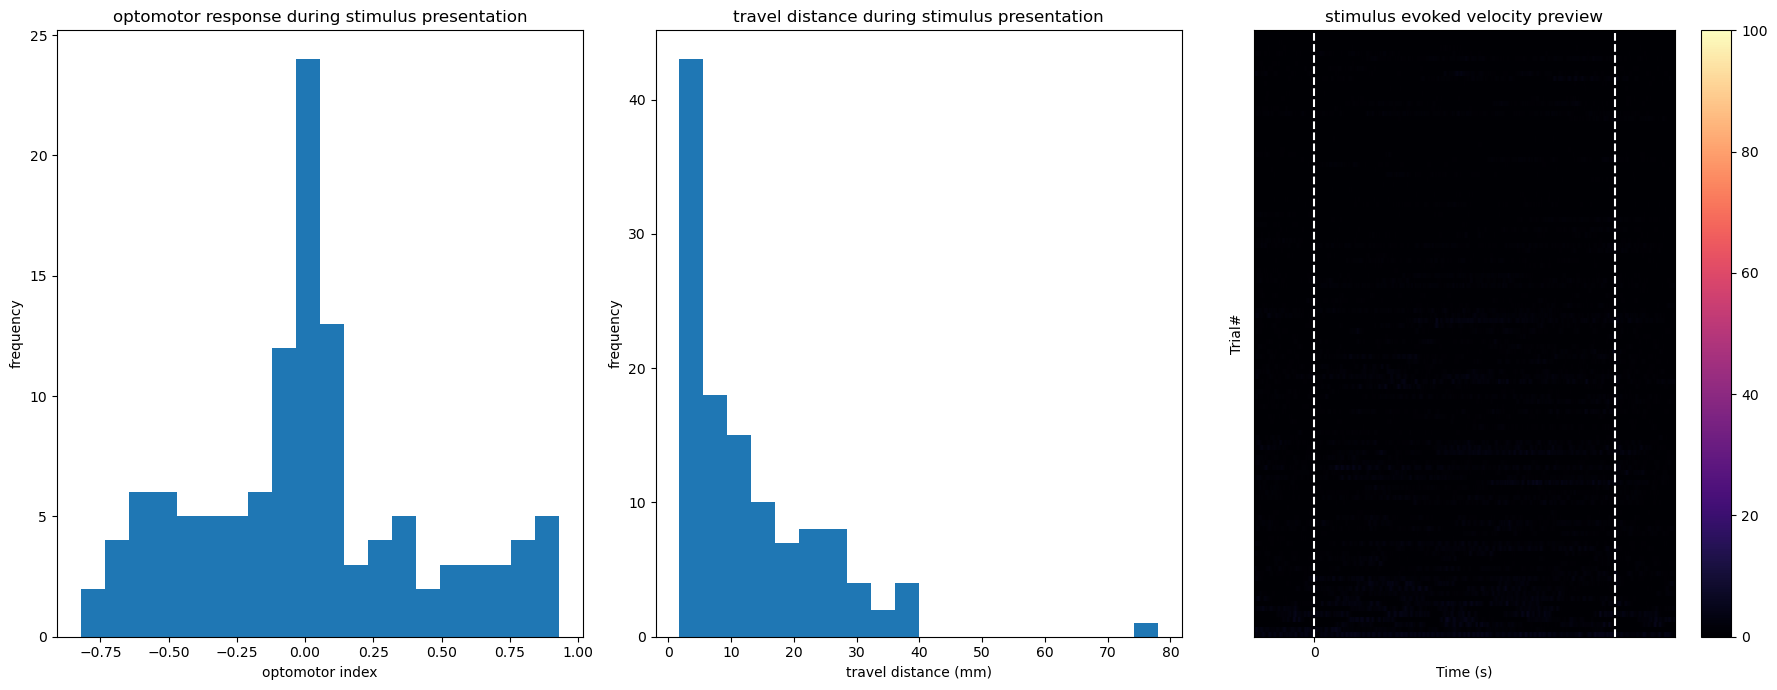

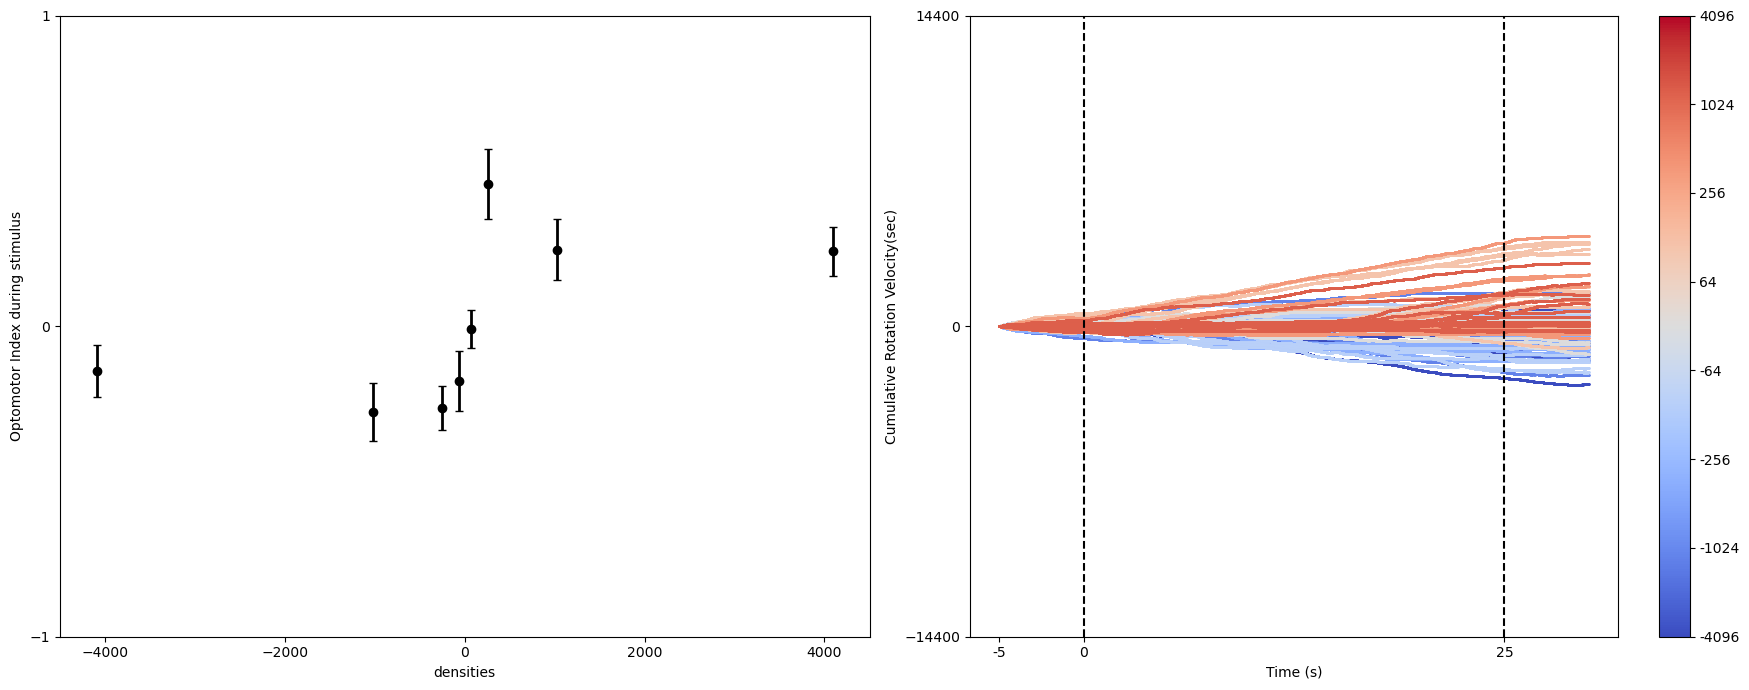

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


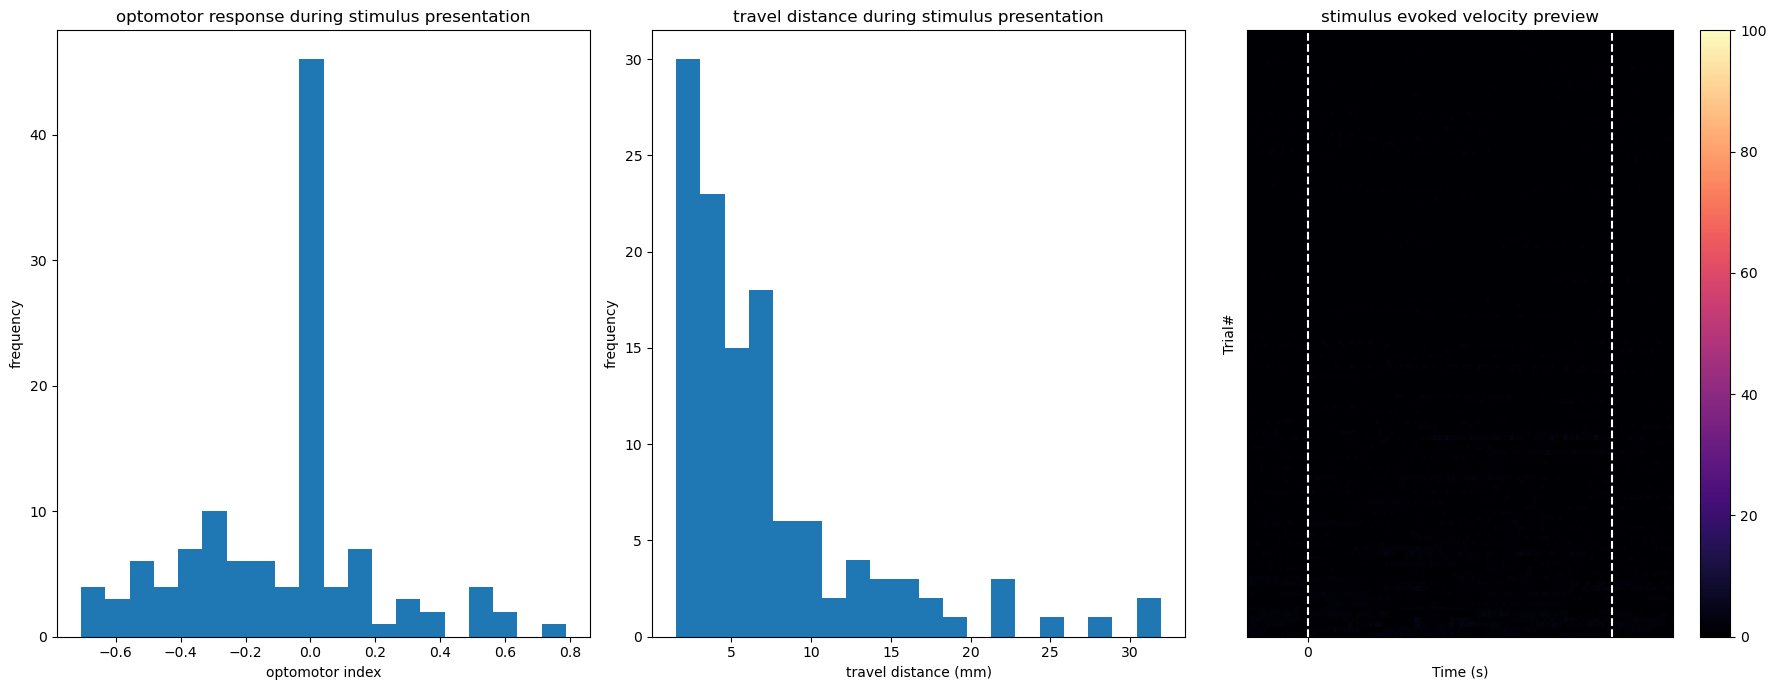

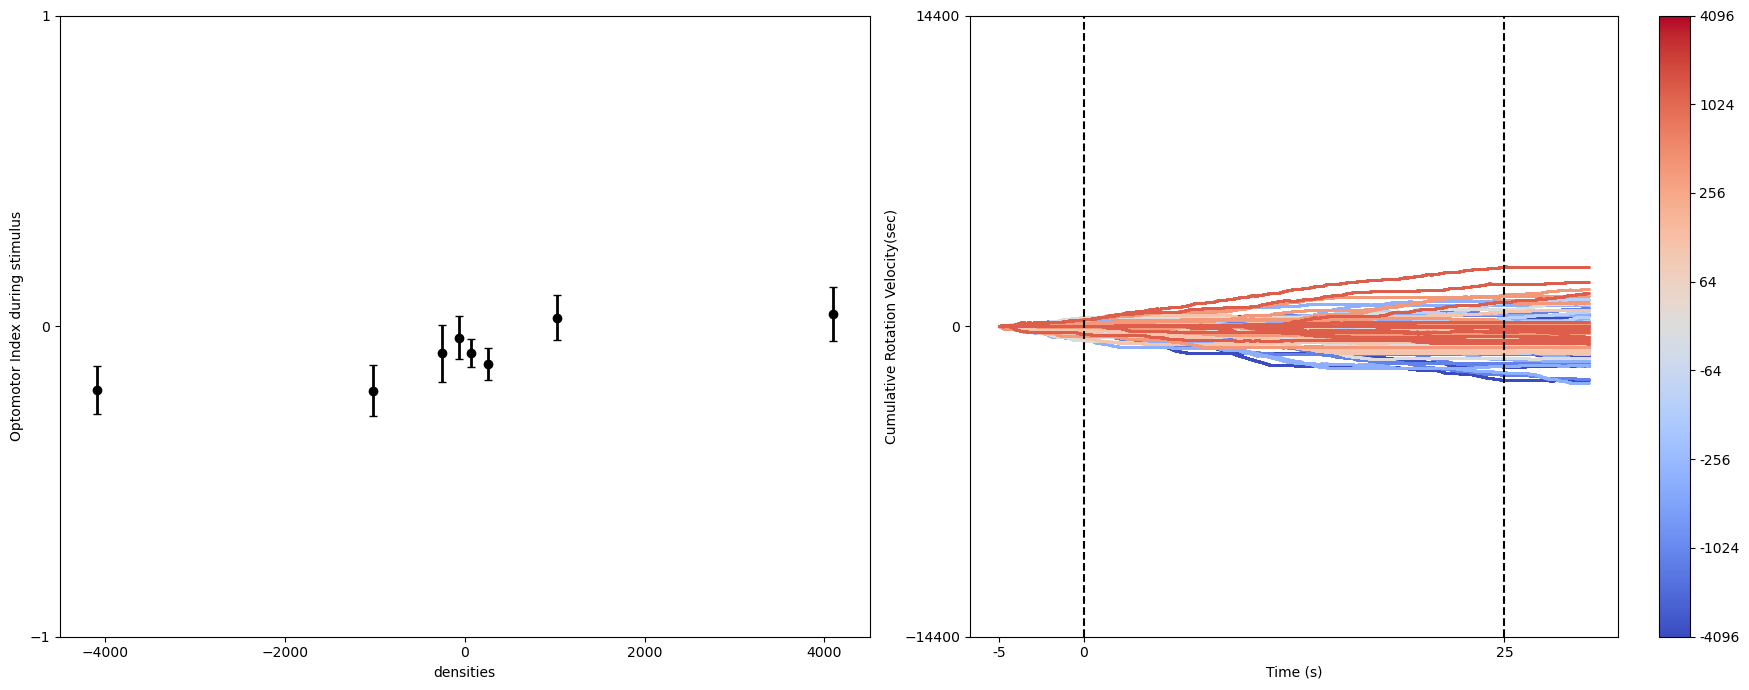

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


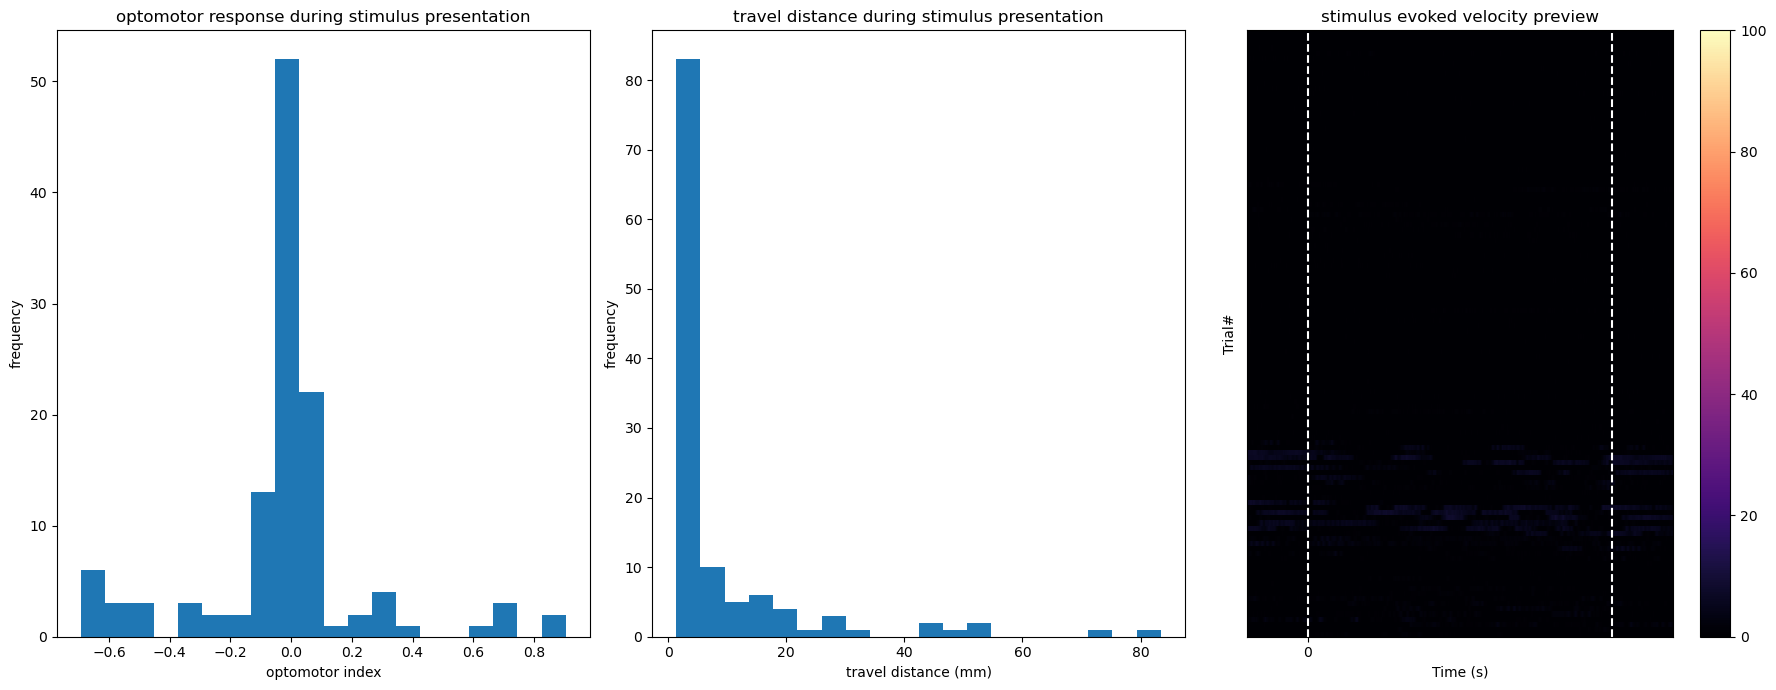

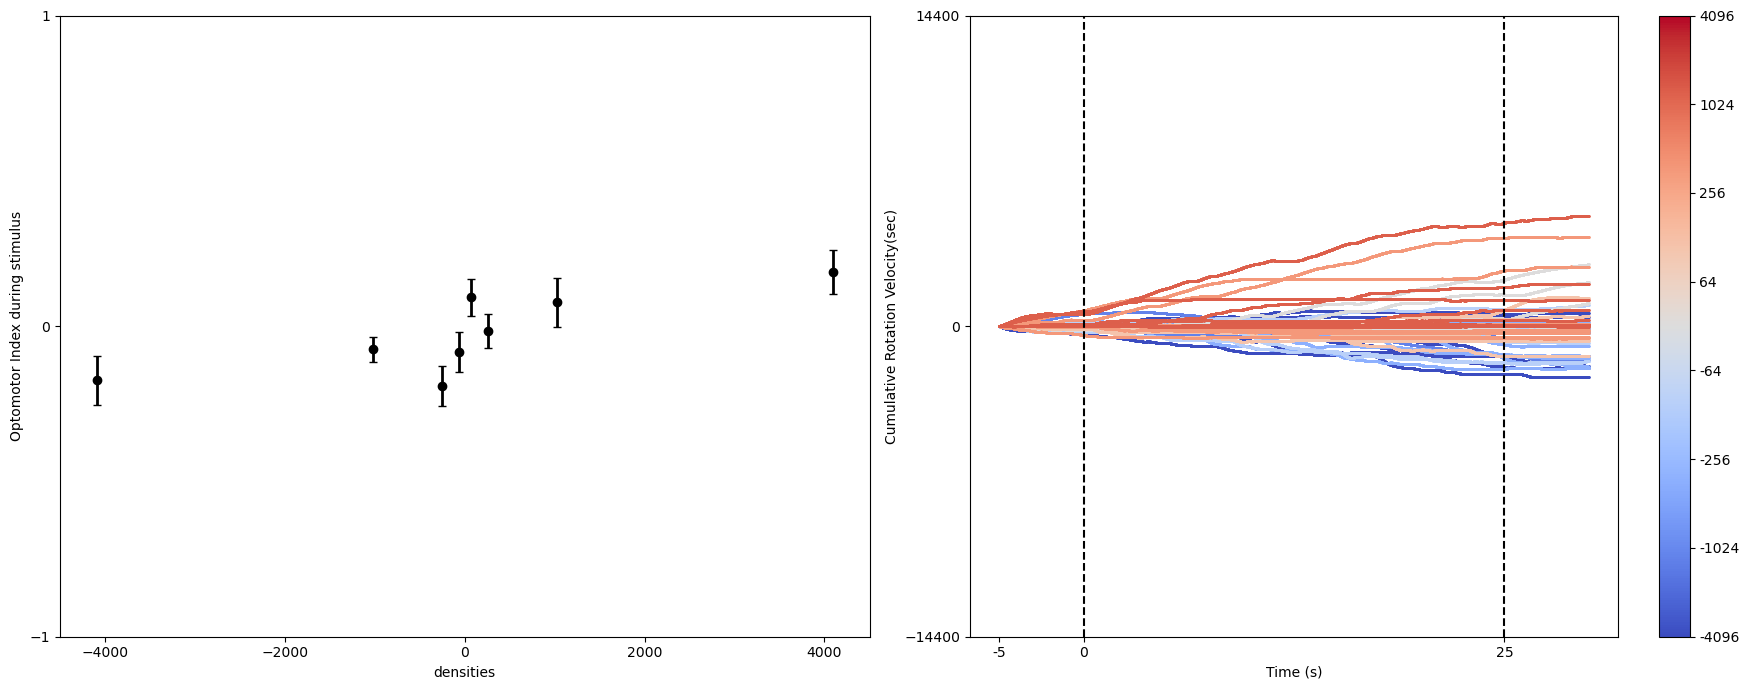

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


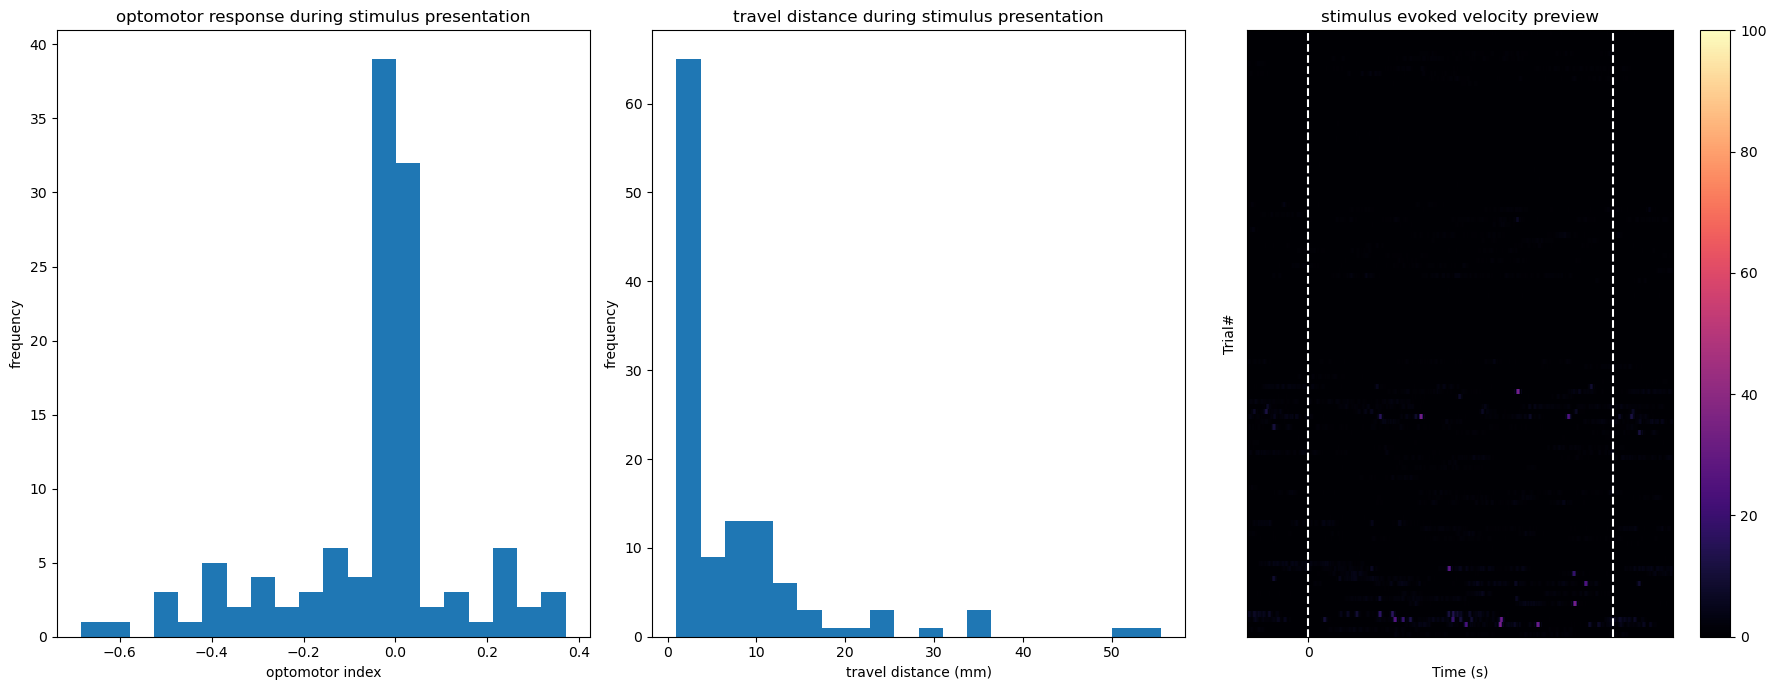

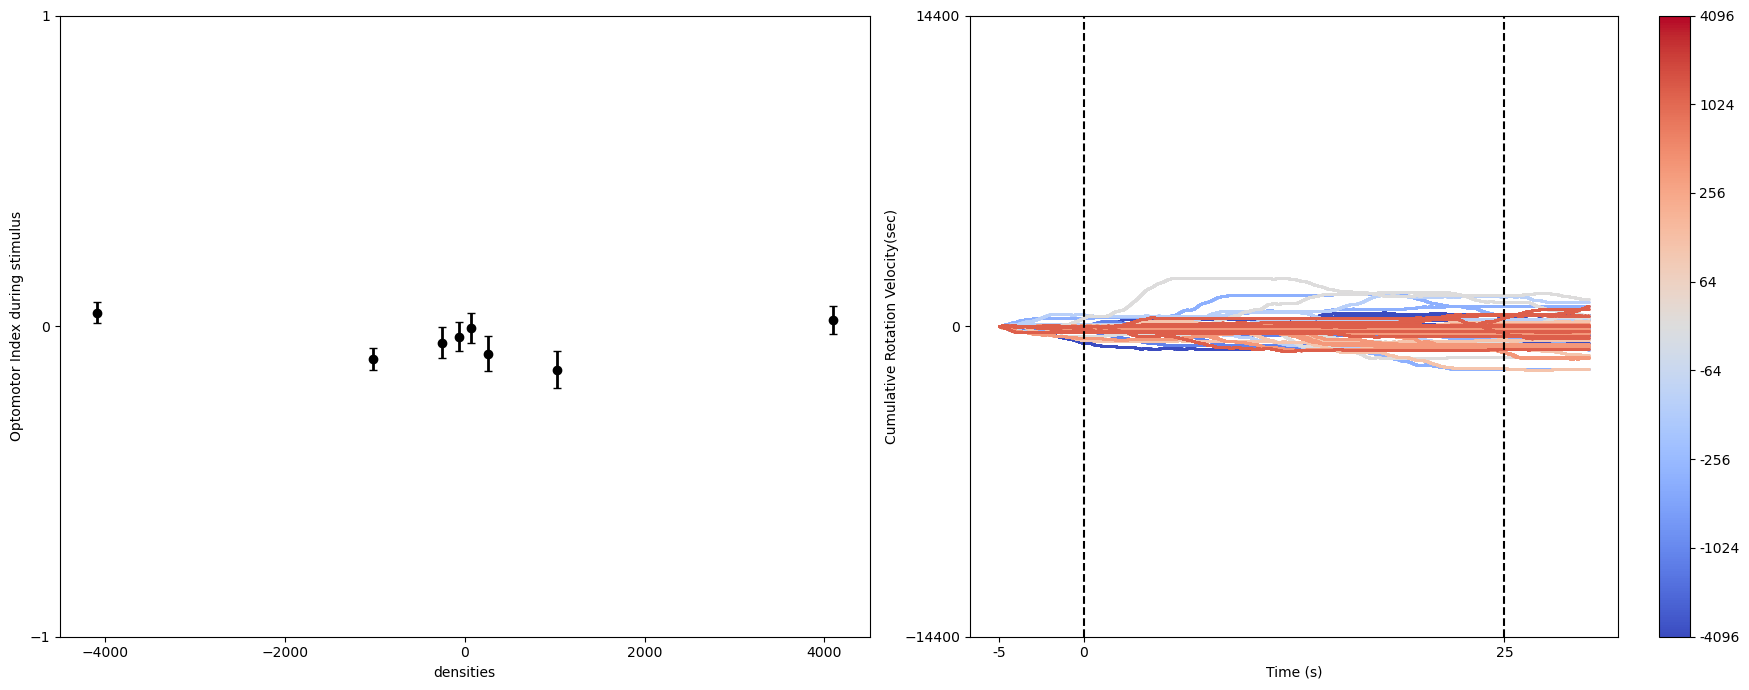

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


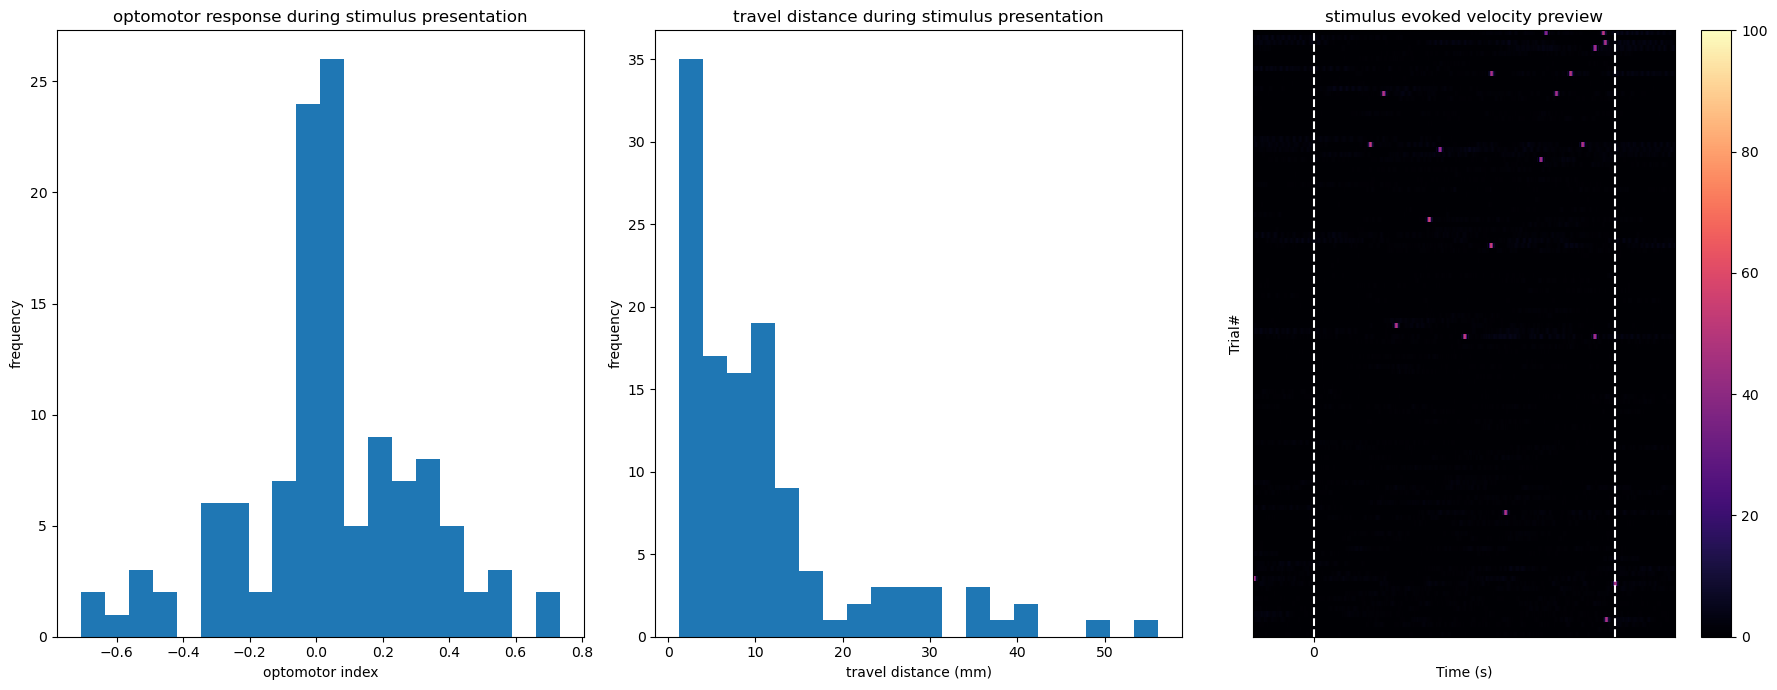

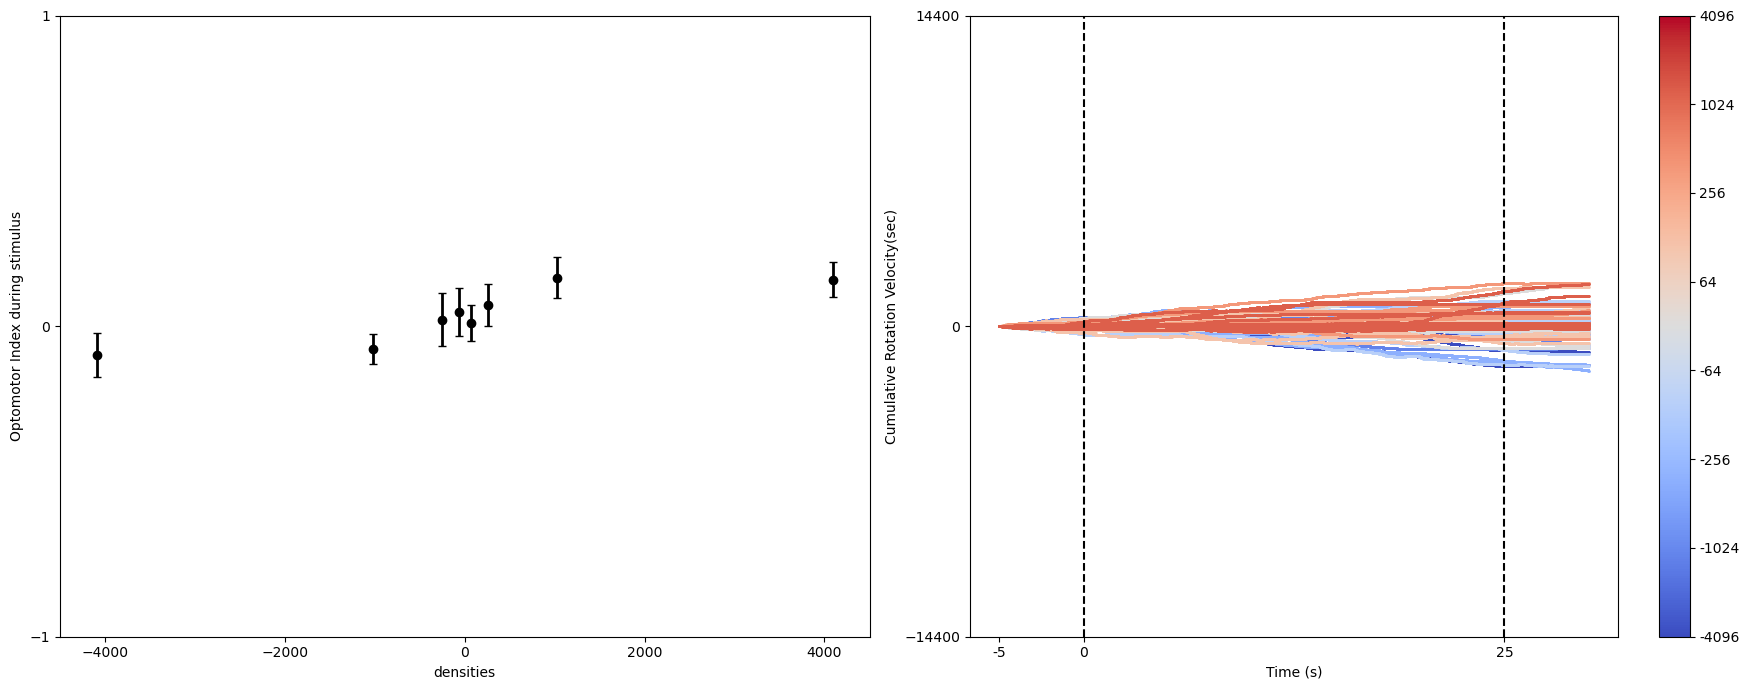

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


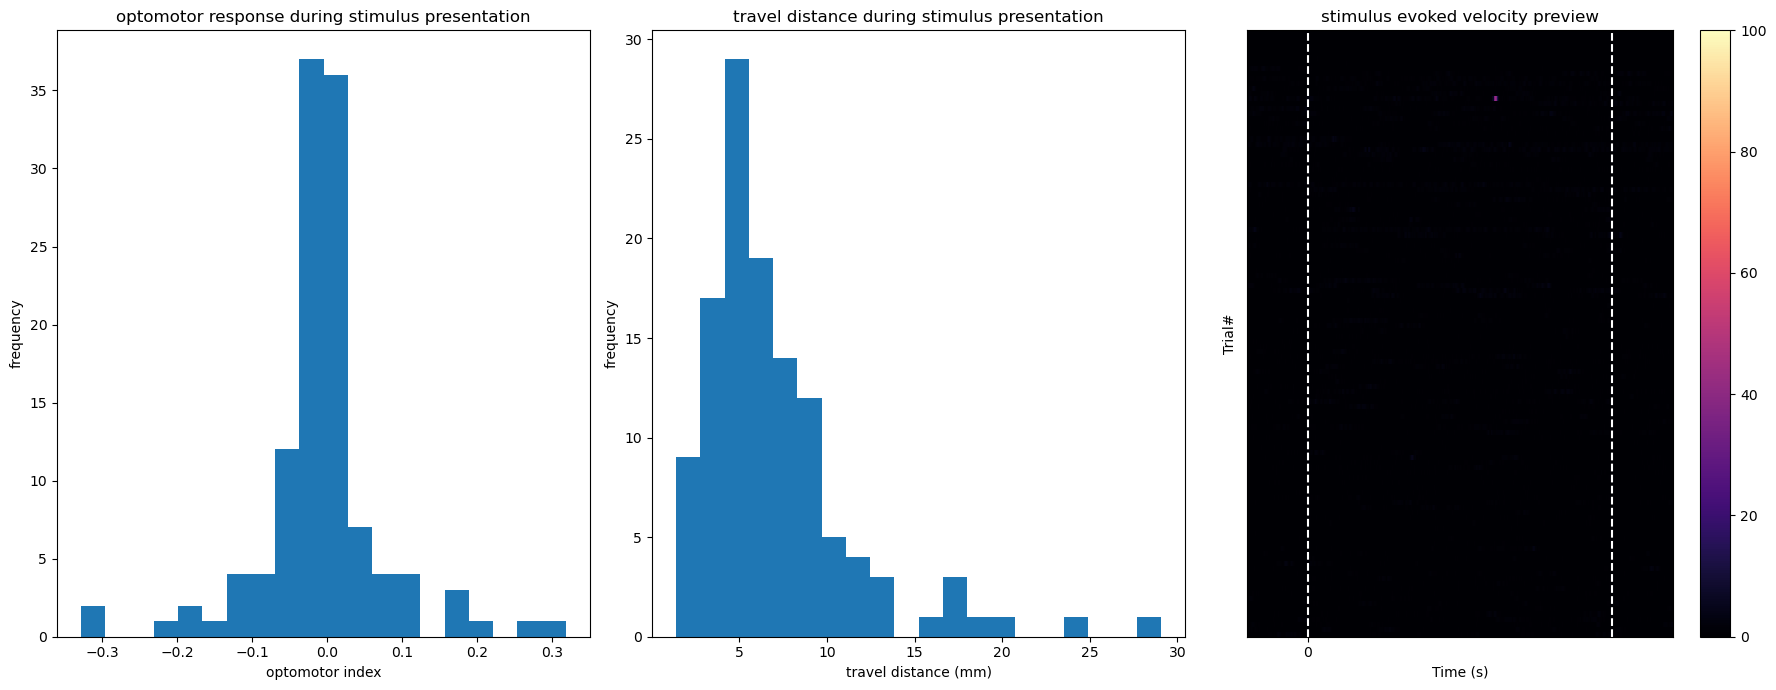

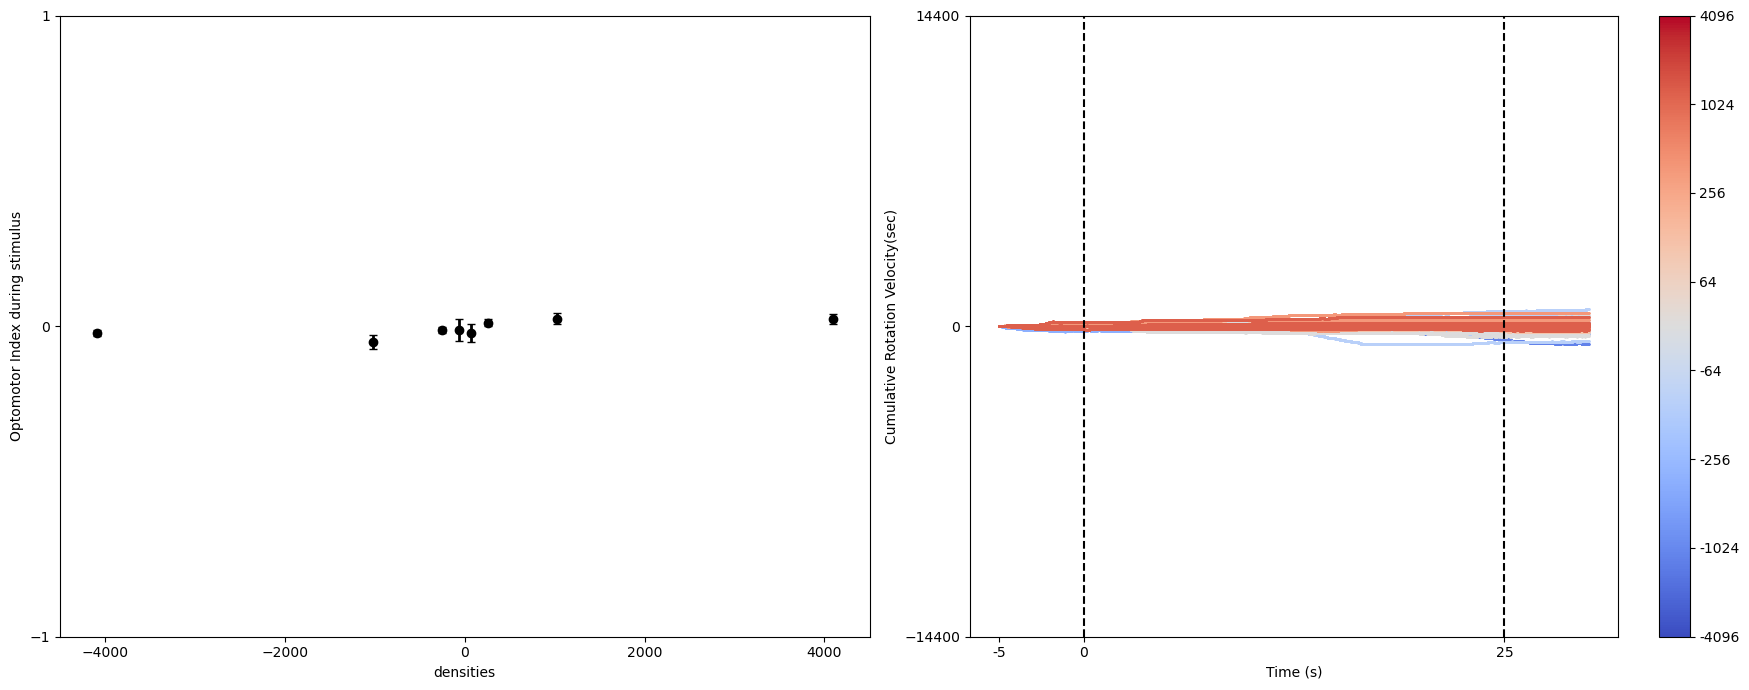

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


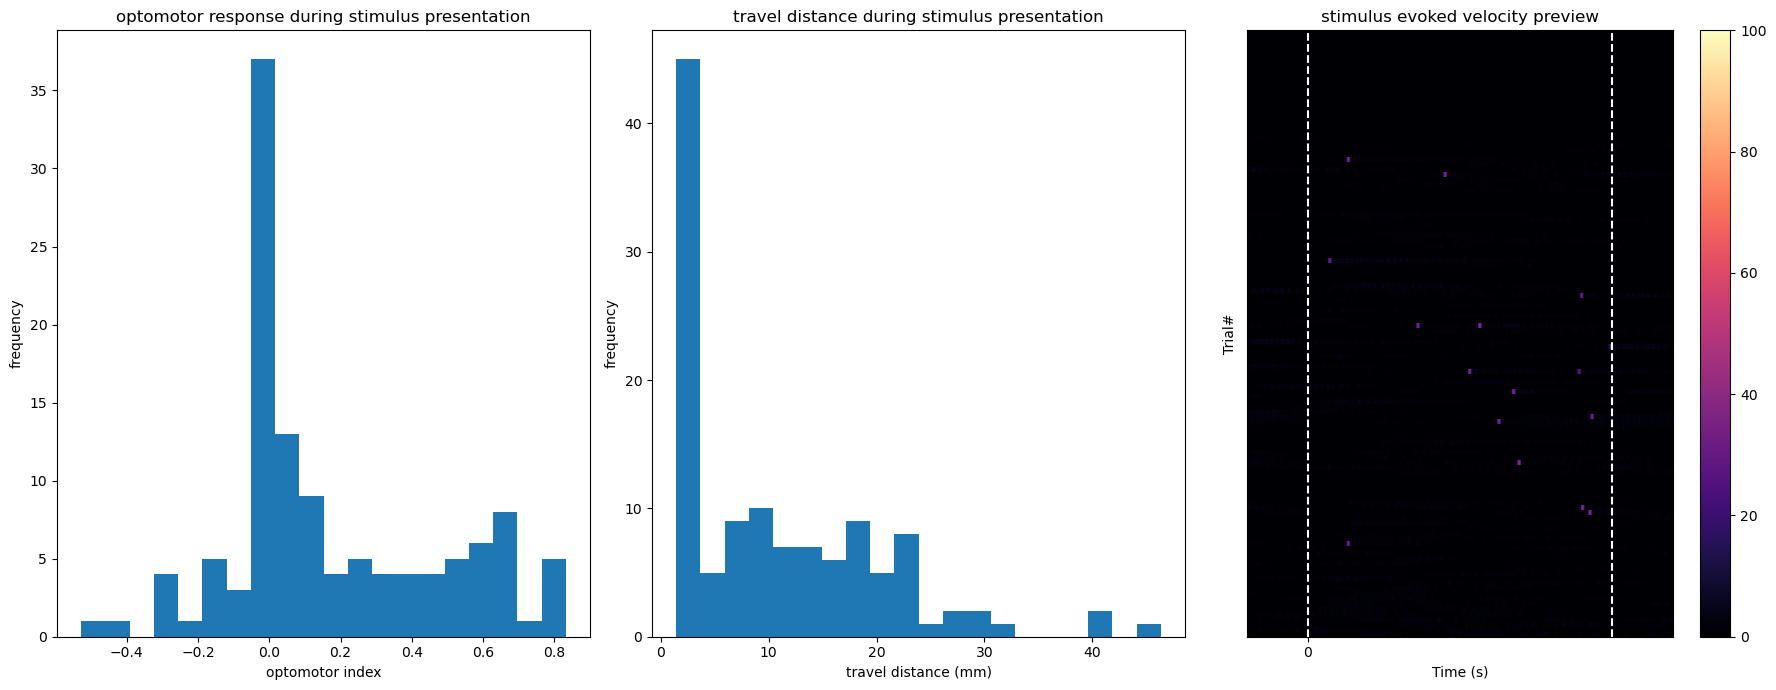

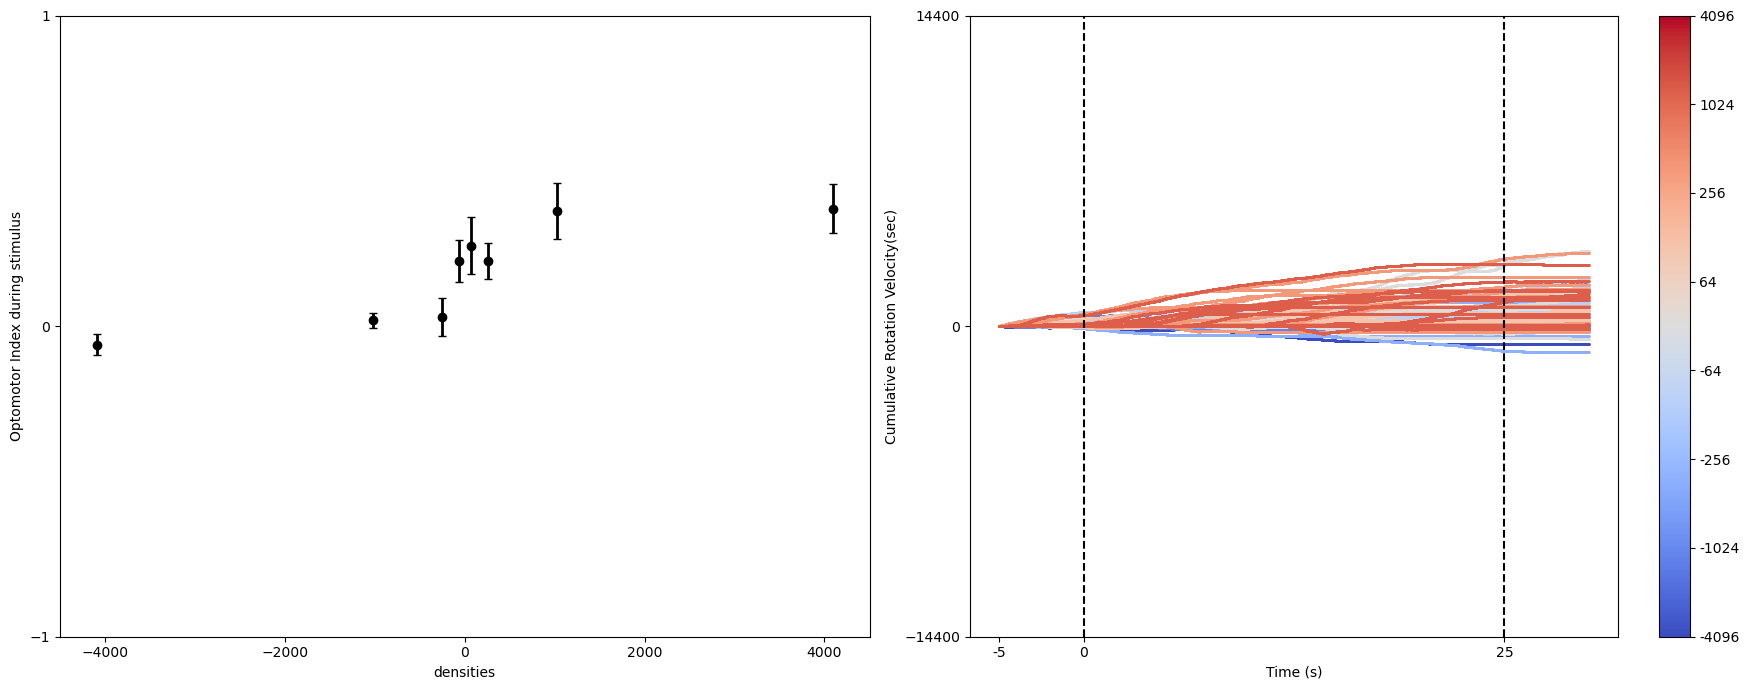

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


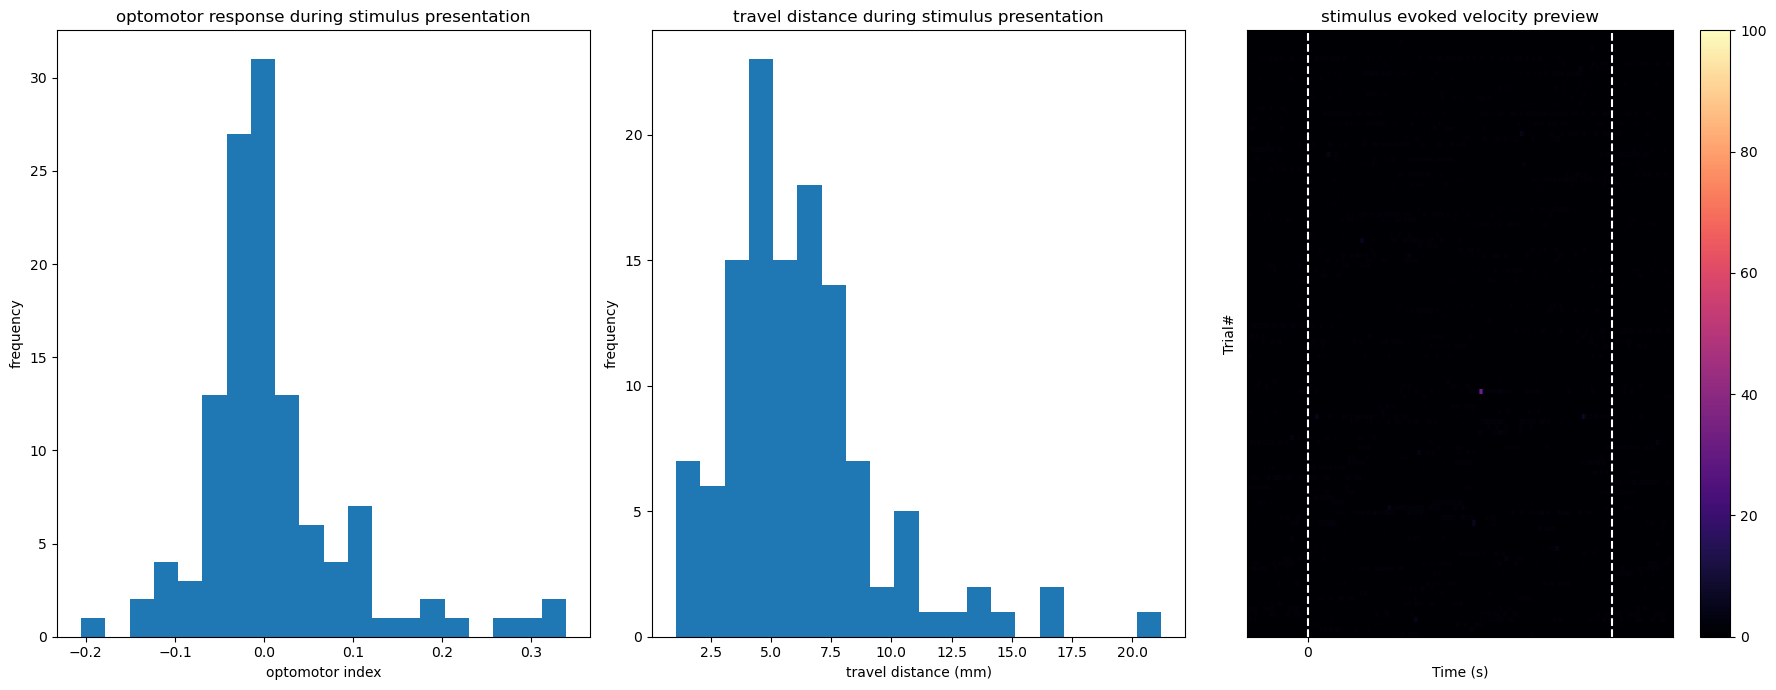

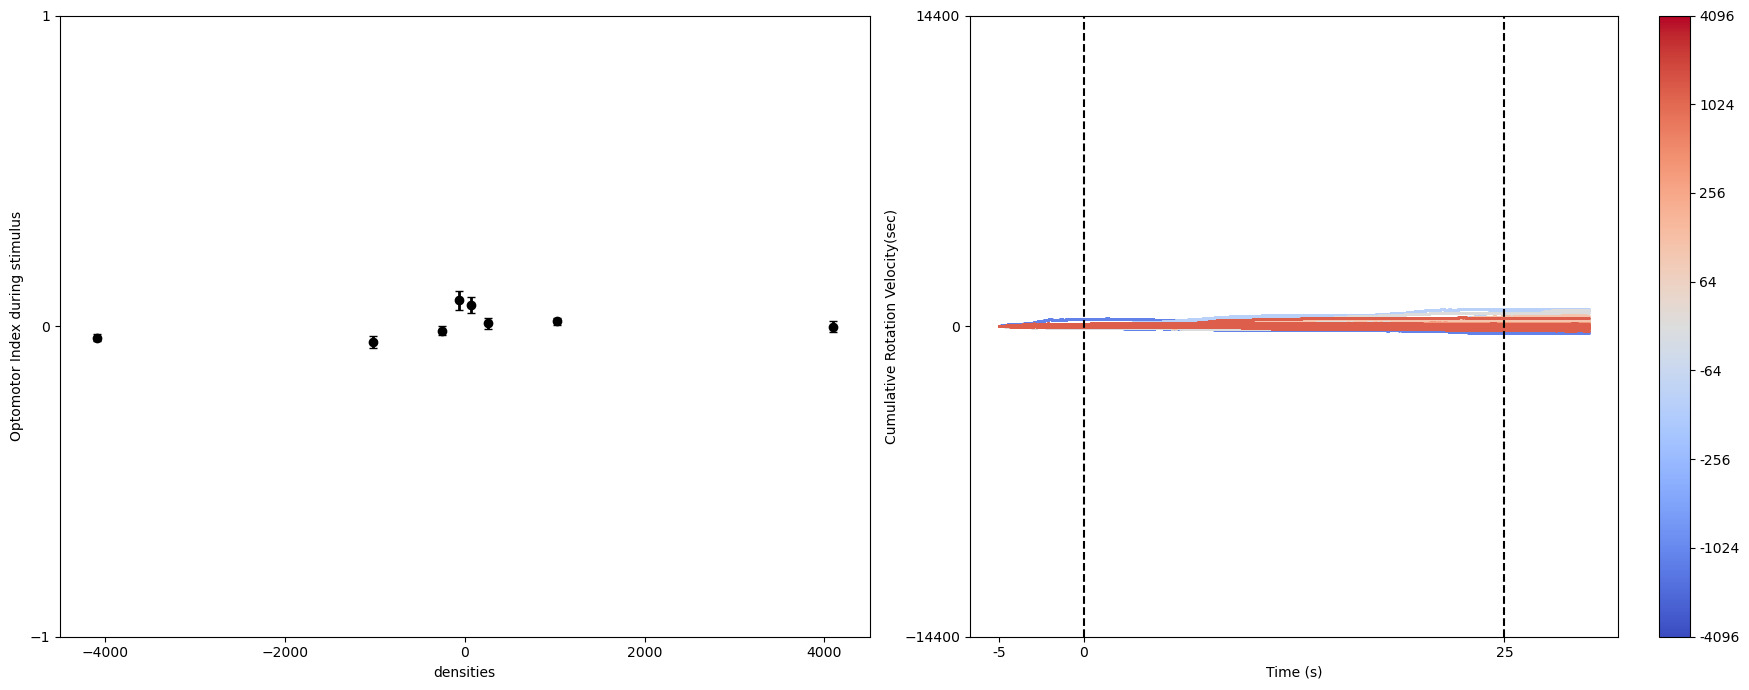

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


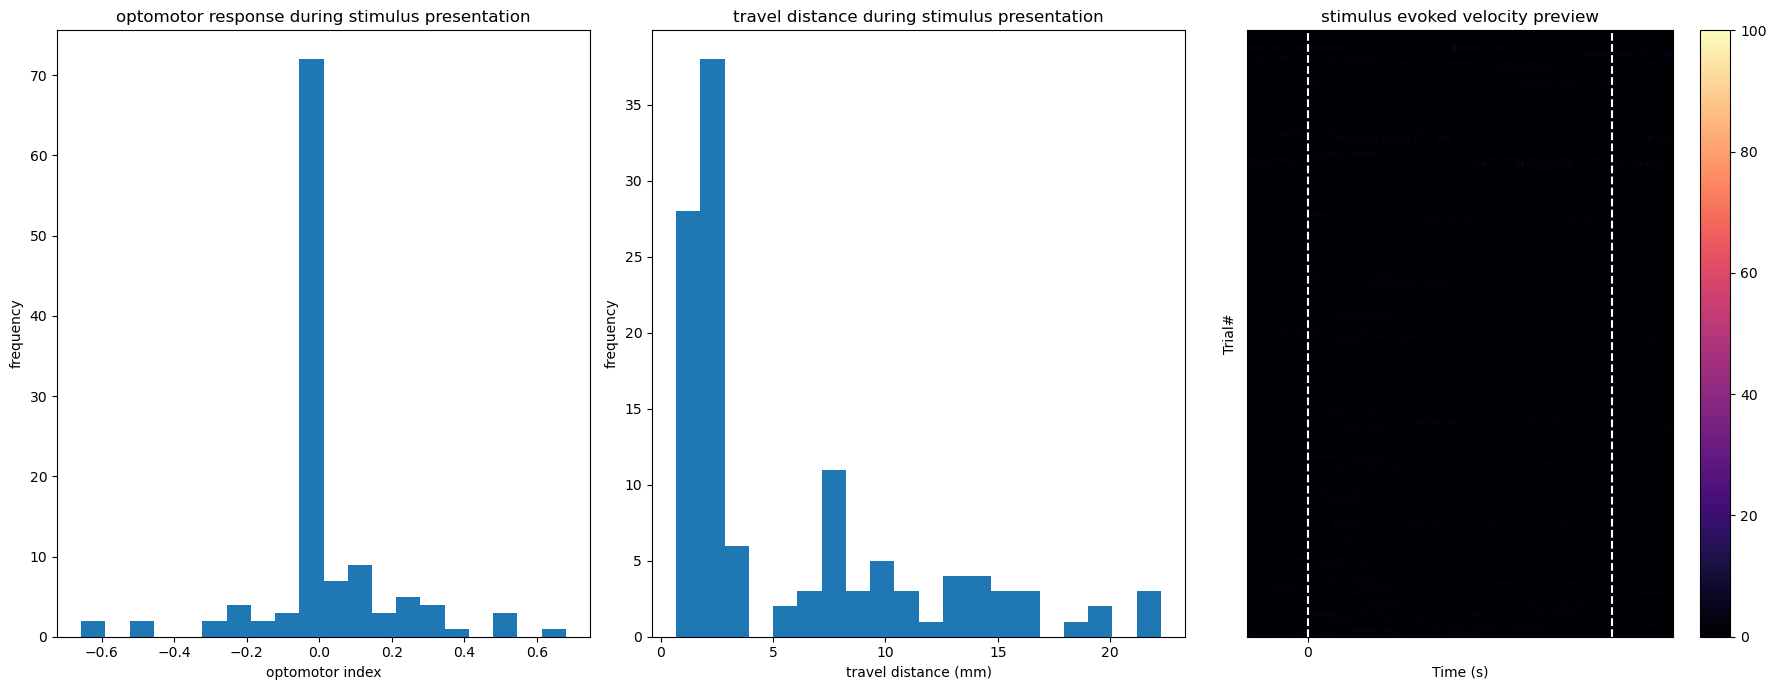

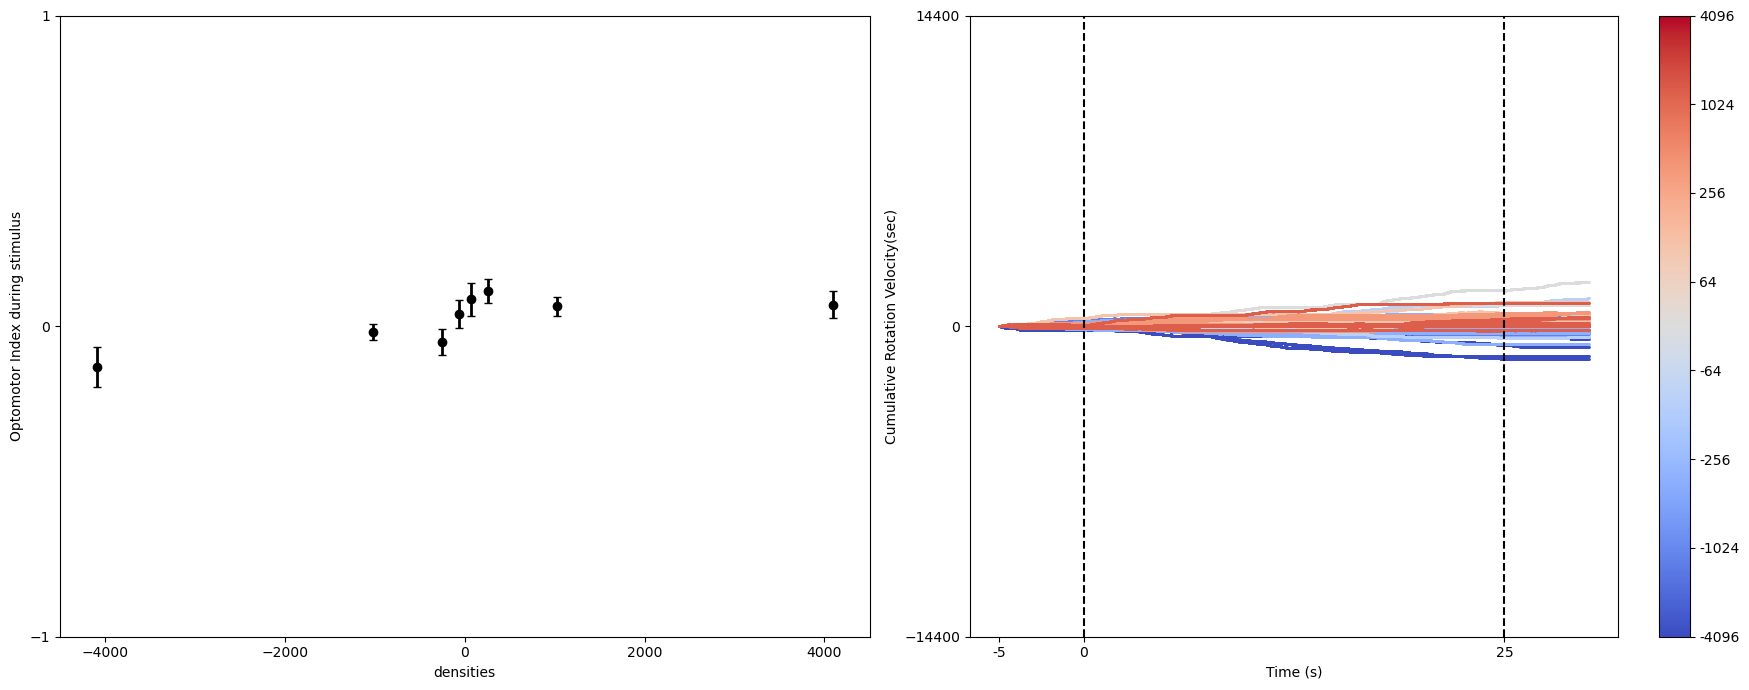

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


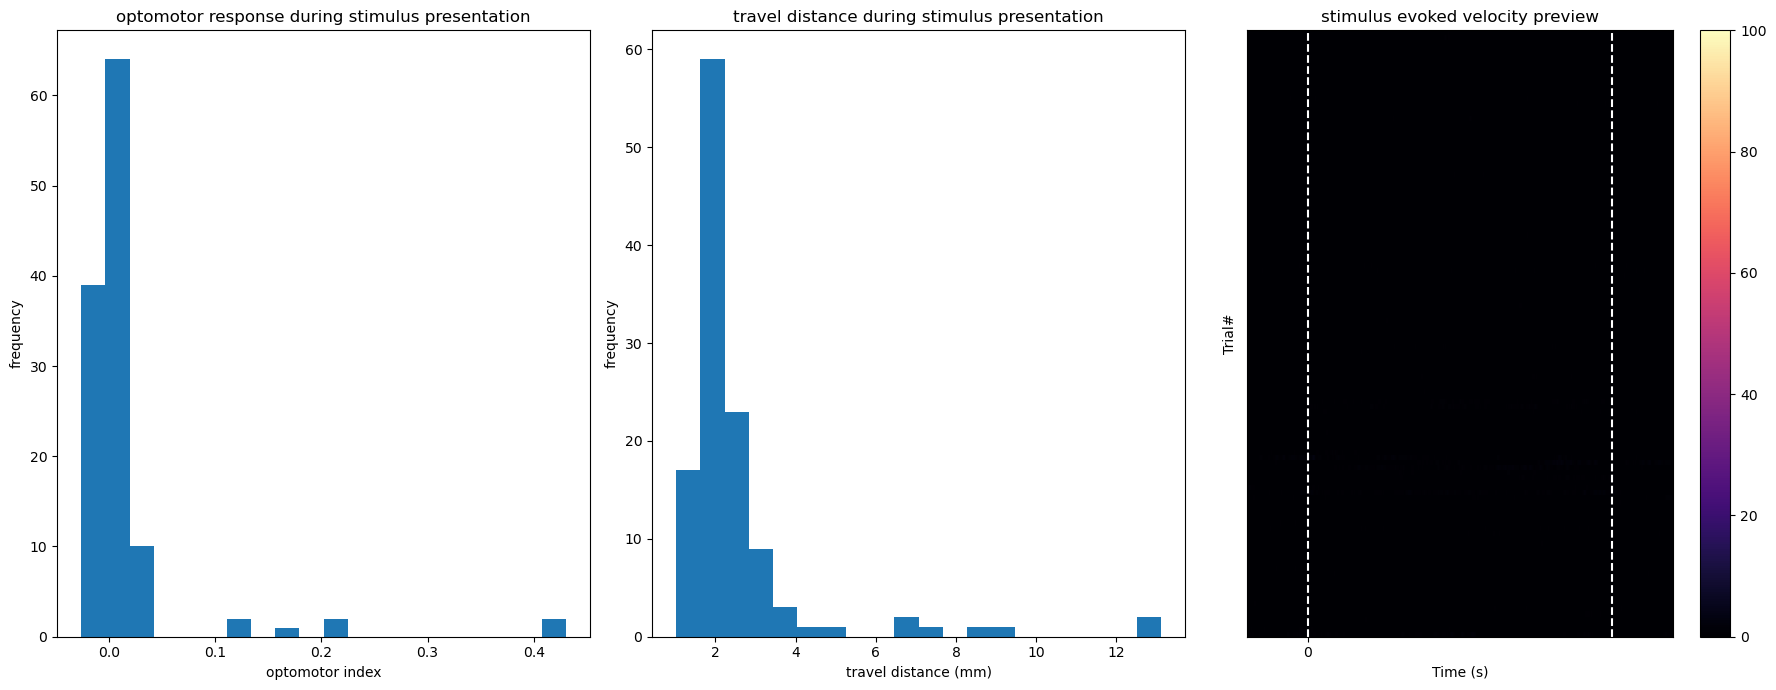

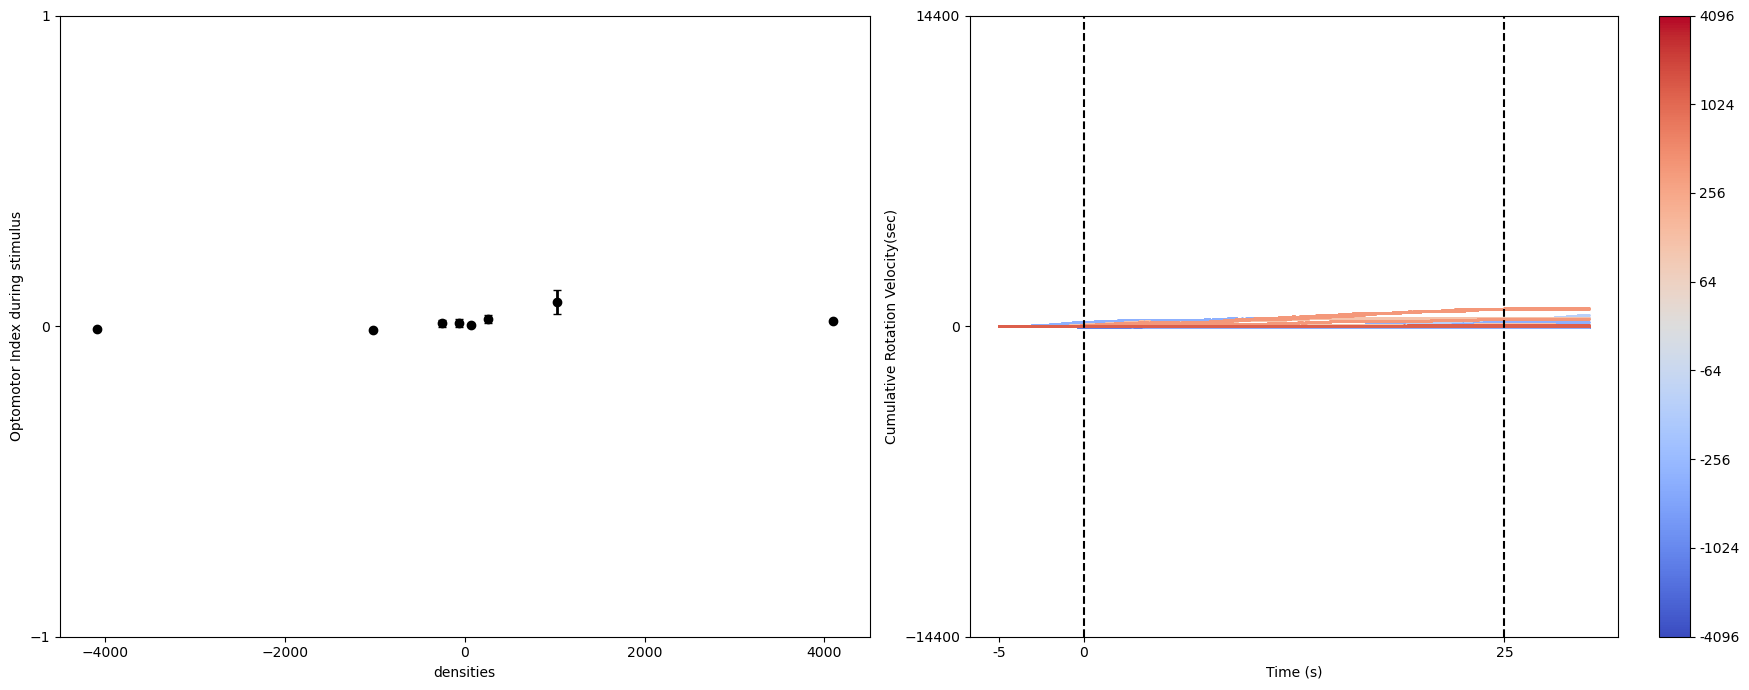

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


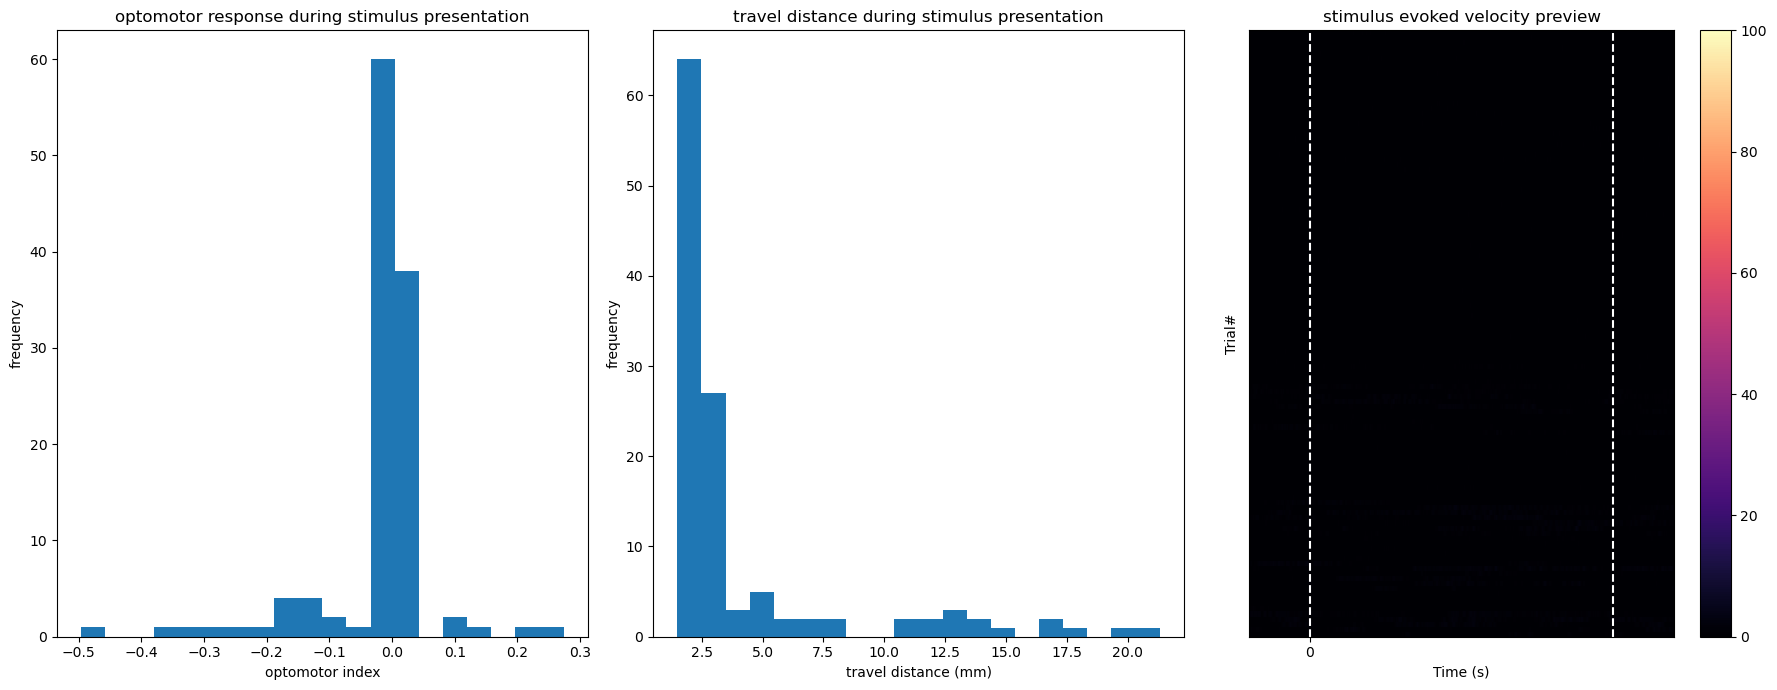

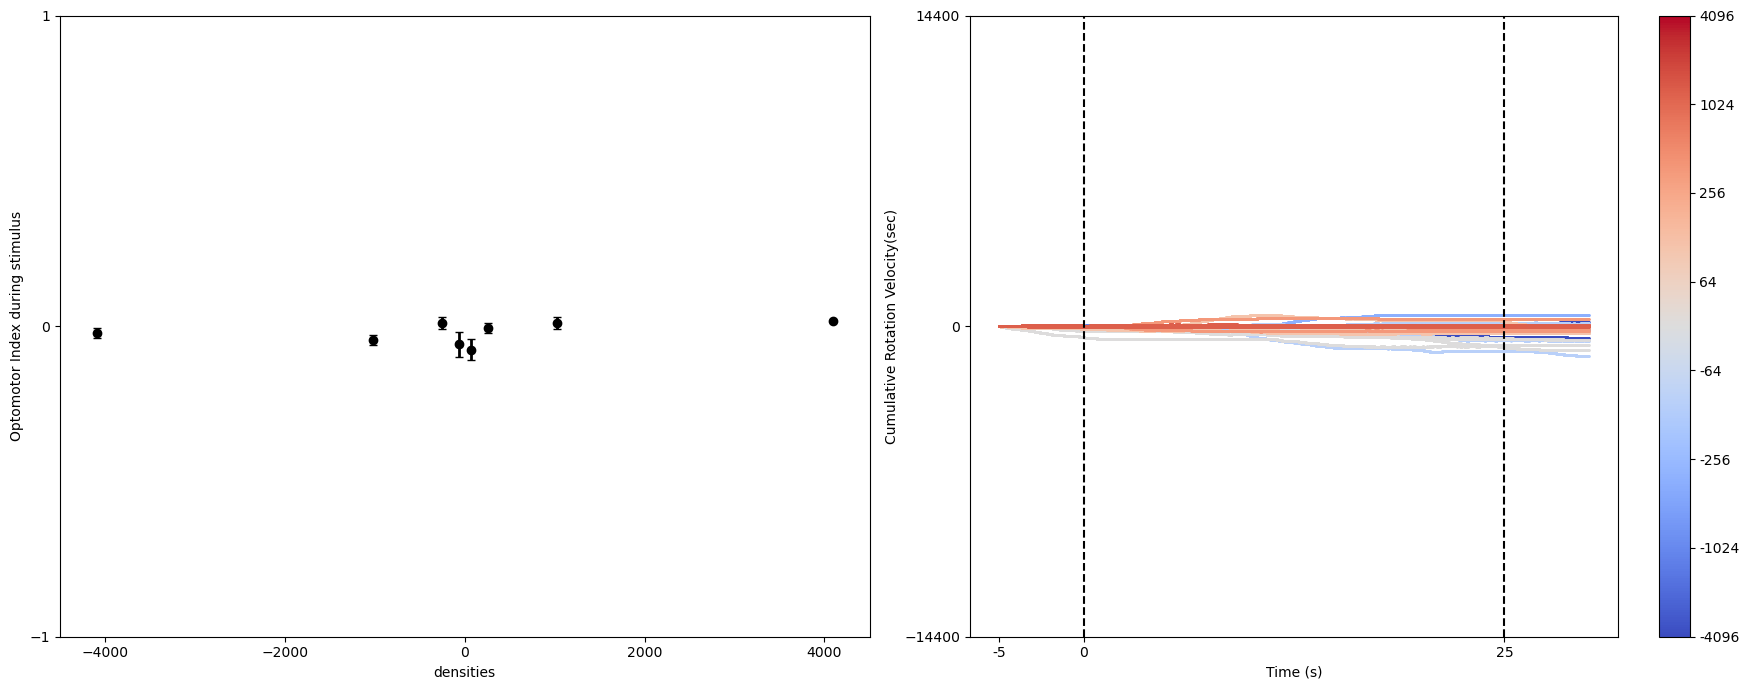

plotting data from -5 to 30
classify the behaviour into turning, running, straightwalk, turning_walk + follow and against trials
ready to plot graph with some data and decompose those lists


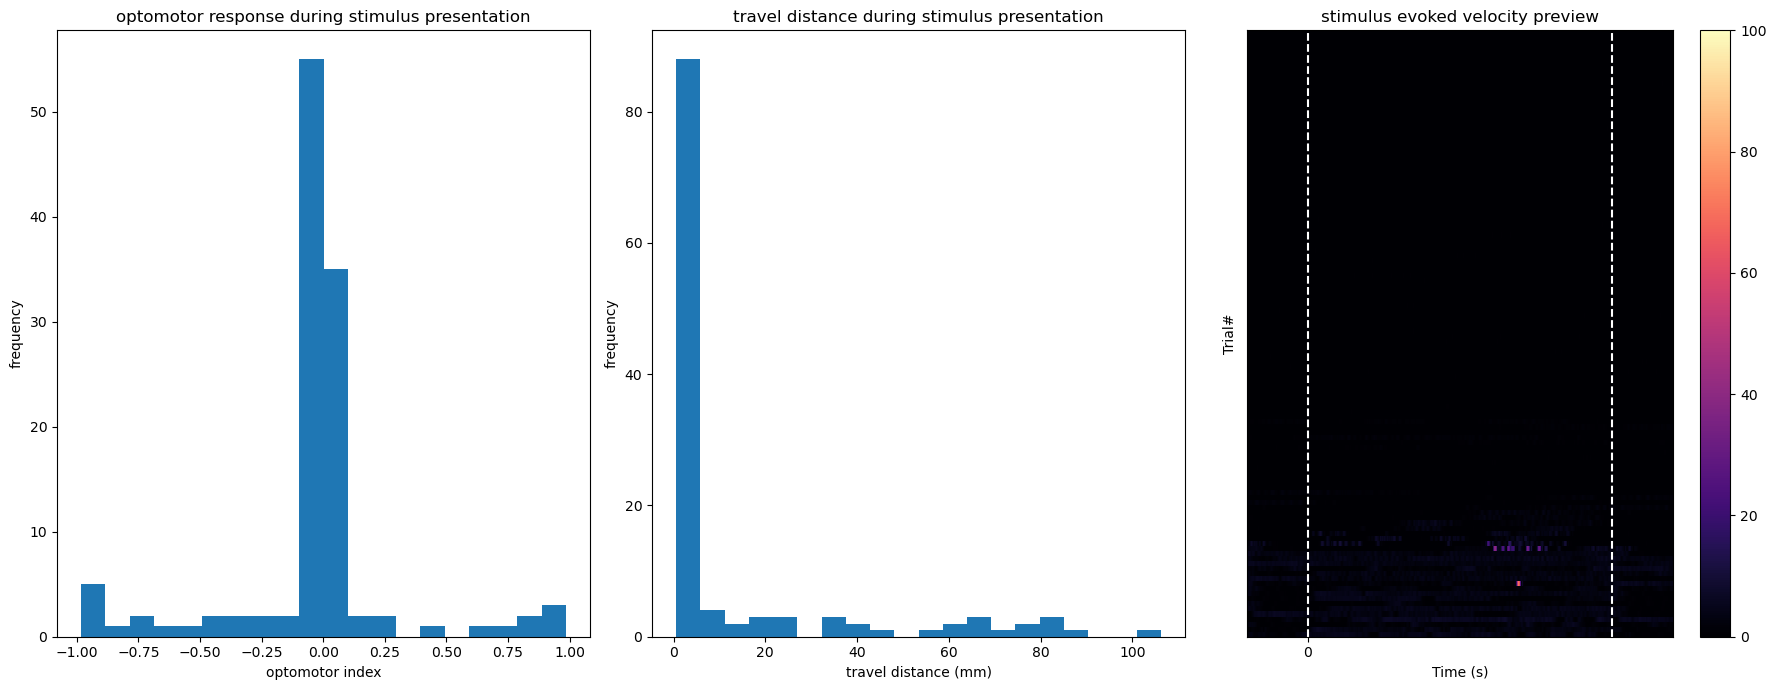

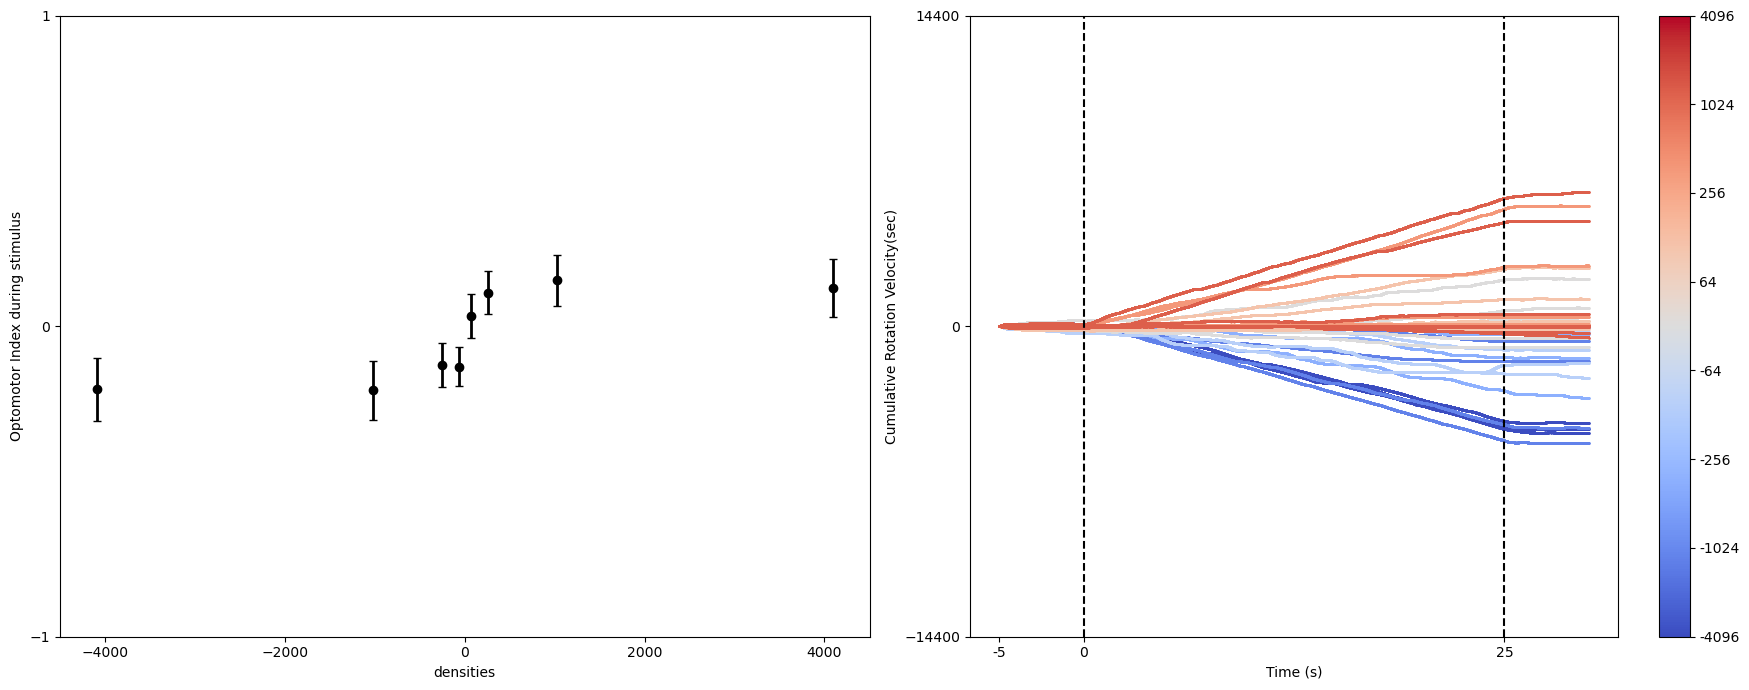

In [11]:
# because the import does not update the new version of python.
# Need to restart kernel 
output0_across_exp=[]
output1_across_exp=[]
output2_across_exp=[]
output3_across_exp=[]
output4_across_exp=[]
for this_dir in new_list:
    summary,speed,rotation,travel_distance_whole_session=main(this_dir,analysis_methods)
    output0_across_exp.append(summary)
    output1_across_exp.append(speed)
    output2_across_exp.append(rotation)
    output3_across_exp.append(travel_distance_whole_session)
    output4_across_exp.append(this_dir)


In [18]:
df=pd.DataFrame(pd.concat(output0_across_exp))

In [22]:
df

,opto_index_isi,opto_index,travel_distance_isi,travel_distance,stim_index,stim_type,optoxstim,file_path,growth_condition,ID
0,-0.022103,0.430794,0.358984,12.896410,0,256,110.283302,Z:/DATA/experiment_trackball_Optomotor/VCCball...,solitarious,0
1,0.509485,-0.021822,3.934771,13.628294,1,-1024,22.346056,Z:/DATA/experiment_trackball_Optomotor/VCCball...,solitarious,0
2,0.320070,-0.016072,1.175657,1.959473,2,-64,1.028599,Z:/DATA/experiment_trackball_Optomotor/VCCball...,solitarious,0
3,-0.060366,0.018957,0.408957,1.396237,3,64,1.213268,Z:/DATA/experiment_trackball_Optomotor/VCCball...,solitarious,0
4,-0.000939,0.028195,0.261720,3.069432,4,-4096,-115.487190,Z:/DATA/experiment_trackball_Optomotor/VCCball...,solitarious,0
...,...,...,...,...,...,...,...,...,...,...
115,-0.000072,0.006331,0.294817,1.227798,115,1024,6.483387,Z:/DATA/experiment_trackball_Optomotor/VCCball...,solitarious,31
116,-0.001250,-0.003141,0.221402,1.132018,116,-256,0.804096,Z:/DATA/experiment_trackball_Optomotor/VCCball...,solitarious,31
117,0.000003,0.003021,0.234763,1.146000,117,256,0.773252,Z:/DATA/experiment_trackball_Optomotor/VCCball...,solitarious,31
118,-0.005545,-0.006734,0.172116,1.398668,118,-4096,27.580843,Z:/DATA/experiment_trackball_Optomotor/VCCball...,solitarious,31


In [21]:
#output0_across_exp[13]
growth_condition='solitarious'
df['file_path'] = np.repeat(output4_across_exp,output0_across_exp[0].shape[0])
df['growth_condition'] = np.repeat(growth_condition,output0_across_exp[0].shape[0]*len(output0_across_exp))
df['ID'] = np.repeat(np.arange(len(output4_across_exp)),output0_across_exp[0].shape[0])


In [23]:
file_name=f"solitarious_database.csv"
df.to_csv(file_name)

Session 2.2: Analyse optomotor response with multi-engines

In [ ]:
##this cell start the multi-engines. Make sure to run only once
import time
import ipyparallel as ipp
def show_clusters():
    clusters = ipp.ClusterManager().load_clusters() 
    print("{:15} {:^10} {}".format("cluster_id", "state", "cluster_file")) 
    for c in clusters:
        cd = clusters[c].to_dict()
        cluster_id = cd['cluster']['cluster_id']
        controller_state = cd['controller']['state']['state']
        cluster_file = getattr(clusters[c], '_trait_values')['cluster_file']
        print("{:15} {:^10} {}".format(cluster_id, controller_state, cluster_file))
    return cluster_id

cluster = ipp.Cluster(n=6)
await cluster.start_cluster()
cluster_neuropc=show_clusters()

In [ ]:
##input cluster_id from previous cell
rc = ipp.Client(cluster_id=cluster_neuropc)

# Create a DirectView for parallel execution
dview = rc.direct_view()

# Define a function for parallel processing
def process_directory(thisDir, analysis_methods):
    from analyse_stimulus_evoked_response import main
    # Check if the H5 file (curated dataset) exists
    summary,speed,rotation = main(thisDir, analysis_methods)
    return (summary,speed,rotation)

# Define analysis_methods

# Use parallel execution to process directories
results = dview.map_sync(process_directory, dir_list, [analysis_methods] * len(dir_list))

# Initialize result lists
output0_across_exp=[]
output1_across_exp=[]
output2_across_exp=[]

# Collect and organize results
for result in results:
    if result is not None:
        summary,speed,rotation = result
        output0_across_exp.append(summary)
        output1_across_exp.append(speed)
        output2_across_exp.append(rotation)

# Now, you have the results collected in the respective lists

In [ ]:
rc.shutdown()

Session 2.3: Load existing dataset

In [30]:
path = 'optomotor_density_new.csv'
df = pd.read_csv(path,index_col=None)


,opto_index_isi,opto_index,travel_distance_isi,travel_distance,stim_index,stim_type,optoxstim,file_path,growth_condition,ID
0,-0.149330,0.516317,17.378906,17.806015,0,256,132.177063,Z:/DATA/experiment_trackball_Optomotor/VCCball...,gregarious,0
1,0.085175,-0.084262,0.978413,42.544403,1,-1024,86.284569,Z:/DATA/experiment_trackball_Optomotor/VCCball...,gregarious,0
2,-0.173750,0.394912,3.923198,36.456040,2,-64,-25.274395,Z:/DATA/experiment_trackball_Optomotor/VCCball...,gregarious,0
3,0.261237,0.628823,5.479281,44.682137,3,64,40.244686,Z:/DATA/experiment_trackball_Optomotor/VCCball...,gregarious,0
4,0.817667,-0.455472,23.159533,111.468960,4,-4096,1865.615234,Z:/DATA/experiment_trackball_Optomotor/VCCball...,gregarious,0
...,...,...,...,...,...,...,...,...,...,...
5995,-0.000072,0.006331,0.294817,1.227799,115,1024,6.483387,Z:/DATA/experiment_trackball_Optomotor/VCCball...,solitarious,31
5996,-0.001250,-0.003141,0.221402,1.132018,116,-256,0.804096,Z:/DATA/experiment_trackball_Optomotor/VCCball...,solitarious,31
5997,0.000003,0.003021,0.234763,1.146000,117,256,0.773252,Z:/DATA/experiment_trackball_Optomotor/VCCball...,solitarious,31
5998,-0.005545,-0.006734,0.172116,1.398668,118,-4096,27.580843,Z:/DATA/experiment_trackball_Optomotor/VCCball...,solitarious,31


In [38]:
df[df['travel_distance']>150]

,opto_index_isi,opto_index,travel_distance_isi,travel_distance,stim_index,stim_type,optoxstim,file_path,growth_condition,ID
1464,-0.531560,-0.848472,40.821650,201.11697,24,-64,54.302216,Z:/DATA/experiment_trackball_Optomotor/VCCball...,gregarious,12
1465,-0.886163,0.208654,41.634808,176.05904,25,64,13.353843,Z:/DATA/experiment_trackball_Optomotor/VCCball...,gregarious,12
2523,-0.368111,-0.271489,1.330696,167.18738,3,64,-17.375296,Z:/DATA/experiment_trackball_Optomotor/VCCball...,solitarious,3
2535,-0.799831,0.307511,3.357122,172.38623,15,256,78.722862,Z:/DATA/experiment_trackball_Optomotor/VCCball...,solitarious,3
2537,-0.934229,0.564113,8.456828,172.69539,17,256,144.413010,Z:/DATA/experiment_trackball_Optomotor/VCCball...,solitarious,3
2553,-0.651308,0.693473,30.631042,152.93384,33,1024,710.116455,Z:/DATA/experiment_trackball_Optomotor/VCCball...,solitarious,3
2557,0.113066,0.047491,0.654687,152.74063,37,256,12.157728,Z:/DATA/experiment_trackball_Optomotor/VCCball...,solitarious,3
2569,-0.096495,0.853544,44.741814,193.57297,49,256,218.507202,Z:/DATA/experiment_trackball_Optomotor/VCCball...,solitarious,3
3501,0.404068,-0.348720,7.792950,163.14258,21,64,-22.318108,Z:/DATA/experiment_trackball_Optomotor/VCCball...,solitarious,11
3602,-0.164890,0.238788,2.076987,623.53723,2,-64,-15.282441,Z:/DATA/experiment_trackball_Optomotor/VCCball...,solitarious,12


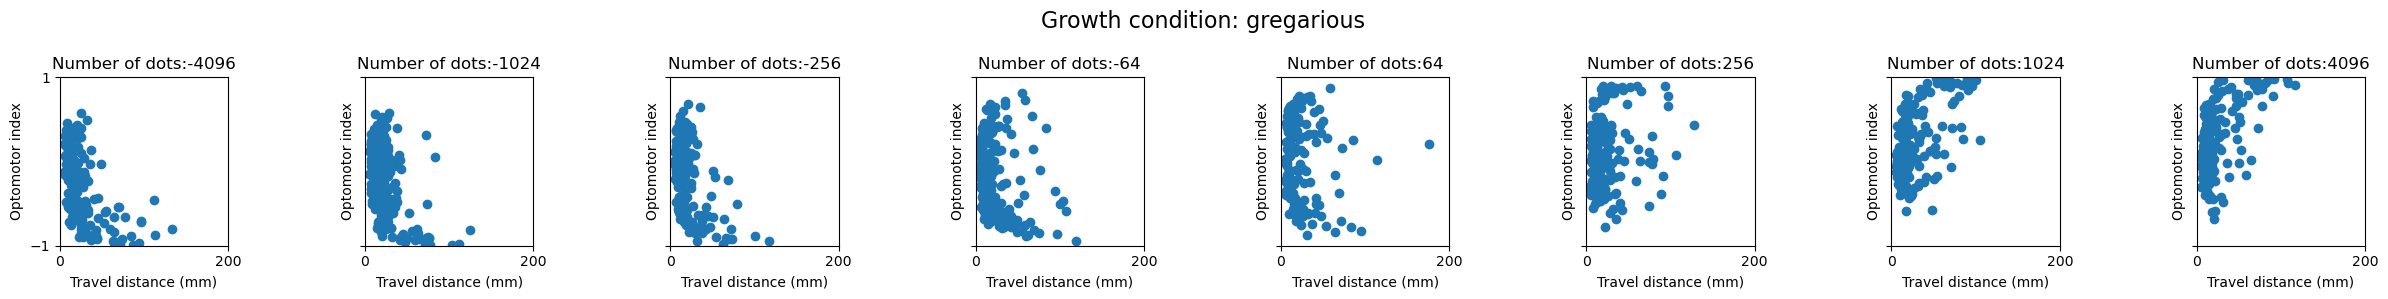

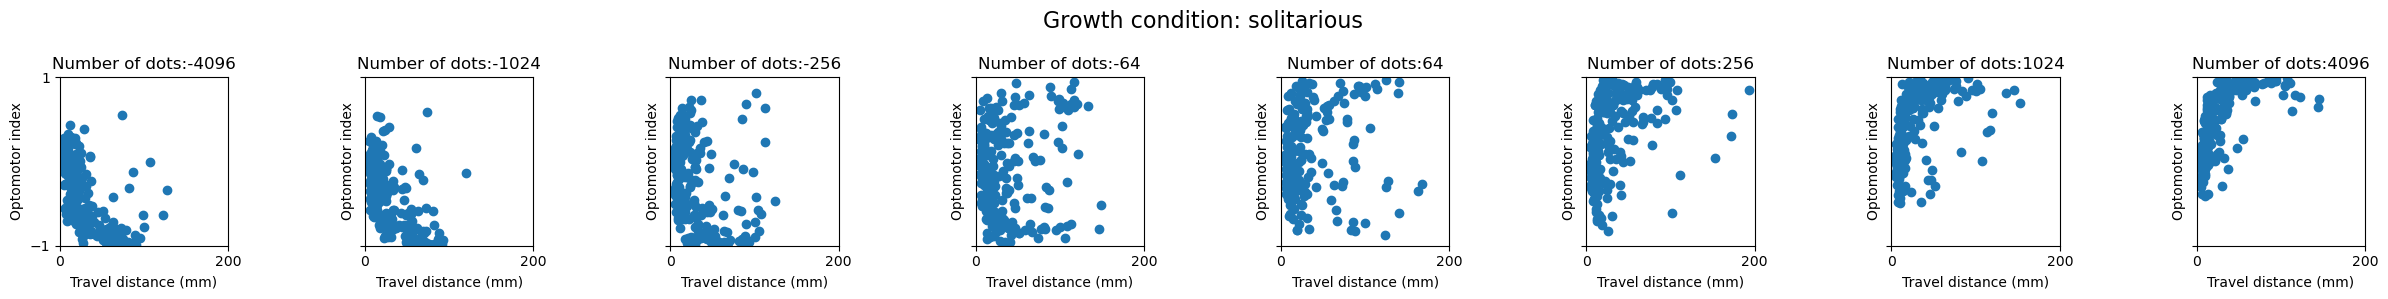

In [46]:
for this_group in df["growth_condition"].unique():
    d_con=df[(df["growth_condition"]==this_group) & (df["travel_distance"]<200)]
    fig, axes = plt.subplots(
        nrows=1, ncols=len(d_con["stim_type"].unique()), figsize=(25, 3), sharey=True,tight_layout=True
    )
    for this_stim, ax in zip(np.sort(d_con["stim_type"].unique()),axes.reshape(-1)):
        ax.scatter(d_con[(d_con["stim_type"]==this_stim) & (d_con["travel_distance"]>5)]["travel_distance"],d_con[(d_con["stim_type"]==this_stim)&(d_con["travel_distance"]>5)]["opto_index"])
        ax.set_xticks([0, 200])
        ax.set_yticks([-1, 1])
        ax.set_xlim([0, 200])
        ax.set_ylim([-1, 1])
        ax.set_box_aspect(1)
        ax.set_ylabel("Optomotor index")
        ax.set_xlabel("Travel distance (mm)")
        ax.set_title(f"Number of dots:{this_stim}")
    fig.suptitle(f"Growth condition: {this_group}", fontsize=16)
    fig_name=f"scatter_plot_{this_group}.png"
    fig.savefig(fig_name)

In [45]:
df[df['travel_distance']>150]['file_path'].values

array(['Z:/DATA/experiment_trackball_Optomotor/VCCball/L22069/220908/densities',
       'Z:/DATA/experiment_trackball_Optomotor/VCCball/L22069/220908/densities',
       'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23004/230218/densities',
       'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23004/230218/densities',
       'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23004/230218/densities',
       'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23004/230218/densities',
       'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23004/230218/densities',
       'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23004/230218/densities',
       'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23016/230328/densities',
       'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23017/230328/densities',
       'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23017/230328/densities',
       'Z:/DATA/experiment_trackball_Optomotor/VCCball/L23017/230328/densities',
       'Z:/DATA/experiment_t

In [ ]:
dfsel = df[df['travel_distance']>5]
#df.hist('Median speed')

In [ ]:
file_name=f"density_database_no_stationary.csv"
dfsel.to_csv(file_name)

In [ ]:
plt.hist(output3_across_exp,bins=range(0,10000,1000))

In [ ]:
init_frame=analysis_methods.get("interval_duration")*analysis_methods.get("frame_rate")
culz_stim_onset=test4[:,init_frame]
DF=pd.DataFrame(culz_stim_onset)
file_name=f"culz_onset4.csv"
DF.to_csv(file_name)

In [ ]:
init_frame=analysis_methods.get("interval_duration")*analysis_methods.get("frame_rate")
prestim_analyse=5
prestim_5_sec=init_frame-prestim_analyse*analysis_methods.get("frame_rate")

In [ ]:
culz_stim_onset=output2_arr[:,init_frame]
culz_stim_onset_5sec_before=output2_arr[:,init_frame-prestim_5_sec]
this_response=culz_stim_onset-culz_stim_onset_5sec_before
DF=pd.DataFrame(this_response)
file_name=f"culz_onset.csv"
DF.to_csv(file_name)

Session 3: plotting data

In [ ]:
visual_paradigm_name= analysis_methods.get("experiment_name")
colormap = np.array(analysis_methods.get("graph_colour_code"))
fig2, (ax3, ax4) = plt.subplots(
    nrows=1, ncols=2, figsize=(18, 7), tight_layout=True
)
for i in range(len(output0_across_exp)):
    this_animal = output0_across_exp[i]
    tmp=this_animal.groupby("stim_type").count()
    follow_count_coherence = tmp.index.values
    for j in range(len(this_animal.groupby("stim_type"))):
        this_coherence=follow_count_coherence[j]
        this_response = this_animal.loc[
            this_animal["stim_type"] == this_coherence, "opto_index"
        ].values
        # this_coherence = x_axis_value_running_trials[i]
        mean_response = np.mean(this_response, axis=0)
        sem_response = np.std(this_response, axis=0, ddof=1) / np.sqrt(
            this_response.shape[0]
        )
        ax3.errorbar(
            this_coherence,
            mean_response,
            yerr=sem_response,
            c=colormap[5],
            fmt="o",
            elinewidth=2,
            capsize=3,
        )
    ax3.set_ylim(-1, 1)
    ax3.set(
        yticks=[-1, 0, 1],
        ylabel="Optomotor Index",
        xlabel=visual_paradigm_name,)
    # ax4.scatter(follow_count_coherence, follow_count, c=colormap[0], marker="o")
    # ax4.set_ylim(0, 15)
    # ax4.set(
    #     yticks=[0, 15],
    #     ylabel="Follow response (count)",
    #     xticks=[100, 50, 0, -50, -100],
    #     xlabel="Coherence level (%)",
    # )
    ##following one dot (dot lifetime)
    ##memory part (30s)
    ##interval: rondot
    ##continous